# Stage 1: Univariate analysis (one variable at a time)

**Status (2026-10-25):** Stage 1 is under way. Section 1 (IP rights) profiles every core variable of its lens,
after five repairs (ADR 0012), and its first attachment, the parties (1.8.1, ADR 0013), with observations U1 to U21;
its other attachments are still to come. Section 5 (Australia over time) profiles every column of the timeline lens,
after one more repair (ADR 0014), with observations U22 to U30. Sections 2 to 4 have their data overviews, run on the
lenses as repaired before Stage 1 (ADR 0010 and 0011); their variable-by-variable sections are planned and marked as
such.

**Purpose.** Before relating any two things, understand each one on its own: what it measures, how complete it is,
its shape (typical values, spread, skew, outliers), and any quirks (placeholders, gaps, artefacts of how the data was
collected). Decisions made here (what to exclude, what to transform, how to group) are carried into Stages 2 and 3.

**What this notebook does not do.** It does not test relationships (Stage 2) or look at several variables together
(Stage 3), and it does not answer the research questions. It prepares the ground for them.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**U1**, **U2**, ...) and quote the numbers from
  the output cell directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires:
  *descriptive* (what the data shows), *observational* (an association that may have other explanations),
  *causal* (an effect, which needs a design this EDA does not have) or *projected* (an estimate of the future).
  Almost everything in the EDA is descriptive or observational.
- **Plain English first.** Technical terms are explained where they first appear and in [`GLOSSARY.md`](../../GLOSSARY.md).
- **Every chart names its source** underneath it.
- **Unit of analysis.** Each section works on one *lens*: a table with one row per thing being described. The lenses
  are listed below and defined in [`analysis/eda/build.py`](../eda/build.py); every column is described in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml).

| Lens | One row per | Rows |
|---|---|---|
| `rights` | IP right (patent, trade mark, design, plant breeder's right) | 4,368,006 |
| `firms` | ABN that appears in any IP, R&D, procurement or tax source | 398,450 |
| `regions` | Postal area | 2,641 |
| `national` | Country, year and indicator | 135,140 |
| `timeline` | Month, for Australia (January 1904 to September 2026) | 1,473 |

## Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from eda import bivariate as bi
from eda import build, data, load_lens, sql, style
from eda import multivariate as multi
from eda import univariate as uni
from matplotlib import dates as mdates

style.setup()

## 0. The corpus at a glance

What the five lenses are drawn from: every processed table in the corpus, from the profile in
`analysis/output/tables.csv` (built by `analysis/profile_corpus.py`).

In [2]:
tables = data.corpus_tables()
by_source = (
    tables.groupby("source")
    .agg(tables=("table", "size"), rows=("rows", "sum"), in_r2=("location", lambda s: (s == "r2").sum()))
    .sort_values("rows")
)
print(f"{len(tables)} tables from {len(by_source)} sources; {tables.rows.sum():,} rows in all")
largest = by_source.sort_values("rows", ascending=False).head(5)
largest.assign(**{"% of all rows": 100 * largest.rows / tables.rows.sum()})

162 tables from 41 sources; 317,792,796 rows in all


,tables,rows,in_r2,% of all rows
source,,,,
iprapid,11,100324501,7,31.57
tmlink,6,79004085,6,24.86
oecd,24,42264899,0,13.3
abr,1,20612369,1,6.486
iplord,2,9392762,1,2.956


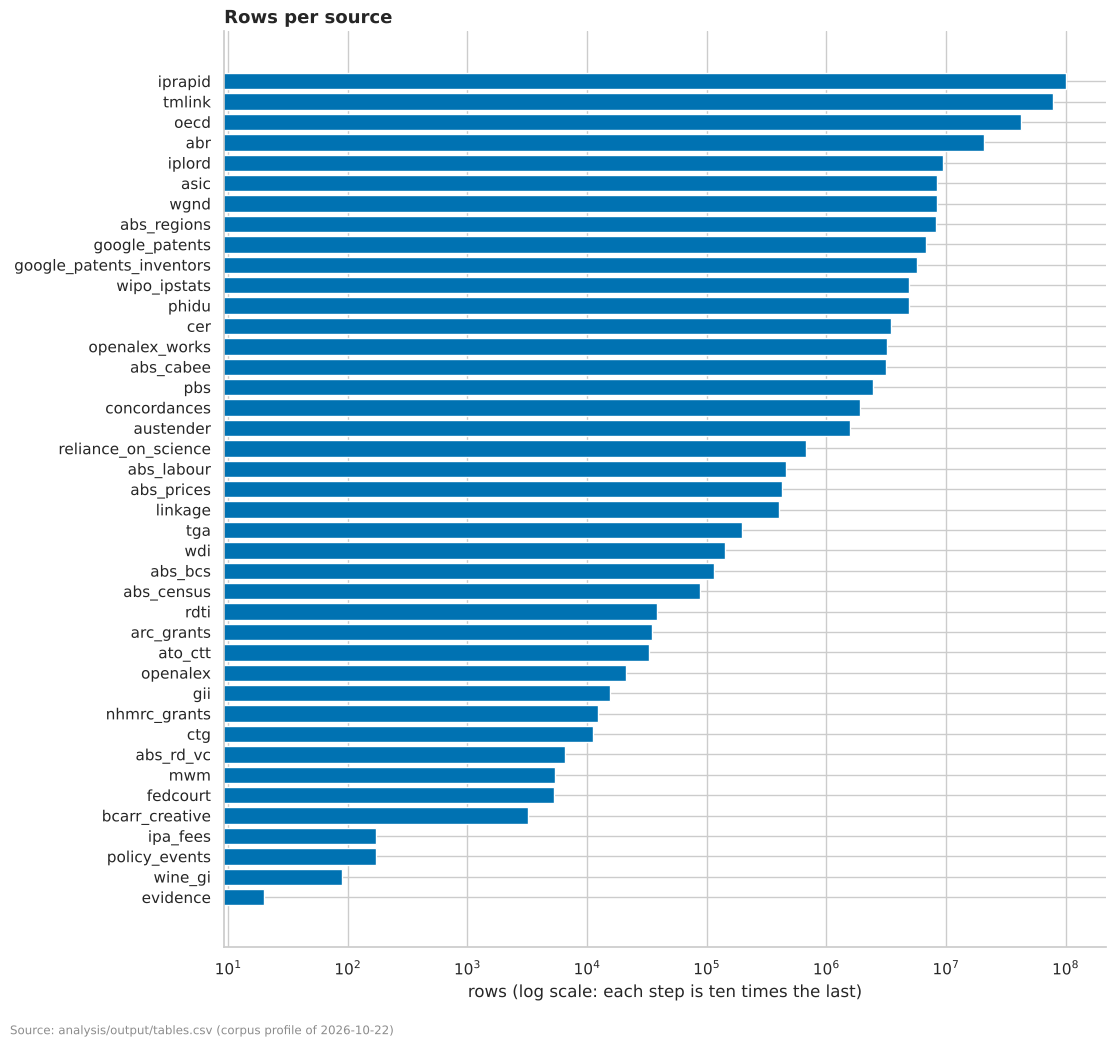

In [3]:
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(by_source.index, by_source.rows, color=style.MAIN)
ax.set_xscale("log")
ax.set_xlabel("rows (log scale: each step is ten times the last)")
ax.set_title("Rows per source")
style.source(fig, "analysis/output/tables.csv (corpus profile of 2026-10-22)")

#### Observation U0 (descriptive; a worked example of the format)

- **Size.** The corpus holds 152 tables from 38 sources: 314,742,745 rows in all.
- **Concentration.** Three sources hold 70.4% of the rows: IP RAPID (31.88%), TM-Link (25.1%) and the OECD panels
  (13.43%).
- **What this means for the EDA.** Row counts measure how much a source records, not how much it matters to the
  research questions. This notebook is therefore ordered by unit of analysis (rights, firms, places, countries), not
  by size, and the largest sources enter through the lenses built from them.

## 1. Lens: IP rights (one row per right)

Every patent, trade mark, design and plant breeder's right in IP Australia's IP RAPID data, from 1904 to October 2026.
Built from `iprapid/*_rights` and `iprapid/party`.

**Rules for this section** (from the plan):
- Standard patents lead. Provisional applications and second-tier patents are always shown apart from them, because a
  provisional is a placeholder that is never granted, and second-tier patents are a different, cheaper right.
- Shares of Australian applicants are given only among rights whose origin is known, and only in years when fewer than
  5% of that type's rights are of unknown origin (from the 1990s for patents).
- FY2027 (July to mid-October 2026) is a partial year, so it is left out of yearly counts and charts.

### 1.0 Data overview and sanity checks

In [4]:
rights = load_lens("rights")
print(f"{len(rights):,} rows, {rights.shape[1]} columns")
with pd.option_context("display.max_rows", 100):
    display(uni.overview(rights, "rights"))

4,368,006 rows, 41 columns


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
application_number,Application number,id,str,100,4368006,NaN,NaN,NaN
ip_right_type,Type of right,category,str,100,4,NaN,NaN,trade_mark (53.5%)
ip_right_sub_type,Sub-type of right,category,str,100,12,NaN,NaN,trade_mark (53.3%)
patent_type,Type of patent,category,str,40.12,3,NaN,NaN,standard (82.2%)
status,Current status,category,str,100,27,NaN,NaN,ceased (28.1%)
application_date,Application date,date,datetime64[s],98.58,37923,1904-02-13,2026-10-17,2013-04-12 (0.0%)
earliest_filed_date,Earliest filing date,date,datetime64[s],98.58,38559,1904-02-13,2026-10-16,2021-08-25 (0.0%)
filing_fy,Financial year of application,year,Int64,98.58,124,1904,2027,2026 (3.5%)
priority_date,Priority date,date,datetime64[s],98.59,39352,1904-02-13,2026-10-16,2013-03-15 (0.1%)


Rows that repeat a right (same type and application number): 0


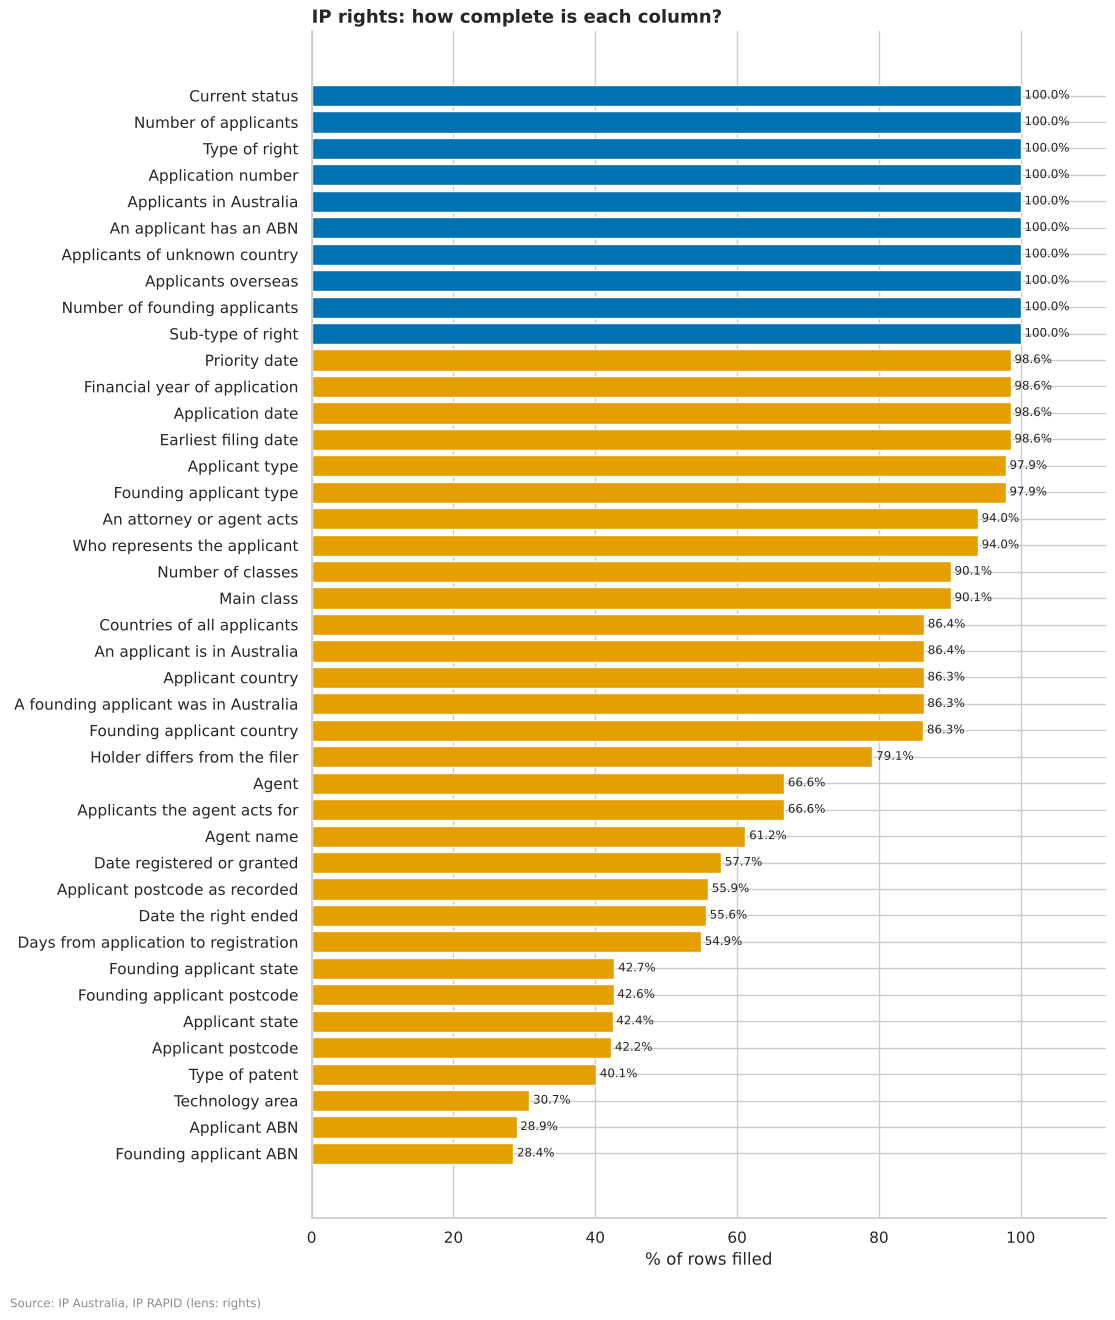

In [5]:
dupes = sql("SELECT count(*) - count(DISTINCT (ip_right_type, application_number)) AS n FROM {lens/rights}")
print(f"Rows that repeat a right (same type and application number): {dupes.n[0]:,}")
fig = uni.missing(rights, "rights", title="IP rights: how complete is each column?")
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

#### Repairs made before this section (ADR 0012)

Five quirks found while profiling were repaired in the lens (`analysis/eda/build.py`) before the profiles below. The
next two cells show the evidence for four of them from IP RAPID's own tables, so it stays on the page; the fifth (the
applicant's state) is shown in 1.7, where it is used.

In [6]:
# Placeholder dates, trade mark registrations dated at filing, and the technology area, in IP RAPID as published
raw = " UNION ALL ".join(
    f"SELECT '{t}' AS ip_right_type, application_date, gained_registration_status_date AS registered, "
    f"deemed_retired_date AS retired, main_class, main_area FROM {{iprapid/{t}_rights}}"
    for t in ("patent", "trade_mark", "design", "pbr")
)
sql(f"""
    SELECT ip_right_type,
           count(*) FILTER (retired = DATE '1970-01-01') AS "ended on 1 Jan 1970",
           min(application_date) FILTER (retired = DATE '1970-01-01') AS "earliest filed of those",
           count(*) FILTER (year(registered) < 1904) AS "registered before 1904",
           count(*) FILTER (registered < DATE '1986-01-01') AS "registered before 1986",
           count(*) FILTER (registered < DATE '1986-01-01' AND registered = application_date)
               AS "... on the day filed",
           count(*) FILTER (main_area IS NOT NULL) AS "with a technology area",
           count(*) FILTER (main_area = main_class) AS "... equal to the main class"
    FROM ({raw}) GROUP BY 1 ORDER BY 1
""")

,ip_right_type,ended on 1 Jan 1970,earliest filed of those,registered before 1904,registered before 1986,... on the day filed,with a technology area,... equal to the main class
0,design,3,2020-03-03,0,9811,10,248748,248748
1,patent,0,NaT,0,23555,0,1341352,0
2,pbr,0,NaT,0,0,0,0,0
3,trade_mark,1279,2013-07-18,1,122980,121207,2335057,2335057


In [7]:
# IP RAPID's "agent" is the address for service. How often is that the applicant itself? Rights filed FY2017 to FY2026
# with a known origin, provisionals aside (none has an agent). The last column counts only agents who act for at least
# five different applicants across the register: a lower bound for professional attorneys.
sql("""
    WITH party AS (
        SELECT ip_right_type, application_number, party_id, party_role_category,
               regexp_replace(lower(party_name), '[^a-z0-9]', '', 'g') AS name
        FROM {iprapid/party} WHERE party_role_category IN ('applicant', 'owner', 'applicant_agent')
    ),
    agent AS (SELECT * FROM party WHERE party_role_category = 'applicant_agent'),
    any_agent AS (SELECT DISTINCT ip_right_type, application_number FROM agent),
    applicant AS (SELECT * FROM party WHERE party_role_category <> 'applicant_agent'),
    other AS (  -- agents who are not one of the right's applicants or owners
        SELECT g.* FROM agent g ANTI JOIN applicant a
            ON a.ip_right_type = g.ip_right_type AND a.application_number = g.application_number
           AND (a.party_id = g.party_id OR a.name = g.name)
    ),
    clients AS (
        SELECT o.party_id, count(DISTINCT a.party_id) AS clients
        FROM other o JOIN applicant a USING (ip_right_type, application_number) GROUP BY 1
    ),
    per_right AS (
        SELECT ip_right_type, application_number, max(c.clients) AS clients
        FROM other JOIN clients c USING (party_id) GROUP BY 1, 2
    ),
    r AS (
        SELECT ip_right_type, application_number, australian_applicant, has_agent FROM {lens/rights}
        WHERE filing_fy BETWEEN 2017 AND 2026 AND patent_type IS DISTINCT FROM 'provisional'
          AND australian_applicant IS NOT NULL
    )
    SELECT r.ip_right_type, CASE WHEN australian_applicant THEN 'Australian' ELSE 'overseas' END AS applicant,
           count(*) AS rights,
           100 * avg((g.application_number IS NOT NULL)::int) AS "% with any agent (IP RAPID's flag)",
           100 * avg(has_agent::int) AS "% with an agent not the applicant (lens)",
           100 * avg(coalesce(p.clients >= 5, false)::int) AS "% with an agent of 5+ applicants"
    FROM r LEFT JOIN per_right p USING (ip_right_type, application_number)
    LEFT JOIN any_agent g USING (ip_right_type, application_number)
    GROUP BY 1, 2 ORDER BY 1, 2
""")

,ip_right_type,applicant,rights,% with any agent (IP RAPID's flag),% with an agent not the applicant (lens),% with an agent of 5+ applicants
0,design,Australian,23926,100,71.65,69.25
1,design,overseas,55694,99.94,98.32,95.38
2,patent,Australian,33374,93.31,82.62,80.6
3,patent,overseas,292109,99.09,98.69,98.26
4,pbr,Australian,1354,52.22,41.21,24.37
5,pbr,overseas,1738,97.81,96.55,59.09
6,trade_mark,Australian,490674,100,57.02,49.52
7,trade_mark,overseas,340948,100,96.27,88.19


In [8]:
# Every date column: its range, its most common day, and any day after the corpus was built (22 October 2026)
dates = ["application_date", "earliest_filed_date", "priority_date", "registered_date", "retired_date"]
summary = {}
for c in dates:
    top = rights[c].value_counts().head(1)
    summary[style.label("rights", c)] = {
        "% filled": 100 * rights[c].notna().mean(),
        "earliest": f"{rights[c].min():%Y-%m-%d}",
        "latest": f"{rights[c].max():%Y-%m-%d}",
        "most common day": f"{top.index[0]:%Y-%m-%d}",
        "rights that day": int(top.iloc[0]),
        "after 22 Oct 2026": int((rights[c] > "2026-10-22").sum()),
    }
events = sql("SELECT id, date FROM {policy_events/events} WHERE id IN ('raising-the-bar', 'innovation-patent-closed')")
print("Policy changes beside two of the most common days:", dict(zip(events.id, events.date.astype(str), strict=True)))
pd.DataFrame(summary).T

Policy changes beside two of the most common days: {'raising-the-bar': '2013-04-15', 'innovation-patent-closed': '2021-08-26'}


,% filled,earliest,latest,most common day,rights that day,after 22 Oct 2026
Application date,98.58,1904-02-13,2026-10-17,2013-04-12,1856,0
Earliest filing date,98.58,1904-02-13,2026-10-16,2021-08-25,1342,0
Priority date,98.59,1904-02-13,2026-10-16,2013-03-15,2827,0
Date registered or granted,57.74,1906-07-02,2026-10-16,2016-01-15,3416,0
Date the right ended,55.6,1907-12-19,2029-04-27,1995-04-06,4019,14


In [9]:
# Rights with no application date: what else is known about them?
sql("""
    SELECT coalesce(patent_type, ip_right_type) AS "type of right", count(*) AS "no application date",
           count(*) FILTER (australian_applicant IS NULL) AS "origin unknown",
           count(*) FILTER (status = 'unknown') AS "status unknown",
           count(*) FILTER (registered_date IS NOT NULL) AS "ever registered",
           count(*) FILTER (priority_date IS NOT NULL) AS "with a priority date"
    FROM {lens/rights} WHERE application_date IS NULL GROUP BY 1 ORDER BY 2 DESC
""")

,type of right,no application date,origin unknown,status unknown,ever registered,with a priority date
0,standard,50488,50442,49737,1,25
1,design,11143,11126,0,15,49
2,second_tier,213,2,0,202,3
3,provisional,10,0,0,0,0
4,pbr,6,4,0,0,6
5,trade_mark,1,0,0,0,0


#### Observations from the overview
**U1 (descriptive). One row per right, complete where it should be.**
- The lens holds 4,368,006 rights in 41 columns: 29 core columns, profiled in 1.0 to 1.7, and 12 from the parties
  attachment (1.8.1). No right appears twice (0 rows repeat a type and application number).
- Type, sub-type, status, the applicant counts and `has_abn` are 100% filled. The application date is 98.58% filled,
  the registration date 57.74% (it is empty when a right was never registered) and the end date 55.6%.
- The emptiest columns are empty by design: the type of patent (40.12%, patents only), the technology area (30.71%,
  patents only), the applicant's state and postcode (42.44% and 42.25%, mostly Australian first applicants) and the
  ABN (28.89%).
- Origin (`australian_applicant`) is known for 86.37% of rights.

**U2 (descriptive). Five repairs, made before the profiles below (ADR 0012).** The evidence for each is in IP RAPID's
own tables above (the state's is in 1.7).
1. **A placeholder end date.** 1,282 rights (1,279 trade marks and 3 designs) "ended" on 1 January 1970, though the
   earliest of them was filed on 18 July 2013 (trade marks) or 3 March 2020 (designs). It is the zero of computer
   dates standing in for an unknown date, so it is now empty.
2. **A registration before the register began.** One trade mark is registered before 1904, earlier than the
   register's first application (13 February 1904). Now empty.
3. **Trade marks registered at filing.** Of the 122,980 trade marks registered before 1986, 121,207 (98.6%) were
   registered on the day they were filed: IP RAPID holds only their filing date, as the timeline found (ADR 0010).
   Their days to registration, almost always 0, are now empty; the registration date itself is kept.
4. **A technology area that was really a class.** For all 2,335,057 trade marks and 248,748 designs with a
   "technology area", it equals the main class: the Nice or Locarno class, repeated. It is now kept for patents only.
5. **Attorneys.** IP RAPID's "agent" is the *address for service*. It names one for 100% of trade marks and of
   Australian applicants' designs, but for Australian applicants it is often the applicant itself. Counting only an
   agent who is not one of the right's applicants, attorney use by Australian applicants (FY2017 to FY2026) is 57.02%
   for trade marks, 71.65% for designs, 82.62% for patents and 41.21% for plant breeder's rights. For overseas
   applicants it barely changes (96.27% to 98.69% for trade marks, designs and patents). Counting only agents who act
   for five or more different applicants gives 49.52% for Australian trade marks, so the repaired flag may still
   include some agents who are not attorneys (a director, say, or a related business): up to about 8 points for
   Australian trade marks.

**U3 (descriptive). Dates: two rushes, a few odd end dates, and 61,854 rights that cannot be placed in time.**
- Applications run from 13 February 1904 to 17 October 2026.
- The most common application date is 12 April 2013 (1,856 rights), the Friday before the Raising the Bar reforms
  took effect (15 April 2013). The most common earliest filing date is 25 August 2021 (1,342 rights), the day before
  innovation patents closed (26 August 2021). Both are rushes to file before a rule changed; Stage 2 measures them.
- 14 end dates fall after the corpus was built (22 October 2026), the latest on 27 April 2029. They are left as
  recorded; they are too few to matter.
- 50,711 patents and 11,143 designs have no application date. Of the patents, 50,488 are standard patents, almost all
  of unknown origin (50,442) and unknown status (49,737); 203 were ever registered (202 of them second-tier). Of the
  designs, 11,126 are of unknown origin and 15 were registered. They are old records (1.3: the status "unknown" belongs
  to patents filed before FY2000) that cannot be placed in time, so yearly counts leave them out: 2.9% of patents and
  4.1% of designs.

### 1.1 Type and sub-type of right

**Informs:** Q1, Q2. **Helpers:** `sql`, `uni.counts`.

- [x] Counts and shares by type and sub-type.
- [x] Shares by `patent_type`. Settled (ADR 0009): standard, provisional and second-tier patents are counted apart,
  and headline figures use standard patents.

In [10]:
types = sql("""
    SELECT ip_right_type, patent_type, ip_right_sub_type, count(*) AS rights,
           min(filing_fy) AS first_fy, max(filing_fy) AS last_fy
    FROM {lens/rights} GROUP BY ALL ORDER BY 1, rights DESC
""")
types["% of all rights"] = 100 * types.rights / types.rights.sum()
types["% of its type"] = 100 * types.rights / types.groupby("ip_right_type").rights.transform("sum")
types

,ip_right_type,patent_type,ip_right_sub_type,rights,first_fy,last_fy,% of all rights,% of its type
0,design,NaN,design,268782,1972,2027,6.153,100
1,patent,standard,standard_complete,1439947,1904,2027,32.97,82.17
2,patent,provisional,provisional,264024,1972,2027,6.044,15.07
3,patent,second_tier,innovation,41898,1999,2027,0.9592,2.391
4,patent,second_tier,petty,6559,1980,2001,0.1502,0.3743
5,pbr,NaN,pbr,11732,1988,2027,0.2686,100
6,trade_mark,NaN,trade_mark,2327933,1907,2027,53.3,99.69
7,trade_mark,NaN,certification,3033,1910,2027,0.06944,0.1299
8,trade_mark,NaN,collective,2594,1996,2027,0.05939,0.1111
9,trade_mark,NaN,defensive,1456,1959,2027,0.03333,0.06235


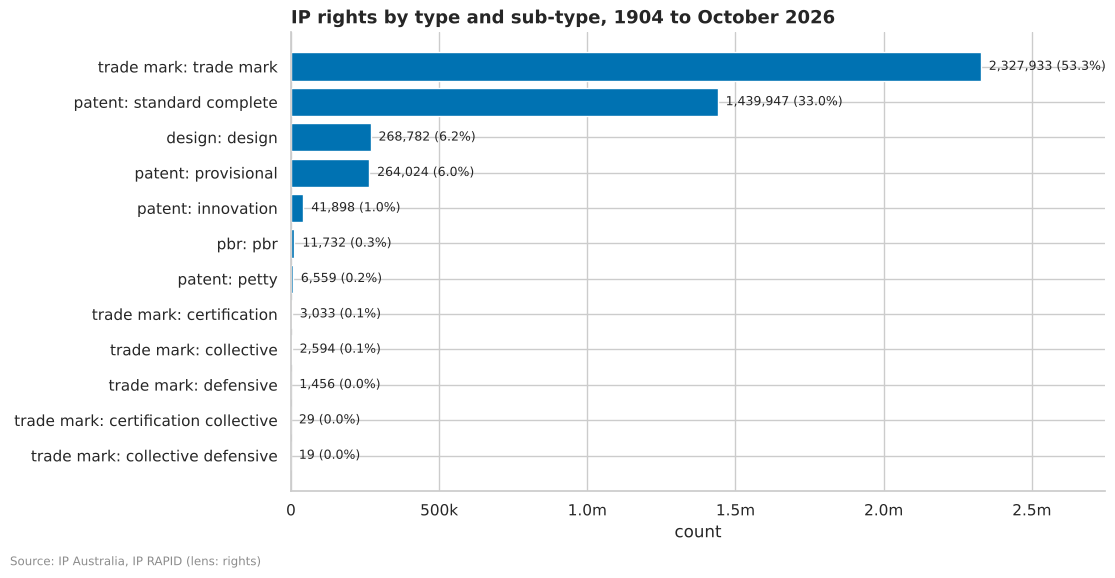

In [11]:
kind = rights.ip_right_type.str.replace("_", " ") + ": " + rights.ip_right_sub_type.str.replace("_", " ")
fig = uni.counts(kind, top=12, title="IP rights by type and sub-type, 1904 to October 2026")
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

#### Observations
**U4 (descriptive). Trade marks are most rights; standard patents are most patents.**
- Trade marks are 53.5% of all rights (2,335,064), patents 40.12%, designs 6.153% (268,782) and plant breeder's rights
  0.2686% (11,732).
- Of patents, 82.17% are standard (1,439,947), 15.07% provisional applications (264,024) and 2.77% second-tier
  (41,898 innovation and 6,559 petty patents).
- Petty patents run from FY1980 to FY2001 and innovation patents from FY1999. Innovation patents still appear in
  FY2027: divisionals and conversions of earlier applications, which the transitional rules allow (ADR 0010).
- Trade marks other than ordinary ones are rare: 3,033 certification, 2,594 collective and 1,456 defensive marks, and
  two combined sub-types since FY2020 and FY2022 (29 and 19 marks).
- **Decision:** a count of "rights" across types is mostly a count of trade marks, so totals are always given by type,
  and patent headlines use standard patents.

### 1.2 Applications over time (`filing_fy`)

**Informs:** Q1, Q4. **Helpers:** `sql`, matplotlib small multiples.

- [x] Applications per financial year, by type, from Australian, overseas and origin-unknown applicants.
- [x] Check that recent years are complete (FY2025 and FY2026 against earlier years).
- [x] Australian applicants' share of rights of known origin, in the years when origin is recorded.
- [x] The rise in provisional applications in FY2026 (a lead from ADR 0010).
- [x] Known breaks (the end of innovation patents and the other policy changes) are profiled in the timeline section
  (5.4, U28); fee changes wait for the fee history (R3).

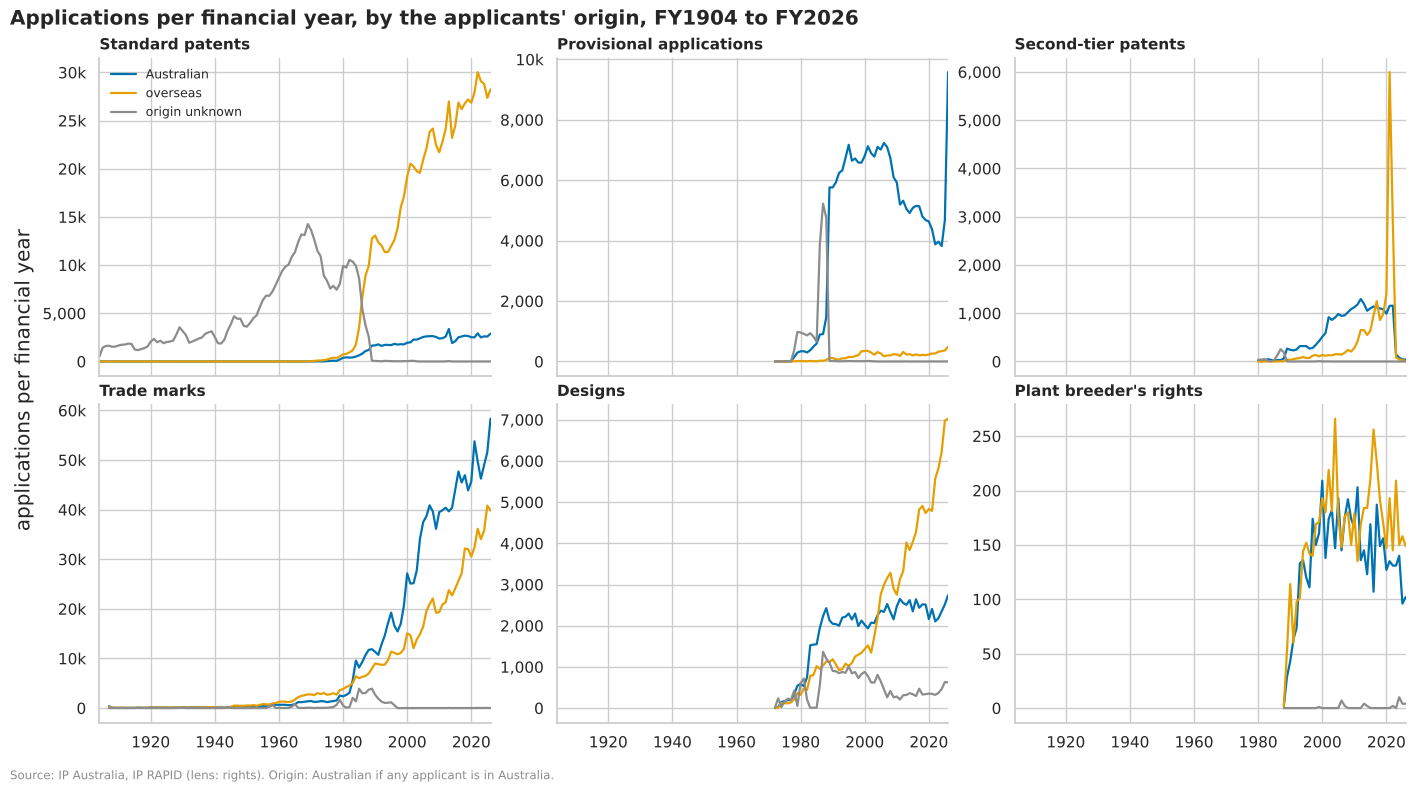

In [12]:
# Applications per financial year, by type and origin (every year the register holds; FY2027 kept here, left out below)
TYPES = {
    "standard": "Standard patents",
    "provisional": "Provisional applications",
    "second_tier": "Second-tier patents",
    "trade_mark": "Trade marks",
    "design": "Designs",
    "pbr": "Plant breeder's rights",
}
TYPE_COLOURS = dict(zip(TYPES, [style.PALETTE[i] for i in (0, 4, 5, 1, 2, 3)], strict=True))
ORIGIN_COLOURS = {"Australian": style.MAIN, "overseas": style.ACCENT, "origin unknown": style.MUTED}
by_fy = sql("""
    SELECT filing_fy, coalesce(patent_type, ip_right_type) AS t,
           CASE WHEN australian_applicant THEN 'Australian' WHEN NOT australian_applicant THEN 'overseas'
                ELSE 'origin unknown' END AS origin,
           count(*) AS n
    FROM {lens/rights} WHERE filing_fy IS NOT NULL GROUP BY ALL
""")
full = by_fy[by_fy.filing_fy <= 2026]

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, (t, name) in zip(axes.flat, TYPES.items(), strict=True):
    d = full[full.t == t].pivot_table(index="filing_fy", columns="origin", values="n", aggfunc="sum", fill_value=0)
    for origin, colour in ORIGIN_COLOURS.items():
        if origin in d and d[origin].sum() > 0:
            ax.plot(d.index, d[origin], color=colour, lw=1.6, label=origin)
    ax.set_title(name, fontsize=11)
    ax.set_xlim(1904, 2026)
    style.thousands(ax)
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.supylabel("applications per financial year")
fig.suptitle(
    "Applications per financial year, by the applicants' origin, FY1904 to FY2026", x=0, ha="left", fontweight="bold"
)
style.source(fig, "IP Australia, IP RAPID (lens: rights). Origin: Australian if any applicant is in Australia.")

In [13]:
# Are the latest years complete? Applications per year by type, FY2017 to FY2027 (FY2027: July to mid-October 2026)
recent = by_fy[by_fy.filing_fy >= 2017].pivot_table(index="filing_fy", columns="t", values="n", aggfunc="sum")
recent = recent[list(TYPES)].rename(columns=TYPES)
recent.index = [f"FY{y}" + (" (partial)" if y == 2027 else "") for y in recent.index]
recent

t,Standard patents,Provisional applications,Second-tier patents,Trade marks,Designs,Plant breeder's rights
FY2017,28798,5343,2374,72652,7727,413
FY2018,29470,5014,1960,79147,7756,340
FY2019,29846,4890,2063,75946,7585,326
FY2020,29376,4865,2389,76221,7347,274
FY2021,30443,4641,7150,86178,7540,328
FY2022,32960,4143,4073,85876,7996,278
FY2023,31596,4292,232,80348,8370,340
FY2024,31431,4164,123,84753,9030,300
FY2025,29950,5047,68,92470,10126,258
FY2026,31136,10069,52,98189,10388,255


% of unknown origin, by type and financial year (selected years)
t          Standard patents  Provisional applications  Second-tier patents  Trade marks  Designs  Plant breeder's rights
filing_fy                                                                                                               
1990                    0.4                       0.3                  0.4         11.7     21.8                       0
1995                    0.3                       0.2                    0          3.6     23.3                       0
2000                    0.2                       0.2                  0.2            0     20.3                       0
2005                      0                         0                    0            0     11.3                       0
2010                      0                         0                    0            0      5.1                       0
2015                      0                         0                    0            0 

t,Standard patents,Provisional applications,Second-tier patents,Trade marks,Designs,Plant breeder's rights
filing_fy,,,,,,
1990,11.3,98.1,87.4,NaN,NaN,27.4
1995,12.4,98,81.6,62.9,NaN,44.1
2000,9.2,95.2,79.2,64.3,NaN,52
2005,10.8,96.4,86.7,69.5,NaN,52.3
2010,9.9,96.2,80,67.1,NaN,48.1
2015,7.9,96.2,63.2,64.6,NaN,44.6
2018,9.1,95.7,56.1,59.3,33.9,43.8
2020,8.6,95.3,41.5,59.9,30.9,46.4
2021,8.2,94.3,16.1,62.4,33.5,41.2


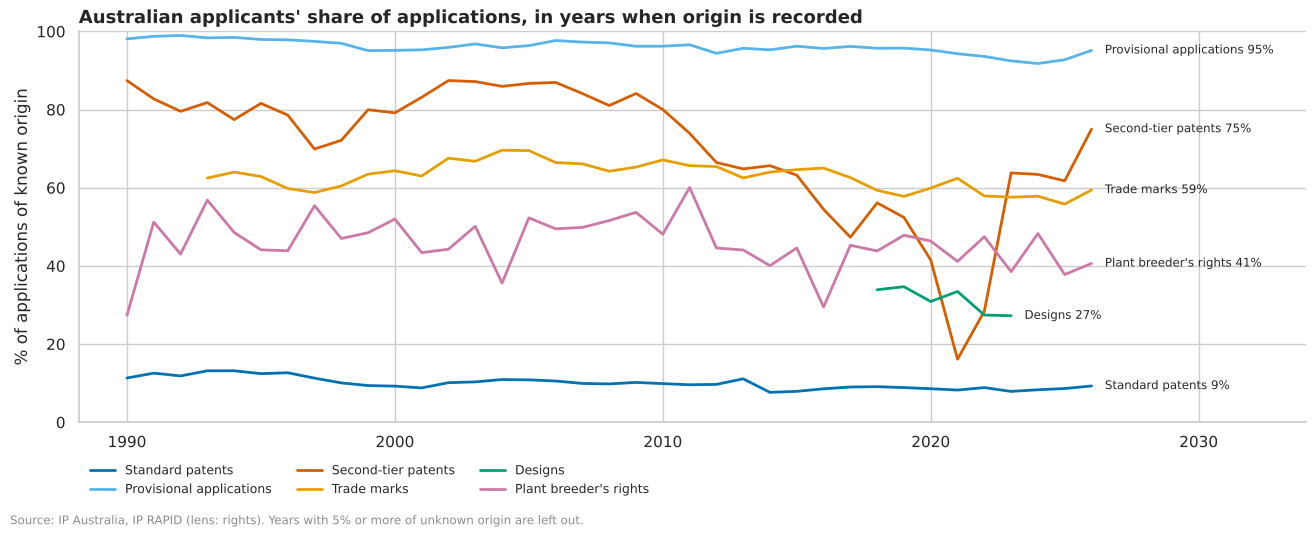

In [14]:
# Australian applicants' share of each type's rights of known origin, from FY1990, in the years when fewer than 5% are
# of unknown origin
share = full[full.filing_fy >= 1990].pivot_table(
    index=["t", "filing_fy"], columns="origin", values="n", aggfunc="sum", fill_value=0
)
share["% origin unknown"] = 100 * share["origin unknown"] / share.sum(axis=1)
share["% Australian"] = 100 * share.Australian / (share.Australian + share.overseas)
recorded = share[share["% origin unknown"] < 5].reset_index()

fig, ax = plt.subplots(figsize=(13, 5))
for t, name in TYPES.items():
    d = recorded[recorded.t == t].set_index("filing_fy")["% Australian"]
    d = d.reindex(range(d.index.min(), d.index.max() + 1))  # a gap where a year has too many unknowns
    ax.plot(d.index, d, color=TYPE_COLOURS[t], lw=2, label=name)
    ax.text(d.index[-1] + 0.5, d.iloc[-1], f"{name} {d.iloc[-1]:.0f}%", va="center", fontsize=8.5)
ax.set_ylim(0, 100)
ax.set_xlim(None, 2034)
ax.set_ylabel("% of applications of known origin")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
ax.set_title("Australian applicants' share of applications, in years when origin is recorded")
style.source(fig, "IP Australia, IP RAPID (lens: rights). Years with 5% or more of unknown origin are left out.")
years = [1990, 1995, 2000, 2005, 2010, 2015, 2018, 2020, 2021, 2022, 2024, 2025, 2026]
unknown = share["% origin unknown"].unstack("t")[list(TYPES)].rename(columns=TYPES)
print("% of unknown origin, by type and financial year (selected years)")
print(unknown.loc[years].round(1).to_string())
print()
print("% Australian among applications of known origin (empty where 5% or more are of unknown origin)")
australian = share["% Australian"].unstack("t")[list(TYPES)].rename(columns=TYPES)
australian.where(unknown < 5).loc[years].round(1)

applicant_type,individual,not recorded,organisation,total
2024-03-01,101,NaN,244,345
2025-03-01,181,NaN,300,481
2026-03-01,740,NaN,534,"1,274"
2026-04-01,721,1,509,"1,231"
2026-09-01,333,NaN,417,750


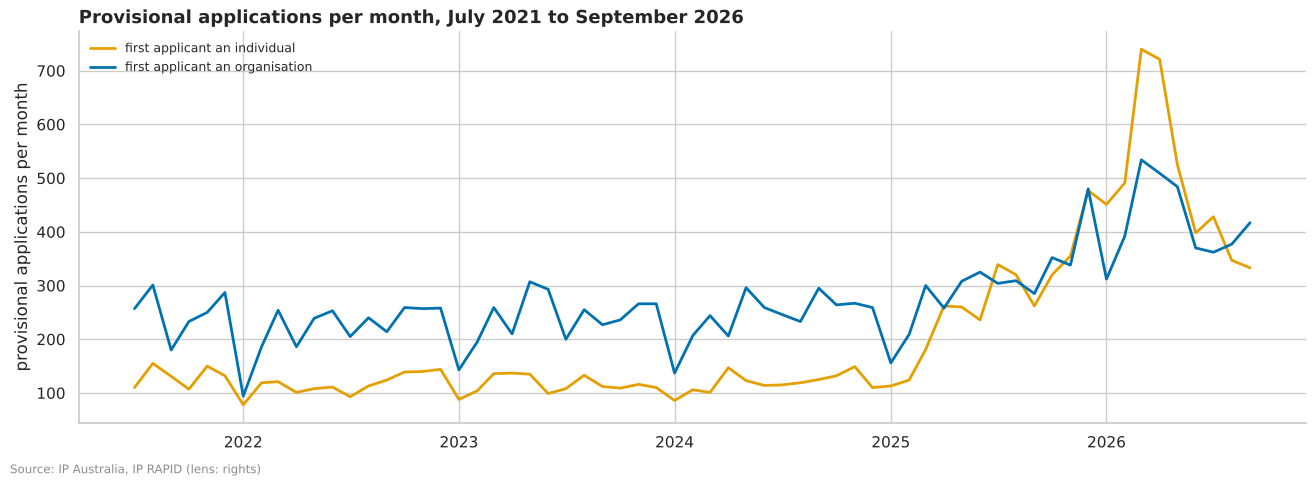

In [15]:
# The rise in provisional applications: per month since July 2021, by the first applicant's type
prov = sql("""
    SELECT date_trunc('month', application_date) AS month, coalesce(applicant_type, 'not recorded') AS applicant_type,
           count(*) AS n
    FROM {lens/rights}
    WHERE patent_type = 'provisional' AND application_date BETWEEN DATE '2021-07-01' AND DATE '2026-09-30'
    GROUP BY ALL ORDER BY 1
""").pivot(index="month", columns="applicant_type", values="n")
fig, ax = plt.subplots(figsize=(13, 4.5))
for c, colour in (("individual", style.ACCENT), ("organisation", style.MAIN)):
    ax.plot(prov.index, prov[c], color=colour, lw=2, label=f"first applicant an {c}")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_ylabel("provisional applications per month")
ax.set_title("Provisional applications per month, July 2021 to September 2026")
style.source(fig, "IP Australia, IP RAPID (lens: rights)")
months = pd.to_datetime(["2024-03-01", "2025-03-01", "2026-03-01", "2026-04-01", "2026-09-01"])
prov.assign(total=prov.sum(axis=1)).loc[months]

In [16]:
# Who filed them: founding applicants by the number of provisionals each filed in the year. A provisional with two
# founding applicants counts once for each, so the sums exceed the number of provisionals.
sql("""
    WITH p AS (
        SELECT r.filing_fy, a.party_id, any_value(a.party_type) AS party_type,
               count(DISTINCT r.application_number) AS k
        FROM {lens/rights} r
        JOIN {iprapid/party} a
          ON a.ip_right_type = 'patent' AND a.application_number = r.application_number
         AND a.party_role_category IN ('applicant', 'owner') AND a.is_founding
        WHERE r.patent_type = 'provisional' AND r.filing_fy IN (2025, 2026)
        GROUP BY 1, 2
    )
    SELECT filing_fy, party_type AS applicant,
           count(*) FILTER (k = 1) AS "filers of 1", sum(k) FILTER (k = 1) AS "their provisionals (1)",
           count(*) FILTER (k BETWEEN 2 AND 9) AS "filers of 2-9",
           sum(k) FILTER (k BETWEEN 2 AND 9) AS "their provisionals (2-9)",
           count(*) FILTER (k >= 10) AS "filers of 10+", sum(k) FILTER (k >= 10) AS "their provisionals (10+)",
           max(k) AS "most by one filer"
    FROM p GROUP BY 1, 2 ORDER BY 1, 2
""")

,filing_fy,applicant,filers of 1,their provisionals (1),filers of 2-9,their provisionals (2-9),filers of 10+,their provisionals (10+),most by one filer
0,2025,individual,1538,"1,538",208,549,9,183,37
1,2025,organisation,1513,"1,513",423,"1,229",24,566,66
2,2026,individual,2507,"2,507",611,"1,871",54,"1,528",375
3,2026,organisation,1853,"1,853",576,"1,753",45,"1,258",158


In [17]:
# The same years from the lens: provisionals by individuals and organisations, with an ABN, and from overseas
sql("""
    SELECT filing_fy, count(*) AS provisionals,
           count(DISTINCT applicant_abn) AS "distinct ABNs",
           count(*) FILTER (applicant_type = 'individual') AS "first applicant an individual",
           count(*) FILTER (has_abn) AS "with an ABN",
           count(*) FILTER (NOT australian_applicant) AS overseas
    FROM {lens/rights} WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2022 AND 2026
    GROUP BY 1 ORDER BY 1
""")

,filing_fy,provisionals,distinct ABNs,first applicant an individual,with an ABN,overseas
0,2022,4143,1358,1423,2291,265
1,2023,4292,1431,1452,2350,324
2,2024,4164,1345,1365,2306,342
3,2025,5047,1333,1926,2329,366
4,2026,10069,1361,5399,2619,488


#### Observations
**U5 (descriptive). Applications over time.**
- In FY2017 to FY2026 there were 28,798 to 32,960 standard patent applications a year, 72,652 to 98,189 trade marks,
  7,347 to 10,388 designs and 255 to 413 plant breeder's rights.
- In the chart, standard patents of "origin unknown" give way to "overseas" ones between about 1975 and 1990; from
  FY1990 no more than 0.4% are of unknown origin (the table). The change is in what the register records, not
  necessarily in who filed.
- Second-tier patents peak at 7,150 in FY2021, the year innovation patents closed, and then fall to 232 (FY2023),
  123, 68 and 52 (FY2026).
- Provisional applications ran at 4,143 to 5,343 a year in FY2017 to FY2025, then doubled to 10,069 in FY2026 (U8).
- **Correction (found with the timeline's profile, U23).** Before 1983 for trade marks, 1986 for designs and
  September 1985 for provisional applications, IP RAPID holds only the rights still on the register when its records
  were computerised, so the chart's earlier counts of those types are survivors and understate filings.

**U6 (descriptive). The latest years are complete.** FY2025 and FY2026 are not lower than earlier years for any type:
standard patents 29,950 and 31,136 (against 28,798 to 32,960 in FY2017 to FY2024); trade marks 92,470 and 98,189 and
designs 10,126 and 10,388, the decade's highest. The lens counts an application when it is filed in Australia (for a
PCT application, when it enters the national phase; ADR 0010), so there is no publication lag. FY2027 (8,357 standard
patents to mid-October 2026) is partial and is left out.

**U7 (descriptive). Australian applicants' shares, where origin is recorded.**
- **Standard patents:** 11.3% in FY1990 and 12.4% in FY1995, then about 8% to 11% (7.9% to 10.8% in the table's
  years from FY2000; 9.3% in FY2026). About nine in ten standard patents come from overseas.
- **Trade marks:** 62.9% (FY1995) to 69.5% (FY2005), then 55.8% to 62.4% in the table's years since FY2018.
- **Provisional applications:** 91.8% to 98.1% Australian. They are the cheap first step Australians use to secure a
  filing date.
- **Second-tier patents:** 79.2% to 87.4% Australian in FY1990 to FY2010, down to 16.1% in FY2021, when overseas
  applicants filed before the closure, and 61.8% to 75% in FY2024 to FY2026, on 52 to 123 filings a year.
- **Plant breeder's rights:** 37.8% to 52.3% since FY1995.
- **Designs:** origin is unknown for 20.3% to 23.3% of designs in FY1990 to FY2000 and for 4.0% to 6.3% since FY2018,
  so a share can be given only in a few recent years (27.4% to 33.9% in FY2018 to FY2022). The unknown share is rising
  again: 5.1%, 6.3% and 6.0% in FY2024 to FY2026.
- **Decision:** in Stage 2, Australian shares are compared from FY1990, and a design share is always shown with its
  unknown share beside it.

**U8 (descriptive). The rise in provisional applications is real, broad and partly concentrated.**
- **When.** In March 2024 there were 345 provisionals (101 with an individual as first applicant). The rise starts in
  early 2025 (481 in March 2025) and peaks in March and April 2026 (1,274 and 1,231, of which 740 and 721 by
  individuals). By September 2026 it has eased to 750 (333 by individuals), still about twice March 2024's level.
- **How much.** FY2026 had 10,069 provisionals, against 4,143 to 5,047 a year in FY2022 to FY2025. 5,399 had an
  individual as first applicant, against 1,365 to 1,926.
- **Not from businesses.** Distinct ABNs stayed flat (1,361 in FY2026; 1,333 to 1,431 before), and provisionals with an
  ABN rose only from 2,329 to 2,619.
- **Broad.** Individuals who filed a single provisional rose from 1,538 (FY2025) to 2,507 (FY2026).
- **And concentrated.** 54 individuals filed 10 or more each (1,528 between them), against 9 who filed 183 in FY2025;
  one filed 375. 45 organisations filed 10 or more (1,258), against 24 (566).
- Why is outside these data. Stage 2 lines the months up against the policy and fee events, and IP Australia's own
  published figures are the benchmark (the plan's item 4).

### 1.3 Status and how rights end

**Informs:** Q1. **Helpers:** `sql`.

- [x] Status by type, and what 'unknown' means for old rights.
- [x] The share of rights that are pending, in force, or ended before or after grant.
- [x] What 'ceased' means, against 'lapsed' (a lead).
- [x] The share of each year's applications that were granted or registered.

In [18]:
# Every status held by at least 1,000 rights: how many ever registered, and how many have an end date
status = sql("""
    SELECT ip_right_type, status, count(*) AS rights,
           100 * avg((registered_date IS NOT NULL)::int) AS "% ever registered",
           100 * avg((retired_date IS NOT NULL)::int) AS "% with an end date",
           min(filing_fy) AS first_fy, median(filing_fy)::int AS median_fy, max(filing_fy) AS last_fy
    FROM {lens/rights} GROUP BY ALL HAVING count(*) >= 1000 ORDER BY 1, rights DESC
""")
status

,ip_right_type,status,rights,% ever registered,% with an end date,first_fy,median_fy,last_fy
0,design,ceased,176154,92.08,91.29,1972,2005,2026
1,design,registered,55241,100,0,2017,2023,2027
2,design,lapsed,19141,0.005224,99.93,1986,2000,2026
3,design,certified,10590,100,0,2017,2023,2027
4,design,refused,3037,0,62.3,1984,1987,2019
5,design,withdrawn,2414,0,97.56,1984,2014,2027
6,design,filed,1868,0.1071,0,2023,2027,2027
7,patent,lapsed,534659,0.0005611,80.63,1914,2007,2027
8,patent,ceased,424221,99.93,99.21,1913,2002,2025
9,patent,unknown,408957,0,0,1904,1961,1999


stage,pending,in force,ended before grant,ended after grant,other,unknown,total
t,,,,,,,
standard,94887,167597,305356,476880,2200,393027,1439947
provisional,10637,0,237344,0,113,15930,264024
second_tier,7,3135,4863,39807,645,0,48457
trade_mark,85829,963245,614871,662578,8541,0,2335064
design,1893,65831,24592,176372,94,0,268782
pbr,1895,2428,2570,4839,0,0,11732


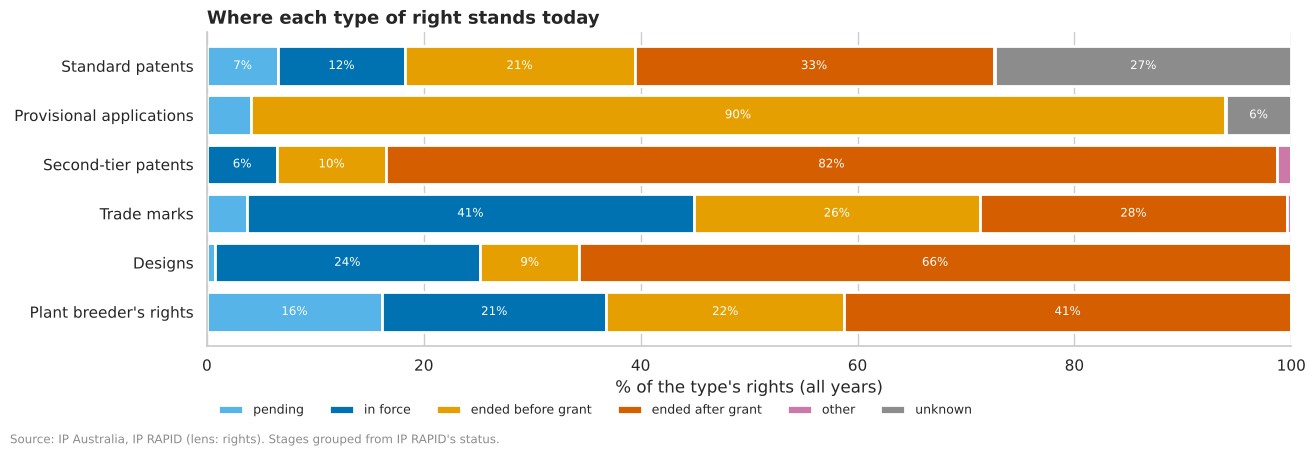

In [19]:
# Statuses grouped into stages (the grouping is by status name; the table above shows how well it holds)
STAGES = {
    "pending": ["filed", "published", "accepted", "new", "received"],
    "in force": ["granted", "registered", "protected", "certified"],
    "ended before grant": [
        "lapsed",
        "withdrawn",
        "refused",
        "rejected",
        "inter_partes_refused",
        "ex_parte_refused",
        "voided",
    ],
    "ended after grant": ["ceased", "expired", "revoked", "terminated", "surrendered", "cancelled", "removed"],
    "other": ["converted", "linked", "not_filed"],
    "unknown": ["unknown"],
}
STAGE_COLOURS = dict(zip(STAGES, [style.PALETTE[i] for i in (4, 0, 1, 5, 3)] + [style.MUTED], strict=True))
stage_of = {s: stage for stage, names in STAGES.items() for s in names}
assert set(rights.status.unique()) <= set(stage_of), "a status is not in a stage"
stages = (
    rights.assign(t=rights.patent_type.fillna(rights.ip_right_type), stage=rights.status.map(stage_of))
    .pivot_table(index="t", columns="stage", values="application_number", aggfunc="size", fill_value=0)
    .reindex(index=list(TYPES), columns=list(STAGES))
)
stages_pct = 100 * stages.div(stages.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(13, 4.2))
left = pd.Series(0.0, index=stages_pct.index)
names = [TYPES[t] for t in stages_pct.index][::-1]
for stage in STAGES:
    v = stages_pct[stage][::-1]
    ax.barh(names, v, left=left[::-1], color=STAGE_COLOURS[stage], edgecolor="white", linewidth=2, label=stage)
    for y, (x0, w) in enumerate(zip(left[::-1], v, strict=True)):
        if w >= 6:
            ax.text(x0 + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left += stages_pct[stage]
ax.set_xlim(0, 100)
ax.set_xlabel("% of the type's rights (all years)")
ax.legend(frameon=False, fontsize=9, ncol=6, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("Where each type of right stands today")
style.source(fig, "IP Australia, IP RAPID (lens: rights). Stages grouped from IP RAPID's status.")
stages.assign(total=stages.sum(axis=1))

registered                                      pending                                     
t             design  pbr second_tier standard trade_mark  design  pbr second_tier standard trade_mark
filing_fy                                                                                             
1990            78.3   72        51.3     74.6       52.1       0    0           0        0          0
2000            79.8 75.4        59.6     75.5       63.2       0    0           0        0          0
2008            93.2 71.8        90.7     54.4       74.3       0  1.1           0        0          0
2010              95 64.6          90     61.4       70.1       0  2.6           0        0          0
2015            95.5 67.8        94.8       69       70.6       0  8.2           0        0          0
2019            95.4 47.2        96.6     65.4       80.7     0.1 30.1           0        0        0.1
2021            95.4 41.8        96.8     63.2       79.6       0   43           0        2        0.2
2022            95.9 34.2        97.5     54.3       79.8       0 54.3           0     12.2        0.3
2024            94.9   13        98.4     31.3       76.8       0 78.7           0     49.1        1.2
2026              94    0        92.3      1.9       51.1     1.7 97.6         7.7     96.5       47.9

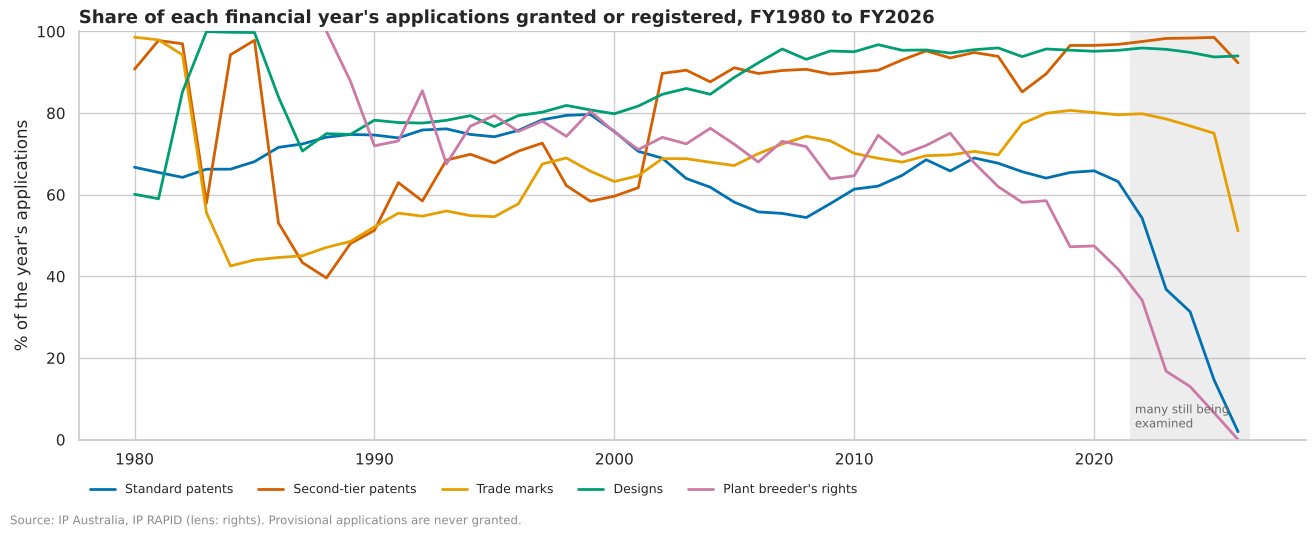

In [20]:
# The share of each year's applications that were granted or registered, and the share still pending
outcome = sql("""
    SELECT filing_fy, coalesce(patent_type, ip_right_type) AS t, count(*) AS n,
           100 * avg((registered_date IS NOT NULL)::int) AS registered,
           100 * avg((status IN ('filed', 'published', 'accepted', 'new', 'received'))::int) AS pending
    FROM {lens/rights} WHERE filing_fy BETWEEN 1980 AND 2026 AND patent_type IS DISTINCT FROM 'provisional'
    GROUP BY ALL
""")
fig, ax = plt.subplots(figsize=(13, 5))
for t, name in TYPES.items():
    if t == "provisional":
        continue
    d = outcome[outcome.t == t].set_index("filing_fy").sort_index()
    ax.plot(d.index, d.registered, color=TYPE_COLOURS[t], lw=2, label=name)
ax.axvspan(2021.5, 2026.5, color=style.MUTED, alpha=0.15, lw=0)
ax.text(2021.7, 3, "many still being\nexamined", fontsize=8.5, color="dimgrey")
ax.set_ylim(0, 100)
ax.set_ylabel("% of the year's applications")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=5)
ax.set_title("Share of each financial year's applications granted or registered, FY1980 to FY2026")
style.source(fig, "IP Australia, IP RAPID (lens: rights). Provisional applications are never granted.")
outcome.pivot(index="filing_fy", columns="t", values=["registered", "pending"]).loc[
    [1990, 2000, 2008, 2010, 2015, 2019, 2021, 2022, 2024, 2026]
].round(1)

#### Observations
**U9 (descriptive). How rights end.**
- **"Lapsed" and "ceased" differ, as the lead said.** Under 0.01% of lapsed patents, trade marks and designs were ever
  registered, against 99.93% of ceased patents, 100% of ceased trade marks and 92.08% of ceased designs. A lapse is an
  application abandoned; a cessation is a registered right let go.
- **"Unknown" is old patents.** 408,957 patents have the status "unknown". All were filed between FY1904 and FY1999
  (median FY1961), and none has a registration or end date: the register does not know what became of them. They are
  27% of standard patents (393,027) and 6% of provisional applications (15,930).
- **Old grants are under-recorded.** Only 68.9% of expired patents have a grant date, though only a granted patent can
  expire (they were filed FY1904 to FY2025, median FY1993). So "ever registered" understates grants among old patents.
- **Where rights stand today (all years):** trade marks 41% in force, 26% ended before registration and 28% after;
  designs 24% in force and 66% ended after registration; standard patents 12% in force and 7% pending; provisional
  applications 90% ended before grant, as they are meant to.

**U10 (descriptive). Grant and registration rates by year of application.**
- **Standard patents:** 74.6% of FY1990's applications and 75.5% of FY2000's were granted, but only 54.4% of FY2008's;
  then 61.4% (FY2010), 69.0% (FY2015) and 65.4% (FY2019).
- **Trade marks:** 52.1% (FY1990), 63.2% (FY2000), 70.1% (FY2010) and 80.7% (FY2019).
- **Designs:** 78.3% (FY1990) and 79.8% (FY2000), then about 95% from FY2010 (94.0% to 95.9%).
- **Second-tier patents:** 90.0% to 98.4% from FY2008 to FY2024. This is not a pass rate: an innovation patent was
  granted after a check of its formalities only, and examined only if certified later (the glossary). Its
  certification comes with the events attachment.
- **Still pending:** standard patents 2.0% of FY2021's applications, 12.2% of FY2022's and 49.1% of FY2024's; trade
  marks 1.2% of FY2024's; plant breeder's rights 8.2% of FY2015's and 30.1% of FY2019's.
- **Correction (U23).** In the chart, trade marks to FY1983 and designs to FY1986 show nearly all applications
  registered because IP RAPID holds only the survivors of those years; their rates are not comparable with later
  years'.
- **Decision:** rates are compared only for years whose applications are nearly all decided: to FY2021 for standard
  patents, FY2024 for trade marks, FY2026 for designs (1.7% pending) and about FY2010 for plant breeder's rights (2.6%
  pending).

### 1.4 Time to registration (`days_to_registration`)

**Informs:** Q1, Q4. **Helpers:** `uni.describe`, `uni.distribution`, `uni.bin_check`.

- [x] Distribution by type, for applications filed FY2010 to FY2019: by 2026 at most 0.1% of them are still pending
  (1.3), so the times are not cut short by applications still being examined.
- [x] A bin-width check for standard patents (`uni.bin_check`).
- [x] The negative values (repaired in part, ADR 0012).
- [x] The typical time by filing year.

In [21]:
# The distribution for each type, for applications filed FY2010 to FY2019 and since registered
done = rights.loc[rights.filing_fy.between(2010, 2019) & rights.days_to_registration.notna()]
done_type = done.patent_type.fillna(done.ip_right_type)
pd.DataFrame(
    {name: uni.describe(done.days_to_registration[done_type == t]) for t, name in TYPES.items() if t != "provisional"}
)

,Standard patents,Second-tier patents,Trade marks,Designs,Plant breeder's rights
count,1.807e+05,1.716e+04,4.934e+05,6.516e+04,"2,235"
missing,0,0,0,0,0
% missing,0,0,0,0,0
% zero,0,0,0.003243,0.03223,0
mean,"1,022",29.19,286.5,51.7,"1,499"
median,980,21,223,33,"1,296"
std,440.3,35.97,202.4,53.45,862.6
min,78,2,"-5,946",-22,233
1%,206,8,90,7,361
25%,681,16,211,24,868


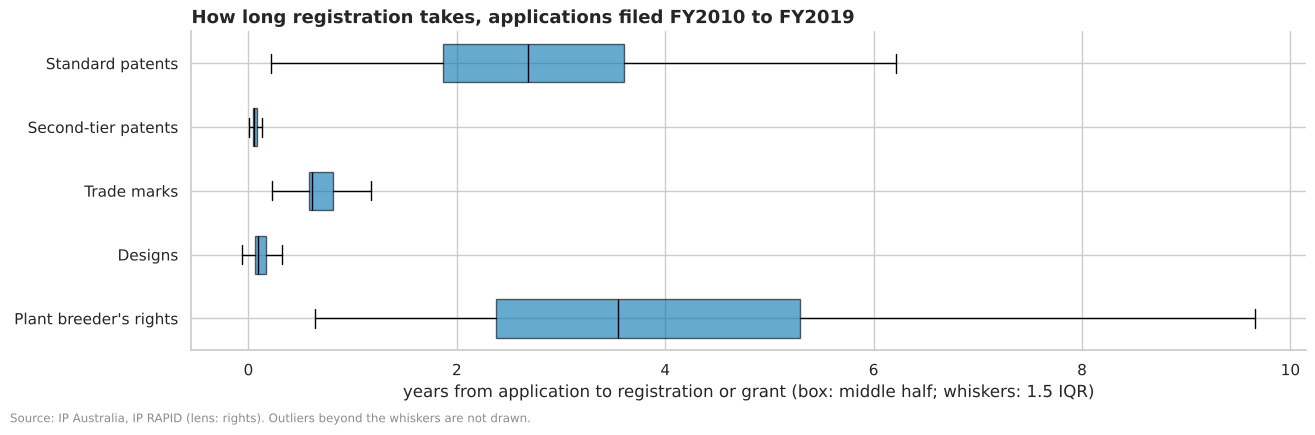

In [22]:
fig, ax = plt.subplots(figsize=(13, 4))
order = [t for t in TYPES if t != "provisional"]
ax.boxplot(
    [done.days_to_registration[done_type == t] / 365.25 for t in order][::-1],
    orientation="horizontal",
    widths=0.6,
    showfliers=False,
    patch_artist=True,
    tick_labels=[TYPES[t] for t in order][::-1],
    medianprops={"color": "black"},
    boxprops={"facecolor": style.MAIN, "alpha": 0.6},
)
ax.set_xlabel("years from application to registration or grant (box: middle half; whiskers: 1.5 IQR)")
ax.set_title("How long registration takes, applications filed FY2010 to FY2019")
style.source(fig, "IP Australia, IP RAPID (lens: rights). Outliers beyond the whiskers are not drawn.")

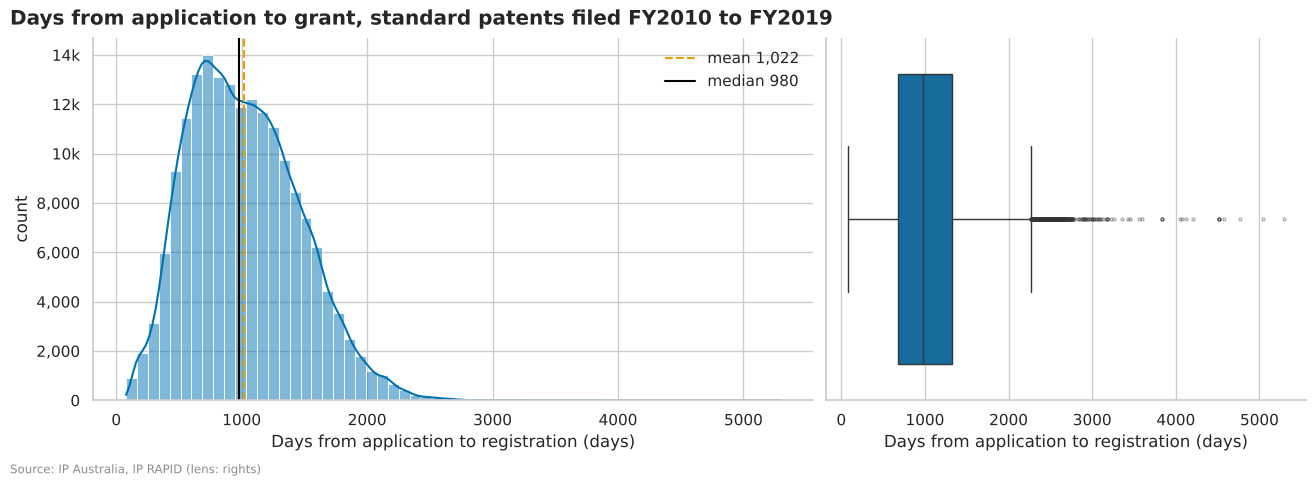

In [23]:
std = done.days_to_registration[done_type == "standard"]
fig = uni.distribution(
    std,
    title="Days from application to grant, standard patents filed FY2010 to FY2019",
    xlabel=style.label("rights", "days_to_registration"),
    bins=60,
)
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

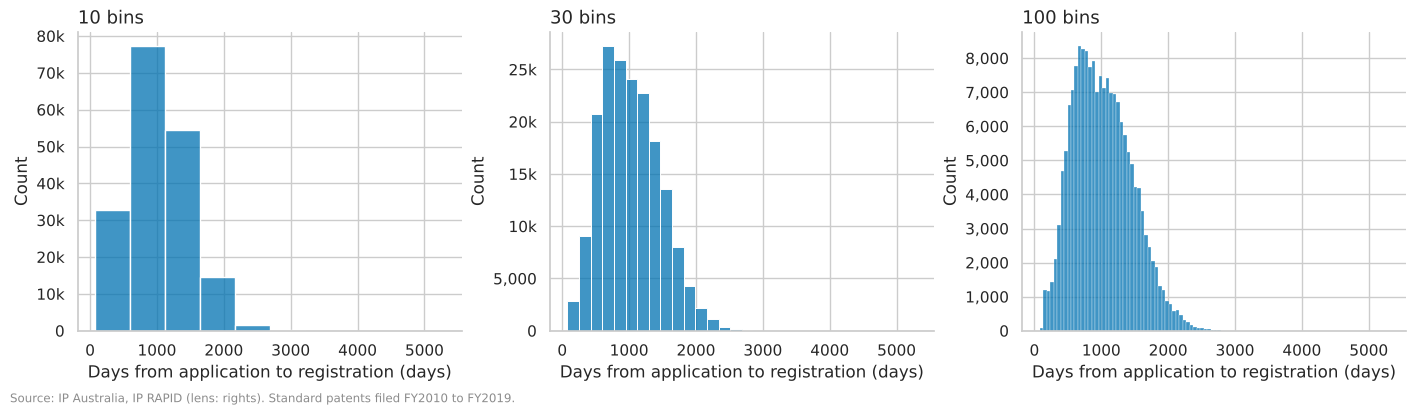

In [24]:
fig = uni.bin_check(std, xlabel=style.label("rights", "days_to_registration"))
style.source(fig, "IP Australia, IP RAPID (lens: rights). Standard patents filed FY2010 to FY2019.")

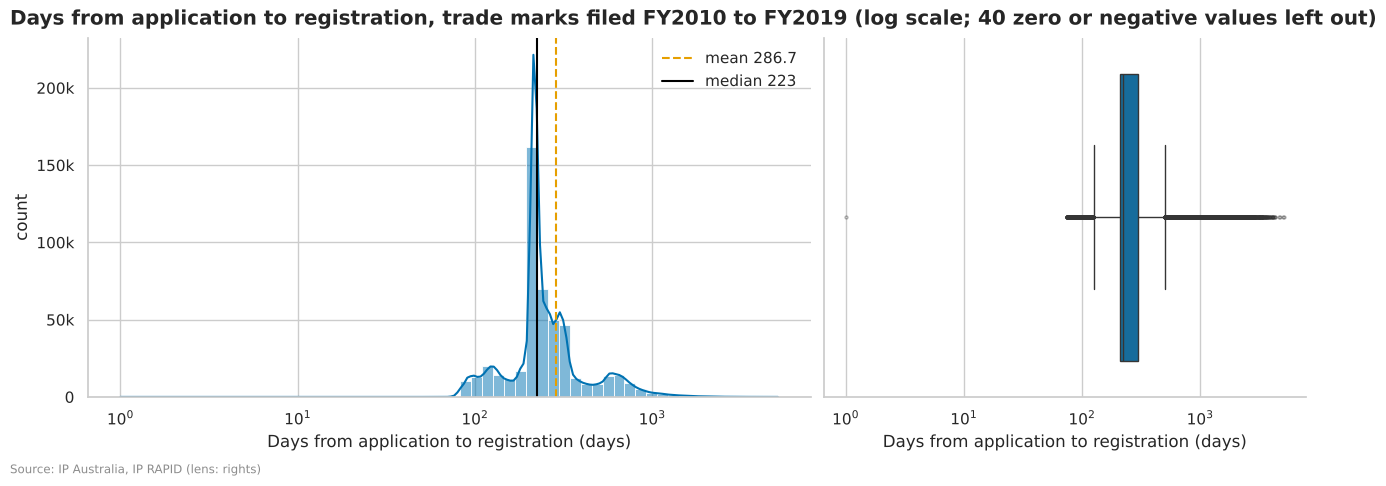

In [25]:
fig = uni.distribution(
    done.days_to_registration[done_type == "trade_mark"],
    title="Days from application to registration, trade marks filed FY2010 to FY2019",
    xlabel=style.label("rights", "days_to_registration"),
    bins=60,
    log=True,
)
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

t          design  pbr  second_tier  standard  trade_mark
filing_fy                                                
1990         0.64 1.57         0.51      2.59        2.35
2000         0.65 2.31         0.56      2.27        1.13
2005         0.52 2.29         0.06      3.96        0.67
2010         0.08 2.92         0.07      3.49        0.63
2015          0.1 3.28         0.05      2.32         0.6
2019         0.11 3.93         0.06      2.76        0.69
2021         0.16 2.98         0.12      2.91        0.61
Negative values left: 57, by type: {'trade_mark': 53, 'patent': 3, 'design': 1}


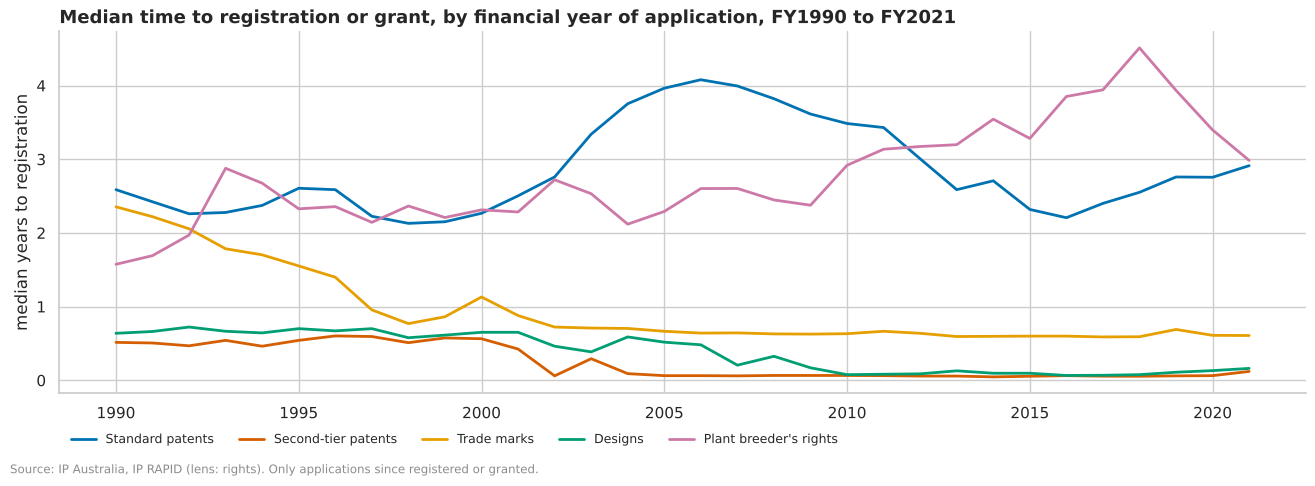

In [26]:
# The median time by filing year, FY1990 to FY2021 (later years are still being examined, so their medians are too
# short), with the negative values left after the repair
med = sql("""
    SELECT filing_fy, coalesce(patent_type, ip_right_type) AS t, median(days_to_registration) / 365.25 AS years
    FROM {lens/rights} WHERE filing_fy BETWEEN 1990 AND 2021 AND days_to_registration IS NOT NULL GROUP BY ALL
""")
fig, ax = plt.subplots(figsize=(13, 4.5))
for t, name in TYPES.items():
    d = med[med.t == t].set_index("filing_fy").years.sort_index()
    if len(d):
        ax.plot(d.index, d, color=TYPE_COLOURS[t], lw=2, label=name)
ax.set_ylabel("median years to registration")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=5)
ax.set_title("Median time to registration or grant, by financial year of application, FY1990 to FY2021")
style.source(fig, "IP Australia, IP RAPID (lens: rights). Only applications since registered or granted.")
print(
    med.pivot(index="filing_fy", columns="t", values="years").loc[[1990, 2000, 2005, 2010, 2015, 2019, 2021]].round(2)
)
neg = rights.days_to_registration < 0
print(f"Negative values left: {neg.sum():,}, by type:", rights.loc[neg, "ip_right_type"].value_counts().to_dict())

#### Observations
**U11 (descriptive). How long registration takes, for applications filed FY2010 to FY2019.**
- **Standard patents:** median 980 days (about 2.7 years); the middle half take 681 to 1,318 days, and 99% are granted
  within 2,156. The shape is one hump, slightly skewed to the right (skew 0.50), at every bin width.
- **Trade marks:** median 223 days; the middle half take 211 to 298, with a long tail to the right (99% within 1,081
  days; skew 3.7). A sharp peak at about 222 days holds the most common value of the whole column (222 days, 3.9% of
  values, in the overview). It looks like the shortest path through examination and the opposition period: a lead to
  confirm, not a finding.
- **Designs** take a median 33 days, **second-tier patents** 21, and **plant breeder's rights** 1,296 (about 3.5
  years), with the widest spread (the middle half 868 to 1,932 days). An innovation patent was granted after a check
  of its formalities only, so its 21 days are not a time to examination and are not compared with standard
  patents'.
- 57 values remain negative (53 trade marks, 3 patents and 1 design), down from the 1,497 noted while building the
  lens, after repair 3. They are left as recorded.

**U12 (descriptive). The typical time, by year of application.**
- **Standard patents:** a median 2.59 years for FY1990's applications, 2.27 (FY2000), 3.96 (FY2005), 3.49 (FY2010),
  2.32 (FY2015), 2.76 (FY2019) and 2.91 (FY2021).
- **Trade marks:** 2.35 years (FY1990) and 1.13 (FY2000), then 0.60 to 0.69 since FY2005.
- **Designs:** 0.52 to 0.65 years to FY2005, then 0.08 to 0.16 since FY2010.
- **Plant breeder's rights:** from 1.57 years (FY1990) to 3.93 (FY2019).
- Only applications later registered or granted count, so these are the times of successful applications.
- **Decision:** times are compared only within the complete years of U10.

### 1.5 Who applies: origin, type, ABN, attorney

**Informs:** Q2. **Helpers:** `sql`, `uni.counts`.

- [x] Share of applications from Australian applicants, by type (known origin only), FY2017 to FY2026.
- [x] Organisations against individuals; share with an ABN; share with an attorney (as repaired, ADR 0012).
- [x] The first applicant's country, for standard patents.
- [x] The number of applicants per right.

In [27]:
# Who filed in the ten latest complete years, FY2017 to FY2026, by type
who = (
    sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, count(*) AS rights,
           100 * avg((australian_applicant IS NULL)::int) AS "% origin unknown",
           100 * avg(australian_applicant::int) AS "% Australian (known origin)",
           100 * avg((applicant_type = 'individual')::int) FILTER (australian_applicant) AS "% individuals (Aus.)",
           100 * avg((applicant_type = 'individual')::int) FILTER (NOT australian_applicant)
               AS "% individuals (overseas)",
           100 * avg(has_abn::int) FILTER (australian_applicant) AS "% with an ABN (Aus.)",
           100 * avg(has_abn::int) FILTER (australian_applicant AND applicant_type = 'organisation')
               AS "% with an ABN (Aus. organisations)",
           100 * avg(has_agent::int) FILTER (australian_applicant) AS "% with an attorney (Aus.)",
           100 * avg(has_agent::int) FILTER (NOT australian_applicant) AS "% with an attorney (overseas)",
           100 * avg((applicant_count > 1)::int) AS "% with 2+ applicants"
    FROM {lens/rights} WHERE filing_fy BETWEEN 2017 AND 2026 GROUP BY 1
""")
    .set_index("t")
    .loc[list(TYPES)]
    .rename(index=TYPES)
)
who.T

t,Standard patents,Provisional applications,Second-tier patents,Trade marks,Designs,Plant breeder's rights
rights,3.05e+05,5.247e+04,2.048e+04,8.318e+05,8.386e+04,"3,112"
% origin unknown,0.002295,0.007624,0,0.019,5.062,0.6427
% Australian (known origin),8.675,94.45,33.75,59,30.05,43.79
% individuals (Aus.),20.59,40.35,41.63,24.78,21.32,15.36
% individuals (overseas),3.614,24.56,26.71,6.908,4.32,17.89
% with an ABN (Aus.),70.4,49.44,51.19,59.68,68.38,0
% with an ABN (Aus. organisations),87.98,81.57,85.01,78.3,86.3,0
% with an attorney (Aus.),86.79,NaN,66.68,57.02,71.65,41.21
% with an attorney (overseas),99.12,NaN,89.91,96.27,98.32,96.55
% with 2+ applicants,6.694,6.89,21.7,2.457,2.573,3.053


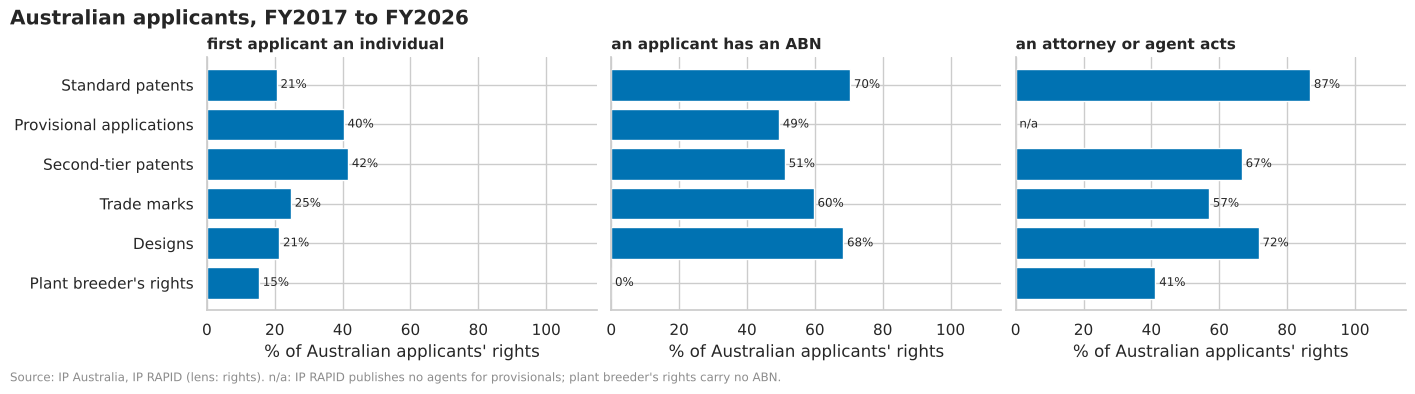

In [28]:
# Australian applicants, FY2017 to FY2026: individuals, an ABN, an attorney
panels = {
    "% individuals (Aus.)": "first applicant an individual",
    "% with an ABN (Aus.)": "an applicant has an ABN",
    "% with an attorney (Aus.)": "an attorney or agent acts",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (col, title) in zip(axes, panels.items(), strict=True):
    v = who[col][::-1]
    ax.barh(v.index, v.fillna(0), color=style.MAIN)
    for y, x in enumerate(v):
        ax.text(0 if pd.isna(x) else x, y, " n/a" if pd.isna(x) else f" {x:.0f}%", va="center", fontsize=8.5)
    ax.set_xlim(0, 115)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("% of Australian applicants' rights")
fig.suptitle("Australian applicants, FY2017 to FY2026", x=0, ha="left", fontweight="bold")
style.source(
    fig,
    "IP Australia, IP RAPID (lens: rights). n/a: IP RAPID publishes no agents for provisionals; "
    "plant breeder's rights carry no ABN.",
)

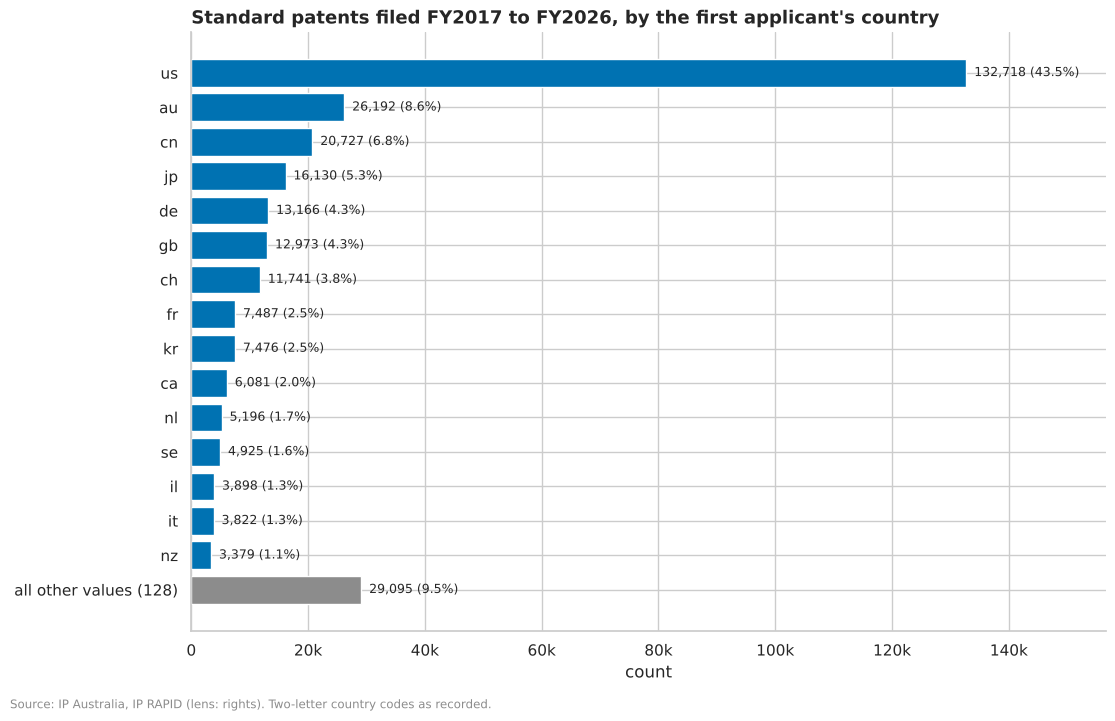

In [29]:
recent_std = rights.loc[(rights.patent_type == "standard") & rights.filing_fy.between(2017, 2026)]
fig = uni.counts(
    recent_std.applicant_country,
    top=15,
    title="Standard patents filed FY2017 to FY2026, by the first applicant's country",
)
style.source(fig, "IP Australia, IP RAPID (lens: rights). Two-letter country codes as recorded.")

In [30]:
# The number of applicants per right (all years), and the rights with none recorded
n_app = rights.applicant_count.clip(upper=3).map({0: "none", 1: "one", 2: "two", 3: "three or more"})
counts_by_type = pd.crosstab(rights.patent_type.fillna(rights.ip_right_type), n_app, normalize="index") * 100
print(
    "Rights with no applicant recorded:",
    f"{(rights.applicant_count == 0).sum():,};",
    "of unknown origin:",
    f"{((rights.applicant_count == 0) & rights.australian_applicant.isna()).sum():,}",
)
counts_by_type.loc[list(TYPES), ["none", "one", "two", "three or more"]].rename(index=TYPES)

Rights with no applicant recorded: 91,979; of unknown origin: 91,979


applicant_count,none,one,two,three or more
patent_type,,,,
Standard patents,5.308,90.48,3.485,0.7321
Provisional applications,0.005681,90,8.552,1.442
Second-tier patents,0,85.56,7.966,6.47
Trade marks,0.01507,96.62,2.943,0.4268
Designs,5.647,89.88,3.992,0.4777
Plant breeder's rights,0.07671,98.59,1.227,0.1108


#### Observations
**U13 (descriptive). Who applied, FY2017 to FY2026.**
- **Australian share (known origin):** standard patents 8.675%, so 91.3% came from overseas; trade marks 59.0%; designs
  30.05% (with 5.062% of unknown origin); second-tier patents 33.75%; plant breeder's rights 43.79%; provisional
  applications 94.45%.
- **The first applicant's country, standard patents:** the United States 132,718 (43.5%), Australia 26,192 (8.6%),
  China 20,727 (6.8%), Japan 16,130 (5.3%), Germany 13,166 (4.3%), the United Kingdom 12,973 (4.3%) and Switzerland
  11,741 (3.8%).
- **Individuals.** An individual is the first applicant on 20.59% of Australian standard patents, against 3.614% of
  overseas ones; on 40.35% of Australian provisional applications, 41.63% of second-tier patents and 24.78% of trade
  marks.
- **ABNs.** 70.4% of Australian standard patents have an applicant with an ABN, and 87.98% of those filed by
  Australian organisations; for Australian organisations' trade marks, 78.3%. So 12% to 22% of Australian
  organisations' rights cannot reach the `firms` lens. Plant breeder's rights carry no ABN at all.
- **Agents.** Australian applicants used an agent other than themselves for 86.79% of standard patents, 71.65% of
  designs, 66.68% of second-tier patents, 57.02% of trade marks and 41.21% of plant breeder's rights; overseas
  applicants for 89.91% to 99.12%. Most such agents are attorneys (1.8.1 separates them). Filing alone is common among
  Australians, above all for trade marks, and rare from overseas.
- **Applicants per right.** 85.56% to 98.59% of each type's rights (all years) have one applicant; 21.7% of second-tier
  patents filed in FY2017 to FY2026 have two or more (6.694% of standard patents).
- 91,979 rights have no applicant recorded, all of unknown origin: 5.308% of standard patents and 5.647% of designs
  (all years).

### 1.6 What is protected: classes and technology areas

**Informs:** Q1, Q3. **Helpers:** `uni.counts`, `uni.describe`.

- [x] WIPO technology fields and IPC subclasses (patents); Nice classes (trade marks); Locarno classes (designs); plant
  genera (plant breeder's rights).
- [x] How many rights have no class, and the number of classes per right.

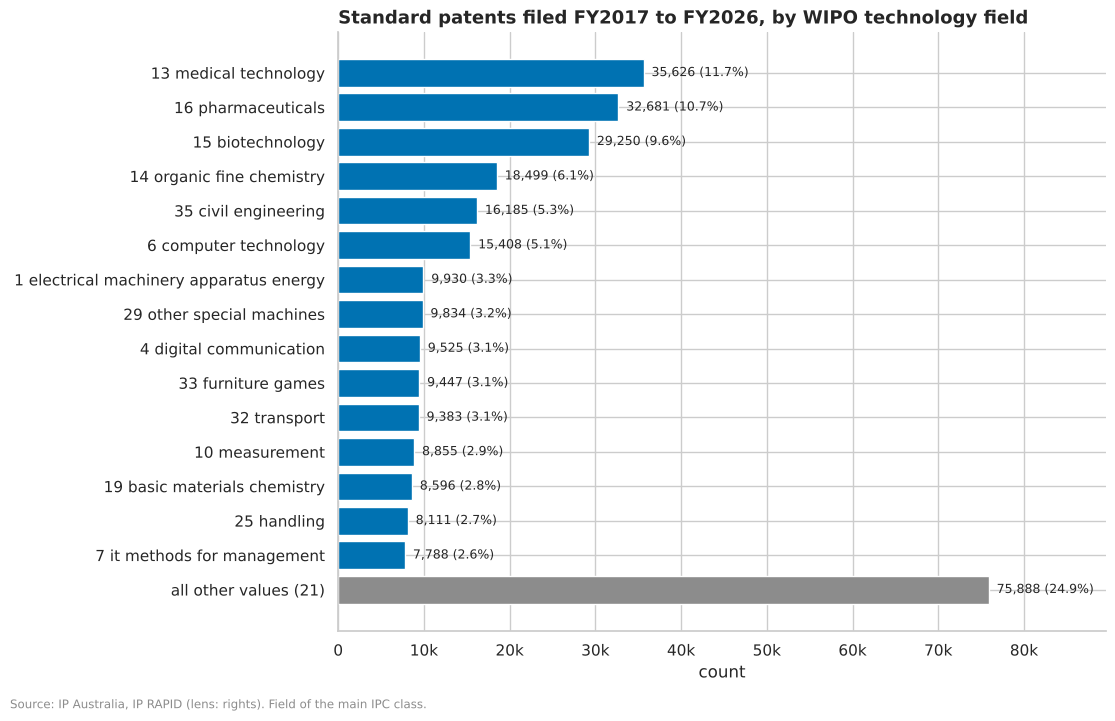

In [31]:
fig = uni.counts(
    recent_std.main_area.str.replace("_", " "),
    top=15,
    title="Standard patents filed FY2017 to FY2026, by WIPO technology field",
)
style.source(fig, "IP Australia, IP RAPID (lens: rights). Field of the main IPC class.")

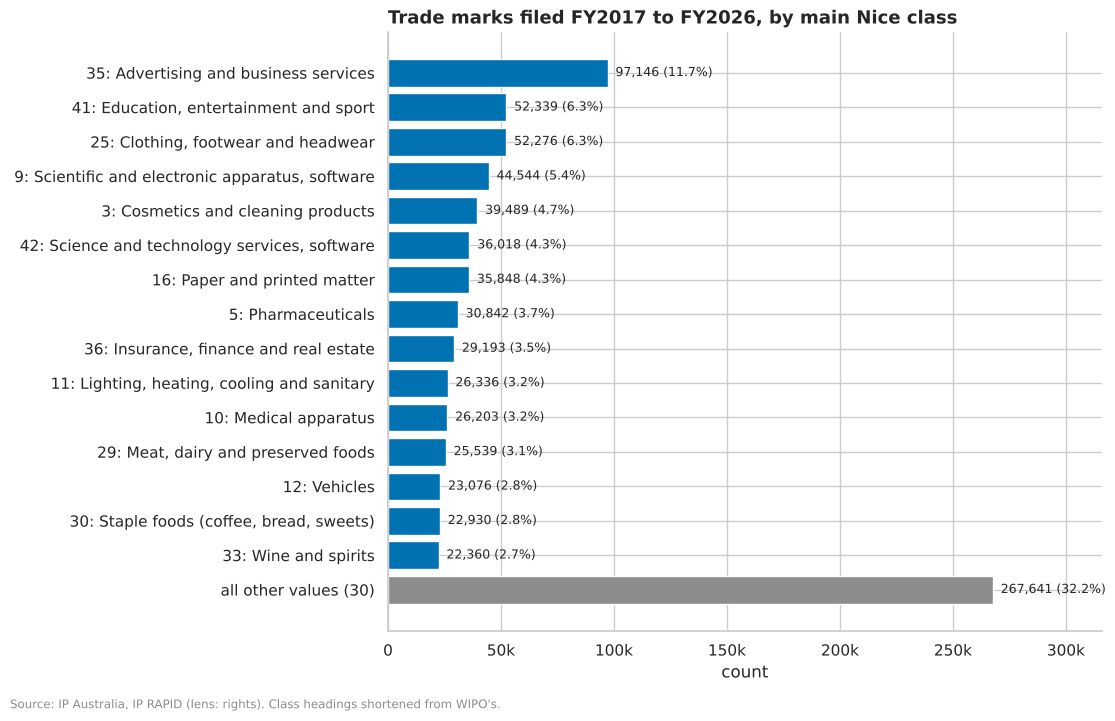

In [32]:
recent = rights.loc[rights.filing_fy.between(2017, 2026)]
tm = recent.loc[recent.ip_right_type == "trade_mark", "main_class"]
fig = uni.counts(
    tm.map(lambda c: style.class_name("trade_mark", c) if pd.notna(c) else c),
    top=15,
    title="Trade marks filed FY2017 to FY2026, by main Nice class",
)
style.source(fig, "IP Australia, IP RAPID (lens: rights). Class headings shortened from WIPO's.")

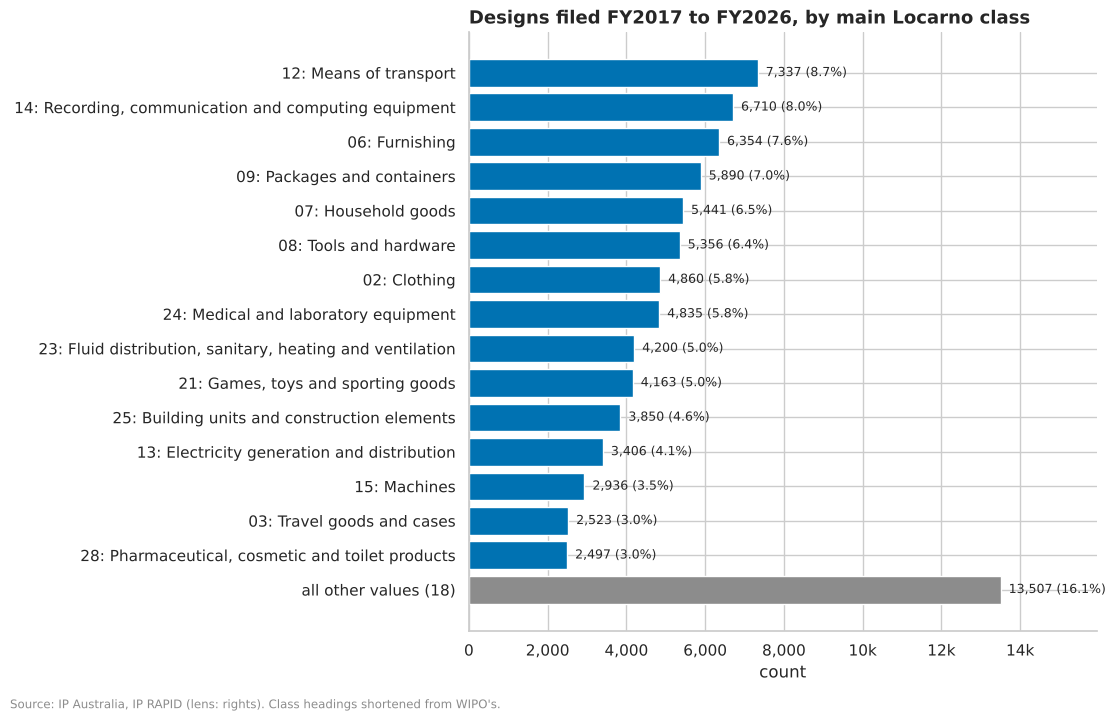

In [33]:
ds = recent.loc[recent.ip_right_type == "design", "main_class"]
fig = uni.counts(
    ds.map(lambda c: style.class_name("design", c) if pd.notna(c) else c),
    top=15,
    title="Designs filed FY2017 to FY2026, by main Locarno class",
)
style.source(fig, "IP Australia, IP RAPID (lens: rights). Class headings shortened from WIPO's.")

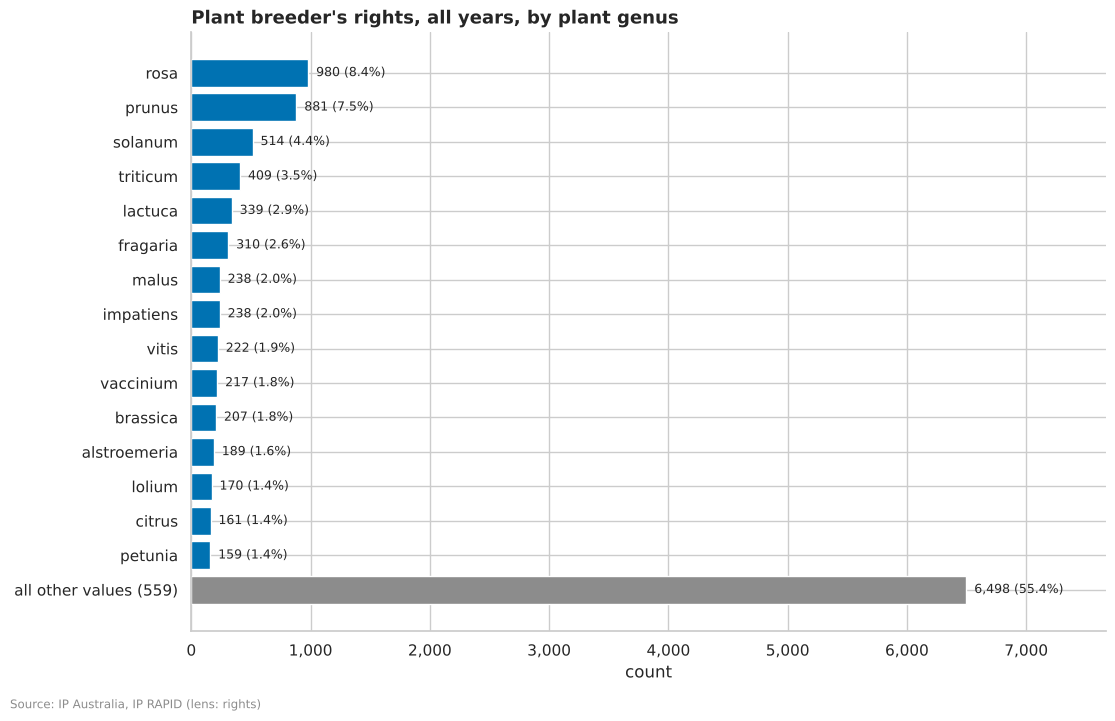

In [34]:
fig = uni.counts(
    rights.loc[rights.ip_right_type == "pbr", "main_class"],
    top=15,
    title="Plant breeder's rights, all years, by plant genus",
)
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

In [35]:
# Rights with no class, by type and decade of application; and the number of classes per right (FY2017 to FY2026)
no_class = sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, (filing_fy // 10) * 10 AS decade,
           100 * avg((main_class IS NULL)::int) AS pct
    FROM {lens/rights} GROUP BY ALL
""").pivot(index="decade", columns="t", values="pct")
print("% of rights with no class, by decade of application (empty decade: no application date)")
print(no_class[list(TYPES)].rename(columns=TYPES).round(1).to_string())
pd.DataFrame(
    {
        name: uni.describe(recent.class_count[recent.patent_type.fillna(recent.ip_right_type) == t])
        for t, name in TYPES.items()
        if t != "provisional"
    }
).loc[["count", "% missing", "mean", "median", "75%", "99%", "max"]]

% of rights with no class, by decade of application (empty decade: no application date)
t       Standard patents  Provisional applications  Second-tier patents  Trade marks  Designs  Plant breeder's rights
decade                                                                                                               
<NA>                94.3                       100                 92.5            0     99.6                    16.7
1900                 100                       NaN                  NaN          0.1      NaN                     NaN
1910                99.9                       NaN                  NaN            0      NaN                     NaN
1920                27.6                       NaN                  NaN            0      NaN                     NaN
1930                21.2                       NaN                  NaN            0      NaN                     NaN
1940                25.7                       NaN                  NaN            0  

,Standard patents,Second-tier patents,Trade marks,Designs,Plant breeder's rights
count,3.012e+05,1.944e+04,8.318e+05,8.373e+04,"3,083"
% missing,1.259,5.102,0,0.1586,0.9319
mean,1.856,2.025,1.803,1.056,1
median,2,2,1,1,1
75%,2,3,2,1,1
99%,5,6,8,2,1
max,19,14,45,5,1


#### Observations
**U14 (descriptive). What is protected, FY2017 to FY2026.**
- **Standard patents:** medical technology 35,626 (11.7%), pharmaceuticals 32,681 (10.7%) and biotechnology 29,250
  (9.6%), together 32.0%; then organic fine chemistry (6.1%), civil engineering (5.3%) and computer technology (5.1%).
- **Trade marks:** advertising and business services (class 35) 97,146 (11.7%); education, entertainment and sport (41)
  52,339 (6.3%); clothing (25) 52,276 (6.3%); scientific and electronic apparatus and software (9) 44,544 (5.4%).
- **Designs:** means of transport (12) 7,337 (8.7%); recording, communication and computing equipment (14) 6,710
  (8.0%); furnishing (06) 6,354 (7.6%).
- **Plant breeder's rights (all years):** roses (*Rosa*) 980 (8.4%), stone fruit (*Prunus*) 881 (7.5%) and *Solanum*
  (potatoes and tomatoes) 514 (4.4%); the other 559 values (genera, and the few rights with none) hold 55.4%.
- **No class.** Every provisional application; standard patents filed before 1920 (99.9% to 100%) and 20.3% to 27.6% of
  those filed in the 1920s to 1960s; under 1% from the 1980s to the 2010s, and 2.2% in the 2020s. Of the standard
  patents with no application date, 94.3% have no class.
- **Classes per right:** trade marks a median 1 (mean 1.803; 99% within 8; up to 45), standard patents a median 2 (mean
  1.856; up to 19), designs a median 1 (up to 5).
- **Decision:** technology fields describe standard patents from the 1970s (4.4% unclassified) onwards; earlier decades
  are described with that gap stated.

### 1.7 Where Australian applicants are

**Informs:** Q2. **Helpers:** `uni.counts`, `sql`.

- [x] The first applicant's state, for rights whose first applicant is in Australia.
- [x] How many have a usable postcode (the key into the `regions` lens).

patent_type,Standard patents,Provisional applications,Second-tier patents,Trade marks,Designs,Plant breeder's rights
applicant_state,,,,,,
nsw,38.2,36.3,34,35.8,37.5,18.3
vic,23.7,23.1,22,29.5,33.3,18.8
qld,17.4,18.8,23.5,18.7,15.9,13.3
wa,11,12.8,12.6,7.4,7.3,9.6
sa,4.6,5.4,4.9,5.8,4.5,9.5
act,3,2.4,1.6,1.4,0.7,4.5
(missing),1,0,0,0,0,24.8
tas,0.8,1,0.9,0.9,0.6,0.7
nt,0.2,0.3,0.4,0.4,0.2,0.4


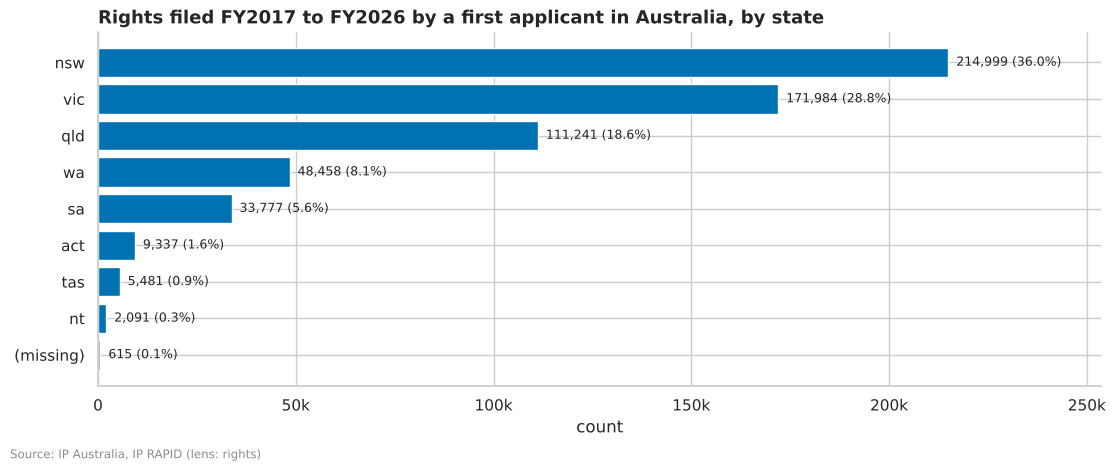

In [36]:
# States of Australian first applicants, FY2017 to FY2026, as a share of each type
au_first = recent[recent.applicant_country == "au"]
state_share = (
    pd.crosstab(
        au_first.applicant_state.fillna("(missing)"),
        au_first.patent_type.fillna(au_first.ip_right_type),
        normalize="columns",
    )
    * 100
)
fig = uni.counts(
    au_first.applicant_state, top=10, title="Rights filed FY2017 to FY2026 by a first applicant in Australia, by state"
)
style.source(fig, "IP Australia, IP RAPID (lens: rights)")
state_share[list(TYPES)].rename(columns=TYPES).sort_values("Standard patents", ascending=False).round(1)

In [37]:
# The repair of the state (ADR 0012), from IP RAPID as published: Australian first applicants with no state, by when
# they filed, and how often the postcode's postal area is in the recorded state where both exist
raw_state = " UNION ALL ".join(
    f"SELECT ip_right_sub_type AS t, application_date, applicant_state, trim(applicant_postcode) AS pc "
    f"FROM {{iprapid/{t}_rights}} WHERE applicant_country = 'au'"
    for t in ("patent", "trade_mark", "design", "pbr")
)
sql(f"""
    WITH p AS (
        SELECT poa_code,
               CASE state_name WHEN 'New South Wales' THEN 'nsw' WHEN 'Victoria' THEN 'vic' WHEN 'Queensland' THEN 'qld'
                   WHEN 'South Australia' THEN 'sa' WHEN 'Western Australia' THEN 'wa' WHEN 'Tasmania' THEN 'tas'
                   WHEN 'Northern Territory' THEN 'nt' WHEN 'Australian Capital Territory' THEN 'act' END AS state
        FROM {{abs_regions/poa}}
    )
    SELECT t, CASE WHEN application_date >= DATE '2023-07-01' THEN 'FY2024 on'
                   WHEN application_date >= DATE '2022-07-01' THEN 'FY2023' ELSE 'before FY2023' END AS filed,
           count(*) AS "Australian first applicant",
           100 * avg((applicant_state IS NULL)::int) AS "% no state",
           100 * avg((applicant_state IS NULL AND p.state IS NOT NULL)::int) AS "% no state, postcode's state known",
           100 * avg((applicant_state = p.state)::int) FILTER (applicant_state IS NOT NULL AND p.state IS NOT NULL)
               AS "% agreeing, where both known"
    FROM ({raw_state}) r LEFT JOIN p ON p.poa_code = lpad(r.pc, 4, '0')
    GROUP BY ALL HAVING count(*) >= 100 ORDER BY 1, min(application_date)
""")

,t,filed,Australian first applicant,% no state,"% no state, postcode's state known","% agreeing, where both known"
0,certification,before FY2023,1852,1.674,1.026,100
1,certification,FY2024 on,189,0,0,100
2,collective,before FY2023,2031,0,0,99.95
3,collective,FY2024 on,363,0,0,100
4,defensive,before FY2023,660,2.273,0.7576,100
5,defensive,FY2024 on,219,0,0,100
6,design,before FY2023,92076,2.362,0.4507,99.41
7,design,FY2023,2175,0,0,99.72
8,design,FY2024 on,7900,0,0,99.97
9,innovation,before FY2023,22432,0,0,99.82


In [38]:
# Postcodes and states, all years: coverage for Australian first applicants, and the states of overseas applicants
sql("""
    SELECT count(*) FILTER (applicant_country = 'au') AS "first applicant in Australia",
           100 * avg((applicant_postcode IS NOT NULL)::int) FILTER (applicant_country = 'au') AS "% with a postcode",
           100 * avg((applicant_state IS NOT NULL)::int) FILTER (applicant_country = 'au') AS "% with a state",
           count(DISTINCT applicant_postcode) AS "distinct postcodes",
           count(*) FILTER (australian_applicant AND applicant_country IS DISTINCT FROM 'au')
               AS "Australian, but not the first applicant",
           count(DISTINCT applicant_state) FILTER (applicant_country <> 'au') AS "state values (overseas)",
           count(*) FILTER (applicant_state = 'wa' AND applicant_country <> 'au') AS "'wa' overseas"
    FROM {lens/rights}
""")

,first applicant in Australia,% with a postcode,% with a state,distinct postcodes,"Australian, but not the first applicant",state values (overseas),'wa' overseas
0,1858320,99.3,99.56,3535,3857,85,3135


#### Observations
**U15 (descriptive). Where Australian applicants were, FY2017 to FY2026.**
- **Standard patents:** New South Wales 38.2%, Victoria 23.7%, Queensland 17.4%, Western Australia 11.0%, South
  Australia 4.6%, the ACT 3.0%, Tasmania 0.8% and the Northern Territory 0.2%; 1.0% have no state.
- **Trade marks:** New South Wales 35.8%, Victoria 29.5% and Queensland 18.7%. **Designs:** Victoria has 33.3%.
- **Plant breeder's rights:** 24.8% have no state, and no postcode to take one from.
- Shares against population or businesses are for Stage 2, through the `regions` lens.

**U16 (descriptive). The state repair, and how usable the postcodes are.**
- IP RAPID leaves out the state for 34.96% of Australian standard patents filed from FY2024 and 13.65% of FY2023's,
  against 8.561% before. Where both a state and a postcode are recorded, the postcode's postal area is in the
  recorded state for 99.41% to 100% of rights in every sub-type and period (98.54% to 100% for plant breeder's
  rights). So the missing state is now taken from the postcode (repair 5, ADR 0012).
- Over all years, 99.3% of rights with an Australian first applicant have a usable postcode and 99.56% a state, across
  3,535 distinct postcodes. The postcode is the key into the `regions` lens.
- 3,857 rights have an Australian applicant who is not the first, so `applicant_postcode` is empty for them; the
  filer's postcode from the parties attachment covers most such rights (1.8.1, U19).
- For overseas applicants the state is kept as recorded (85 values), and "wa" for 3,135 overseas rights is most likely
  Washington, not Western Australia. **Decision:** the state is read only where `applicant_country` is Australia.

### 1.8 Attachments

Each attachment adds columns to the `rights` lens and a sub-section here, in the plan's order of work:
- **1.8.1 Parties** (`iprapid/party`, B1): built below.
- **Still to come:** the events per right (`iprapid/events`: examination, acceptance, grant, opposition, assignment,
  extension of term and the end of each right, giving each right's lifetime, B5); the links (`iprapid/links`: the
  route into Australia, with the check that IP RAPID labels every PCT number `au`); Google Patents (B4: family size,
  offices, US grant and forward citations); and the inventors (their countries and estimated gender, checked country by
  country against WIPO's published shares).

#### 1.8.1 Parties: who filed, who holds, and who represents them

**Informs:** Q2, Q4. **Built from:** `iprapid/party`, one row per party role on each right. **Lens columns:** the
founding applicant (`founder_*`, `founding_australian`), `holder_changed`, the agent (`agent_*`) and `representation`
(ADR 0013).

The lens's applicant columns describe who holds a right *now*: IP RAPID's first current applicant. For "who files, and
from where" the right unit is the applicant who filed, which IP RAPID marks as *founding* (the review's N02 and B1).

- [x] Profiles of the 12 new columns.
- [x] How often the holder differs from the filer, by type and year of filing; rights that changed origin.
- [x] The filer's postcode and ABN against the holder's.
- [x] Who represents the filer: an attorney, another agent, or no one; and how much the attorney threshold matters.
- [x] How concentrated the attorney firms are.

In [39]:
PARTY_COLUMNS = [
    "founder_count",
    "founder_type",
    "founder_country",
    "founding_australian",
    "founder_postcode",
    "founder_state",
    "founder_abn",
    "holder_changed",
    "agent_id",
    "agent_name",
    "agent_clients",
    "representation",
]
uni.overview(rights[PARTY_COLUMNS], "rights")

,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
founder_count,Number of founding applicants,count,Int64,100,29,0,38,1 (93.1%)
founder_type,Founding applicant type,category,str,97.88,2,NaN,NaN,organisation (82.6%)
founder_country,Founding applicant country,category,str,86.25,234,NaN,NaN,au (49.6%)
founding_australian,A founding applicant was in Australia,binary,boolean,86.3,2,NaN,NaN,False (50.3%)
founder_postcode,Founding applicant postcode,category,str,42.59,3563,NaN,NaN,2000 (3.9%)
founder_state,Founding applicant state,category,str,42.7,8,NaN,NaN,nsw (36.6%)
founder_abn,Founding applicant ABN,id,str,28.43,263539,NaN,NaN,41687119230 (0.6%)
holder_changed,Holder differs from the filer,binary,boolean,79.09,2,NaN,NaN,False (85.7%)
agent_id,Agent,id,str,66.63,153288,NaN,NaN,o861627 (16.4%)


% whose holder differs from the filer, by decade of filing


t,Standard patents,Provisional applications,Second-tier patents,Trade marks,Designs,Plant breeder's rights
decade,,,,,,
1970,NaN,NaN,NaN,4.1,2,NaN
1980,NaN,NaN,NaN,12.1,7,0
1990,NaN,NaN,NaN,22.1,13.3,0.2
2000,22,5,11.4,20.8,14.9,2
2010,17.1,4.8,9.2,15.7,12.8,5.6
2020,7,3.5,4.5,10.4,6.1,11.2


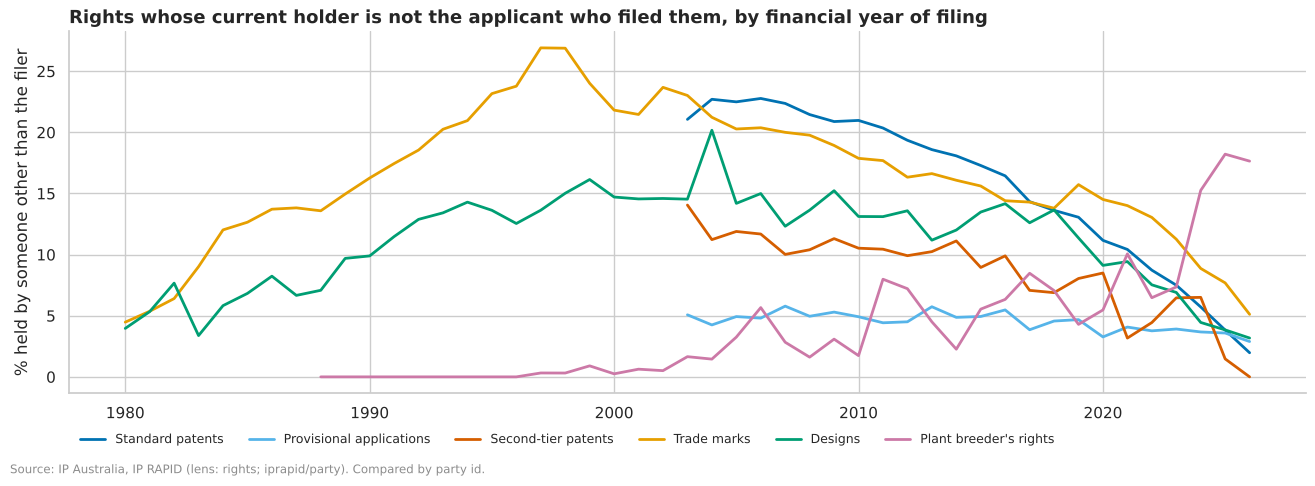

In [40]:
# How often the current holder is not the founding applicant, by type and decade of filing
changed = (
    sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, (filing_fy // 10) * 10 AS decade,
           100 * avg(holder_changed::int) AS pct
    FROM {lens/rights} WHERE filing_fy BETWEEN 1970 AND 2026 GROUP BY ALL
""")
    .pivot(index="decade", columns="t", values="pct")[list(TYPES)]
    .rename(columns=TYPES)
)

by_year = sql("""
    SELECT filing_fy, coalesce(patent_type, ip_right_type) AS t, 100 * avg(holder_changed::int) AS pct
    FROM {lens/rights} WHERE filing_fy BETWEEN 1980 AND 2026 GROUP BY ALL
""")
fig, ax = plt.subplots(figsize=(13, 4.5))
for t, name in TYPES.items():
    d = by_year[by_year.t == t].set_index("filing_fy").pct.sort_index()
    ax.plot(d.index, d, color=TYPE_COLOURS[t], lw=2, label=name)
ax.set_ylabel("% held by someone other than the filer")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=6)
ax.set_title("Rights whose current holder is not the applicant who filed them, by financial year of filing")
style.source(fig, "IP Australia, IP RAPID (lens: rights; iprapid/party). Compared by party id.")
print("% whose holder differs from the filer, by decade of filing")
changed.round(1)

In [41]:
# Why holder_changed is empty for patents filed before FY2003 (ADR 0013): IP RAPID keeps one set of applicants for them,
# entered long after filing, though many were assigned. Standard patents, from IP RAPID's party and events tables.
sql("""
    WITH p AS (
        SELECT application_number, bool_or(is_founding AND NOT is_current) AS founder_replaced,
               min(effective_from_date) AS first_record
        FROM {iprapid/party}
        WHERE ip_right_type = 'patent' AND party_role_category IN ('applicant', 'owner') GROUP BY 1
    ),
    assigned AS (
        SELECT DISTINCT application_number FROM {iprapid/events}
        WHERE ip_right_type = 'patent' AND event_type LIKE 'published_assignments%'
    )
    SELECT r.filing_fy, count(*) AS "standard patents",
           100 * avg(founder_replaced::int) AS "% with a founding record since replaced",
           100 * avg((s.application_number IS NOT NULL)::int) AS "% with an assignment event",
           median(date_diff('day', r.application_date, p.first_record)) AS "median days, filing to first record"
    FROM {lens/rights} r JOIN p USING (application_number) LEFT JOIN assigned s USING (application_number)
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 1998 AND 2006
    GROUP BY 1 ORDER BY 1
""")

,filing_fy,standard patents,% with a founding record since replaced,% with an assignment event,"median days, filing to first record"
0,1998,17804,0.0337,16.1,"7,445"
1,1999,18936,0.07393,15.26,"7,067"
2,2000,21187,0.1369,15.48,"6,697"
3,2001,22579,0.434,14.61,"6,336"
4,2002,22600,0.9115,15.4,"5,974"
5,2003,22030,62.14,16.41,8
6,2004,21985,67.34,16.16,3
7,2005,23497,64.76,15.83,3
8,2006,24699,63.69,15.15,3


In [42]:
# Rights whose origin changed between filing and now: all years, where the holder history is recorded (from FY2003 for
# patents) and the origin is known at both ends
origin = (
    sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t,
           count(*) FILTER (founding_australian) AS "filed from Australia",
           100 * avg((NOT australian_applicant)::int) FILTER (founding_australian) AS "% of those now held overseas",
           count(*) FILTER (NOT founding_australian) AS "filed from overseas",
           100 * avg(australian_applicant::int) FILTER (NOT founding_australian) AS "% of those now held in Australia",
           count(*) FILTER (founding_australian AND NOT australian_applicant) AS "Australian to overseas",
           count(*) FILTER (NOT founding_australian AND australian_applicant) AS "overseas to Australian"
    FROM {lens/rights}
    WHERE holder_changed IS NOT NULL AND founding_australian IS NOT NULL AND australian_applicant IS NOT NULL
    GROUP BY 1
""")
    .set_index("t")
    .loc[list(TYPES)]
    .rename(index=TYPES)
)
origin

,filed from Australia,% of those now held overseas,filed from overseas,% of those now held in Australia,Australian to overseas,overseas to Australian
t,,,,,,
Standard patents,63385,3.212,607884,0.1323,2036,804
Provisional applications,137179,0.3105,5963,1.409,426,84
Second-tier patents,21813,0.651,18826,0.3081,142,58
Trade marks,1408143,1.093,886860,0.5457,15391,4840
Designs,103102,1.649,124295,0.3637,1700,452
Plant breeder's rights,5373,0.4467,6319,0.269,24,17


In [43]:
# Australian filers' rights since moved overseas, by decade of filing (standard patents and trade marks; where the
# holder history is recorded)
sql("""
    SELECT (filing_fy // 10) * 10 AS decade,
           count(*) FILTER (patent_type = 'standard' AND founding_australian)
               AS "standard patents filed from Australia",
           100 * avg((NOT australian_applicant)::int) FILTER (patent_type = 'standard' AND founding_australian)
               AS "% now held overseas",
           count(*) FILTER (ip_right_type = 'trade_mark' AND founding_australian) AS "trade marks filed from Australia",
           100 * avg((NOT australian_applicant)::int) FILTER (ip_right_type = 'trade_mark' AND founding_australian)
               AS "% now held overseas "
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 1980 AND 2026 AND australian_applicant IS NOT NULL AND holder_changed IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")

,decade,standard patents filed from Australia,% now held overseas,trade marks filed from Australia,% now held overseas
0,1980,0,NaN,75637,1.275
1,1990,0,NaN,157742,2.205
2,2000,18299,5.481,335895,1.545
3,2010,25644,3.042,430568,0.9374
4,2020,18658,1.34,354675,0.4517


In [44]:
# The filer's place and ABN against the holder's, for rights filed FY2003 to FY2026 (when patents' holder history
# begins) by an Australian founding applicant and still held by an Australian one (the review's N02)
gap = sql("""
    SELECT count(*) FILTER (founding_australian AND founder_country IS DISTINCT FROM 'au') AS n,
           count(*) FILTER (founding_australian AND founder_country IS DISTINCT FROM 'au'
                            AND founder_postcode IS NOT NULL) AS with_postcode
    FROM {lens/rights}
""")
print(
    f"Rights whose first founding applicant is not Australian, though another is: {gap.n[0]:,}; "
    f"with a filer postcode: {gap.with_postcode[0]:,}"
)
sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, count(*) AS rights,
           100 * avg((founder_postcode IS NOT NULL)::int) AS "% filer postcode",
           100 * avg((applicant_postcode IS NOT NULL)::int) AS "% holder postcode",
           100 * avg((founder_postcode <> applicant_postcode)::int)
               FILTER (founder_postcode IS NOT NULL AND applicant_postcode IS NOT NULL) AS "% postcodes differ",
           100 * avg((founder_state <> applicant_state)::int)
               FILTER (founder_state IS NOT NULL AND applicant_state IS NOT NULL) AS "% states differ",
           100 * avg((founder_abn IS NOT NULL)::int) AS "% filer ABN",
           100 * avg((applicant_abn IS NOT NULL)::int) AS "% holder ABN",
           100 * avg((founder_abn <> applicant_abn)::int)
               FILTER (founder_abn IS NOT NULL AND applicant_abn IS NOT NULL) AS "% ABNs differ"
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 2003 AND 2026 AND founding_australian AND australian_applicant
    GROUP BY 1 ORDER BY rights DESC
""")

Rights whose first founding applicant is not Australian, though another is: 4,085; with a filer postcode: 4,019


,t,rights,% filer postcode,% holder postcode,% postcodes differ,% states differ,% filer ABN,% holder ABN,% ABNs differ
0,trade_mark,1033272,99.99,99.94,11.13,2.673,58.05,58.96,6.716
1,provisional,134167,99.98,99.69,2.062,0.4448,43.84,44.49,1.739
2,standard,60568,99.97,99.17,10.11,2.644,62.37,64.61,7.202
3,design,57360,99.72,99.54,7.702,2.423,61.29,62.39,6.706
4,second_tier,21663,99.99,99.63,6.26,1.589,38.48,40.08,5.912
5,pbr,3594,69.14,71.51,3.027,2.455,0,0,NaN


representation          attorney  other_agent  self
t           filer                                  
standard    Australian      85.4          1.4  13.2
            overseas          99          0.2   0.9
second_tier Australian      62.2          4.4  33.3
            overseas        84.2          5.8    10
trade_mark  Australian      49.7          7.4  42.9
            overseas        88.2          8.1   3.7
design      Australian      68.5          2.4  29.1
            overseas        95.8            3   1.2
pbr         Australian      24.7         16.8  58.5
            overseas        59.2         37.7   3.1

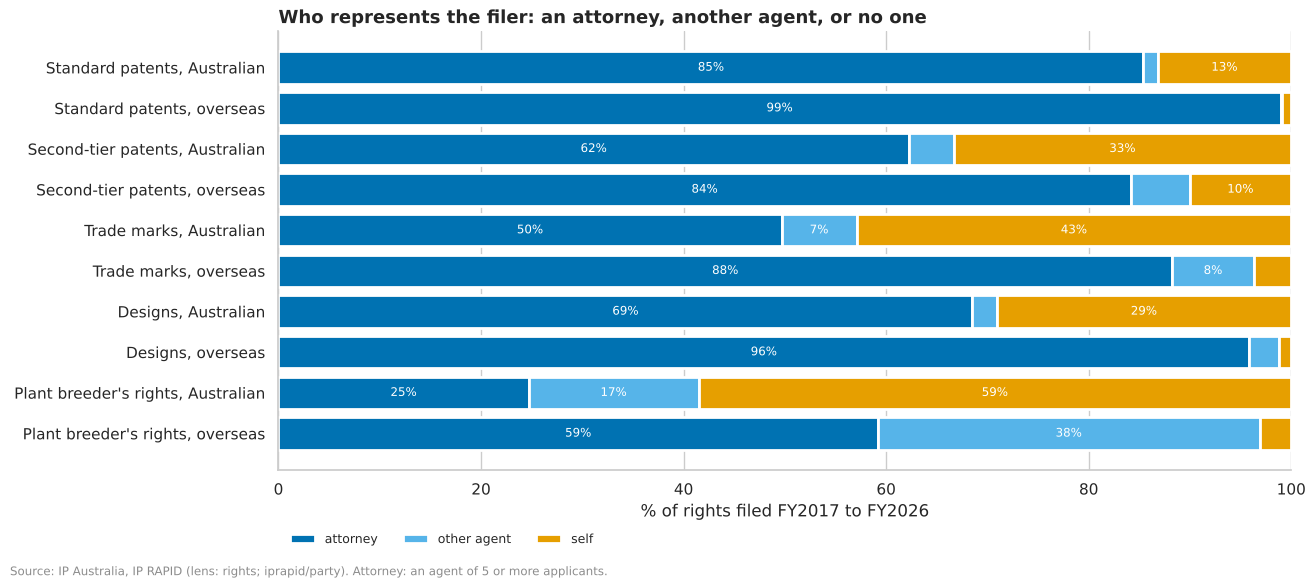

In [45]:
# Who represents the filer, FY2017 to FY2026, by the filer's origin and type (provisionals have no agents published)
import numpy as np

rep = sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t,
           CASE WHEN founding_australian THEN 'Australian' ELSE 'overseas' END AS filer,
           coalesce(founder_type, 'not recorded') AS founder_type, representation, count(*) AS n
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 2017 AND 2026 AND representation IS NOT NULL AND founding_australian IS NOT NULL
    GROUP BY ALL
""")
REP = ["attorney", "other_agent", "self"]
REP_COLOURS = {"attorney": style.MAIN, "other_agent": style.PALETTE[4], "self": style.ACCENT}
share_rep = rep.pivot_table(index=["t", "filer"], columns="representation", values="n", aggfunc="sum", fill_value=0)
share_rep = (100 * share_rep.div(share_rep.sum(axis=1), axis=0))[REP]

rows = [(t, f) for t in TYPES if t != "provisional" for f in ("Australian", "overseas")]
d = share_rep.loc[rows]
labels = [f"{TYPES[t]}, {f}" for t, f in rows][::-1]
fig, ax = plt.subplots(figsize=(13, 5.5))
left = np.zeros(len(d))
for r in REP:
    v = d[r].to_numpy()[::-1]
    ax.barh(labels, v, left=left, color=REP_COLOURS[r], edgecolor="white", linewidth=2, label=r.replace("_", " "))
    for y, (x0, w) in enumerate(zip(left, v, strict=True)):
        if w >= 6:
            ax.text(x0 + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left += v
ax.set_xlim(0, 100)
ax.set_xlabel("% of rights filed FY2017 to FY2026")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
ax.set_title("Who represents the filer: an attorney, another agent, or no one")
style.source(fig, "IP Australia, IP RAPID (lens: rights; iprapid/party). Attorney: an agent of 5 or more applicants.")
d.round(1)

In [46]:
# Australian filers only, by the founding applicant's type: individuals against organisations
by_type = rep[rep.filer == "Australian"].pivot_table(
    index=["t", "founder_type"], columns="representation", values="n", aggfunc="sum", fill_value=0
)
by_type = (100 * by_type.div(by_type.sum(axis=1), axis=0))[REP].assign(rights=by_type.sum(axis=1))
by_type.loc[[t for t in TYPES if t != "provisional"]].round(1)

representation            attorney  other_agent  self  rights
t           founder_type                                     
standard    individual        58.8          4.1  37.1    5740
            organisation      92.7          0.6   6.7   20931
second_tier individual        41.7            6  52.4    2990
            organisation      77.8          3.2  18.9    3945
trade_mark  individual          28          9.6  62.4  122828
            organisation      56.9          6.7  36.4  369081
design      individual        48.4          2.9  48.7    5019
            organisation      73.8          2.2    24   19215
pbr         individual          25         24.6  50.4     232
            organisation      24.6         15.2  60.2    1140

In [47]:
# How much the attorney threshold matters: the share represented by an agent of at least k applicants, FY2017 to FY2026
sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t,
           CASE WHEN founding_australian THEN 'Australian' ELSE 'overseas' END AS filer,
           count(*) AS rights,
           100 * avg(coalesce(agent_clients >= 1, false)::int) AS "k = 1 (any agent but the applicant)",
           100 * avg(coalesce(agent_clients >= 2, false)::int) AS "k = 2",
           100 * avg(coalesce(agent_clients >= 5, false)::int) AS "k = 5 (the lens)",
           100 * avg(coalesce(agent_clients >= 20, false)::int) AS "k = 20",
           100 * avg(coalesce(agent_clients >= 100, false)::int) AS "k = 100"
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 2017 AND 2026 AND representation IS NOT NULL AND founding_australian IS NOT NULL
      AND (patent_type = 'standard' OR ip_right_type IN ('trade_mark', 'design'))
    GROUP BY ALL ORDER BY 1, 2
""")

,t,filer,rights,k = 1 (any agent but the applicant),k = 2,k = 5 (the lens),k = 20,k = 100
0,design,Australian,24234,70.9,69.73,68.52,67.82,64.09
1,design,overseas,55389,98.8,97.14,95.85,95.31,93.94
2,standard,Australian,26671,86.81,85.94,85.41,85.19,84.4
3,standard,overseas,278327,99.13,99.03,98.96,98.87,98.56
4,trade_mark,Australian,491909,57.08,52.73,49.67,46.73,42.59
5,trade_mark,overseas,339154,96.32,92.69,88.22,78.8,66.19


In [48]:
# The attorney firms: how concentrated, FY2017 to FY2026 (rights represented by an attorney)
firms_rep = sql("""
    WITH a AS (
        SELECT coalesce(patent_type, ip_right_type) AS t, agent_id, count(*) AS n
        FROM {lens/rights}
        WHERE filing_fy BETWEEN 2017 AND 2026 AND representation = 'attorney'
          AND (patent_type = 'standard' OR ip_right_type IN ('trade_mark', 'design'))
        GROUP BY 1, 2
    ),
    ranked AS (
        SELECT *, row_number() OVER w AS rank,
               sum(n) OVER w / sum(n) OVER (PARTITION BY t) AS cum, n / sum(n) OVER (PARTITION BY t) AS share
        FROM a WINDOW w AS (PARTITION BY t ORDER BY n DESC, agent_id ROWS UNBOUNDED PRECEDING)
    )
    SELECT t, count(*) AS attorneys, sum(n) AS rights,
           100 * sum(n) FILTER (rank <= 5) / sum(n) AS "% top 5",
           100 * sum(n) FILTER (rank <= 10) / sum(n) AS "% top 10",
           count(*) FILTER (cum - share < 0.5) AS "attorneys for half",
           count(*) FILTER (cum - share < 0.9) AS "attorneys for 90%"
    FROM ranked GROUP BY 1 ORDER BY rights DESC
""")
firms_rep

,t,attorneys,rights,% top 5,% top 10,attorneys for half,attorneys for 90%
0,trade_mark,9754,5.437e+05,17.51,25.08,65,1753
1,standard,363,2.982e+05,63.96,79.56,4,27
2,design,615,7.108e+04,45.17,60.29,7,85


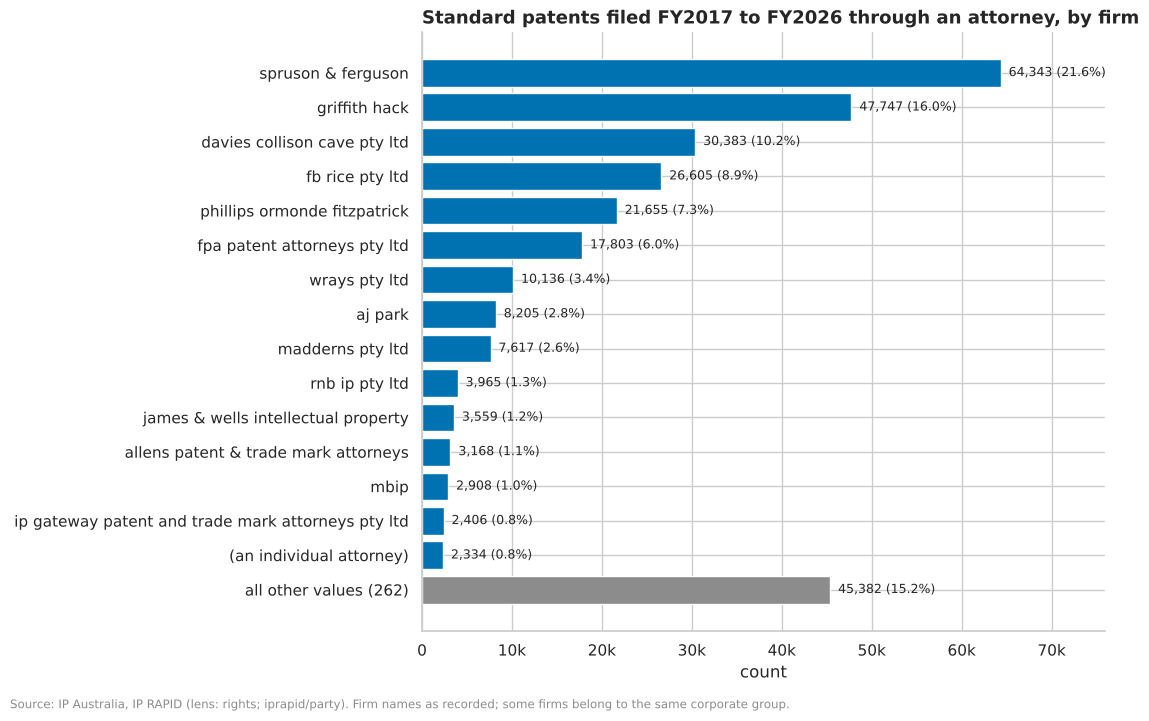

In [49]:
std_att = rights.loc[
    (rights.patent_type == "standard") & rights.filing_fy.between(2017, 2026) & (rights.representation == "attorney"),
    "agent_name",
]
fig = uni.counts(
    std_att.fillna("(an individual attorney)"),
    top=15,
    title="Standard patents filed FY2017 to FY2026 through an attorney, by firm",
)
style.source(
    fig,
    "IP Australia, IP RAPID (lens: rights; iprapid/party). Firm names as recorded; some firms belong "
    "to the same corporate group.",
)

##### Observations
**U17 (descriptive). The holder is often not the filer, and for old patents it cannot be told.**
- Where the history is recorded, the current holder is not the founding applicant for 22.0% of standard patents filed
  in the 2000s (from FY2003), 17.1% of the 2010s' and 7.0% of the 2020s'; for trade marks 20.8%, 15.7% and 10.4%; for
  designs 14.9%, 12.8% and 6.1%; for provisional applications 3.5% to 5.0%. Newer rights have had less time to change
  hands (the chart falls towards the present).
- Trade marks filed in the 1990s (22.1%) changed hands more often than those of the 1980s (12.1%) and 1970s (4.1%),
  so changes to old rights look less fully recorded.
- **Patents filed before FY2003 have one set of applicants.** Their first applicant record starts a median 5,974 to
  7,445 days after filing (FY1998 to FY2002), against 3 to 8 days from FY2003, though 14.61% to 16.1% of them have an
  assignment event. The records were entered when the data moved between systems, so a change of holder was not
  kept. `holder_changed` is empty for them (filled for 79.09% of rights in all), and their founding columns may
  describe a later holder (ADR 0013).
- Plant breeder's rights go the other way: 11.2% of those filed in the 2020s are held by someone other than the
  filer, more than in any earlier decade. The data do not say why.

**U18 (descriptive). More Australian-filed rights moved overseas than came the other way.** Where the history is
recorded:
- **Standard patents:** 3.212% of the 63,385 filed from Australia are now held overseas (2,036), against 0.1323% of
  those filed from overseas now held in Australia (804). By decade of filing: 5.481% (2000s), 3.042% (2010s) and
  1.34% (2020s).
- **Trade marks:** 1.093% of 1,408,143 moved overseas (15,391), and 0.5457% came the other way (4,840).
- **Designs:** 1.649% moved overseas (1,700), and 0.3637% came the other way (452).
- These are counts of rights, not of their value; Stage 2 can relate them to technology, firm and the age of the
  right.

**U19 (descriptive). The filer's postcode differs from the holder's for about a tenth of rights (the review's N02).**
For rights filed FY2003 to FY2026 from Australia and still held in Australia:
- Postcodes differ for 11.13% of trade marks, 10.1% of standard patents, 7.7% of designs, 6.26% of second-tier patents
  and 2.061% of provisional applications; states differ for only 1.585% to 2.672% (0.4425% for provisionals), so most
  moves are within a state.
- ABNs differ for 5.912% to 7.202% of each type where both exist.
- The filer's postcode is known for 99.72% to 99.99% of each type (plant breeder's rights 69.14%), and 4,019 of the
  4,085 rights whose first founding applicant is not Australian, though another is, now have one.
- The review measured 7% (patents) and 11% (trade marks) for 2000 to 2026; patents filed before FY2003 cannot differ,
  which explains the lower patent figure.
- **Decision:** in Stage 2, "where and who files" uses the founding columns, and "who holds" the applicant columns.
  The `regions` and `firms` lenses count applications by the current holder today; each switches to the filer in its
  own section (ADR 0013).

**U20 (descriptive). Overseas filers almost always use an attorney; Australian individuals often file alone.**
FY2017 to FY2026:
- **Overseas filers:** an attorney for 99.0% of standard patents, 95.8% of designs and 88.2% of trade marks (8.1%
  through another agent, 3.7% alone).
- **Australian filers:** an attorney for 85.4% of standard patents (13.2% alone), 68.5% of designs (29.1% alone),
  62.2% of second-tier patents (33.3% alone) and 49.7% of trade marks (42.9% alone, 7.4% through another agent).
- **Individuals file alone most:** 37.1% of Australian individuals' standard patents (6.7% of organisations'),
  48.7% of their designs (24.0%) and 62.4% of their trade marks (36.4%).
- **The threshold matters for trade marks, not patents.** Counting agents of at least 1, 5 or 100 applicants,
  Australian standard patents are represented 86.81%, 85.41% and 84.4% of the time; Australian trade marks 57.08%,
  49.67% and 42.59%; overseas trade marks 96.32%, 88.22% and 66.19%.
- **Plant breeder's rights** show many "other agents" (16.8% of Australian filers' and 37.7% of overseas filers'). The
  register is small (11,732 rights in all), so a specialist agent may act for fewer than five applicants; for these
  rights, attorney and other agent are read together.
- **Decision:** Stage 2 uses `representation` (five or more applicants), with the shares at 1 and 20 applicants as
  bounds for trade marks.

**U21 (descriptive). Patent attorneys are concentrated; trade mark representation is not.** FY2017 to FY2026,
rights filed through an attorney:
- **Standard patents:** 363 attorneys; the top 5 handle 63.96% and the top 10 79.56%; 4 handle half and 27 handle 90%.
  Spruson & Ferguson 64,343 (21.6%), Griffith Hack 47,747 (16.0%), Davies Collison Cave 30,383 (10.2%), FB Rice
  26,605 (8.9%) and Phillips Ormonde Fitzpatrick 21,655 (7.3%).
- **Designs:** 615 attorneys; the top 5 handle 45.17%, and 7 handle half.
- **Trade marks:** 9,754 attorneys; the top 5 handle 17.51% and the top 10 25.08%; 65 handle half and 1,753 handle 90%.
- Counted by firm name, this is a lower bound: some of these firms belong to the same corporate groups, which IP RAPID
  does not record.

### 1.9 Summary of the IP rights lens

| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| U1 | One row per right; columns complete where they should be | 4,368,006 rights, 0 repeats; origin known for 86.37% | Descriptive | All stages use the lens as built |
| U2 | Five repairs: a 1970 placeholder, a pre-1904 registration, trade marks registered at filing, a class posing as a technology area, and attorney use | 1,282; 1; 121,207 of 122,980; 2,335,057 and 248,748; 57.02% not 100% for Australian trade marks | Descriptive | ADR 0012; every later use of these columns |
| U3 | Rushes to file before two rule changes; 61,854 rights cannot be placed in time | 1,856 on 12 April 2013; 1,342 on 25 August 2021; 50,711 patents and 11,143 designs undated | Descriptive | Stage 2 measures the rushes (timeline, 5.4) |
| U4 | Trade marks are most rights; standard patents most patents | 53.5% trade marks; 82.17% of patents standard | Descriptive | Totals by type; patent headlines use standard patents |
| U5, U6 | Annual counts are complete to FY2026; second-tier patents ended in FY2021 | FY2026: 31,136 standard patents, 98,189 trade marks; second-tier 7,150 then 52 | Descriptive | Stage 2 trends to FY2026; FY2027 left out; trade marks before 1983, designs before 1986 and provisionals before September 1985 are survivors (U23) |
| U7 | About nine in ten standard patents come from overseas; design origin is often unrecorded | Standard patents 7.9% to 12.4% Australian since FY1990; designs 4.0% to 23.3% unknown | Descriptive | Australian shares from FY1990; designs shown with their unknown share |
| U8 | Provisional applications doubled in FY2026, from individuals without ABNs, broadly and from a few heavy filers | 10,069 against 5,047; individuals 5,399; distinct ABNs flat at 1,361; 54 individuals filed 10+ | Descriptive | Stage 2: against policy and fee events; IP Australia's figures |
| U9, U10 | Lapsed is not ceased; old patents have no outcome; grant rates vary by year | Ceased 99.93% registered, lapsed under 0.01%; 408,957 "unknown"; standard grant rate 54.4% (FY2008) to 75.5% (FY2000) | Descriptive | Rates only for decided years; lifetimes with the events attachment (B5) |
| U11, U12 | Registration takes about 2.7 years for standard patents and 7 months for trade marks, with a 222-day peak | Medians 980 and 223 days (FY2010 to FY2019) | Descriptive | Stage 2 compares times by origin and applicant within decided years; the 222-day peak is a lead |
| U13 | Australians file without attorneys far more often than overseas applicants; 12% to 22% of Australian organisations' rights have no ABN | Attorneys 57.02% (Australian trade marks) against 96.27%; ABN 87.98% and 78.3% | Descriptive | Stage 2 (who self-files); the `firms` lens's coverage |
| U14 | Health fields lead standard patents; services lead trade marks | 32.0% medical, pharmaceutical and biotechnology; class 35 11.7% | Descriptive | The `industries` lens (B6) |
| U15, U16 | New South Wales and Victoria lead; postcodes usable for 99.3% | Standard patents 38.2% and 23.7%; state repaired for 34.96% of FY2024 on | Descriptive | The `regions` lens |
| U17 | The holder differs from the filer for about a fifth of standard patents and trade marks filed in the 2000s; patents' history starts in FY2003 | 22.0% and 20.8%; before FY2003 first records 5,974 to 7,445 days after filing | Descriptive | `holder_changed` empty before FY2003 (ADR 0013) |
| U18 | More Australian-filed rights moved overseas than came the other way | Standard patents 2,036 against 804; trade marks 15,391 against 4,840 | Descriptive | Stage 2: by technology, firm and age of right |
| U19 | The filer's postcode differs from the holder's for about a tenth of rights | 10.1% of standard patents, 11.13% of trade marks (FY2003 to FY2026) | Descriptive | Stage 2 "where and who files" uses the founding columns; `regions` and `firms` switch in their sections |
| U20 | Overseas filers almost always use an attorney; Australian individuals often file alone | 99.0% against 85.4% (standard patents); 62.4% of Australian individuals' trade marks filed alone | Descriptive | Stage 2: filing alone by type, origin and applicant; trade marks with bounds |
| U21 | Patent attorneys are concentrated; trade mark representation is not | Top 5: 63.96% of standard patents, 17.51% of trade marks | Descriptive | Q4 (the cost of access); corporate groups not recorded |

## 2. Lens: Firms (one row per ABN)

Every ABN that appears in IP Australia's data, the R&D Tax Incentive, AusTender or the ATO's tax transparency
reports (the corpus's `linkage/abn_spine`), with their IP applications, R&D claims, income and place.

### 2.0 Data overview and sanity checks

In [50]:
firms = load_lens("firms")
print(f"{len(firms):,} rows, {firms.shape[1]} columns; {firms.abn.nunique():,} distinct ABNs")
uni.overview(firms, "firms")

398,450 rows, 37 columns; 398,450 distinct ABNs


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
abn,ABN,id,str,100,398450,NaN,NaN,NaN
entity_type,Entity type (ABR),category,str,99.98,57,NaN,NaN,Australian Private Company (74.7%)
entity_group,Entity group,category,str,99.98,8,NaN,NaN,Private company (74.7%)
abn_active,ABN is active,binary,boolean,99.98,2,NaN,NaN,True (62.4%)
gst_registered,Registered for GST,binary,boolean,99.98,2,NaN,NaN,False (51.4%)
state,State,category,str,99.98,9,NaN,NaN,NSW (35.5%)
postcode,Postcode,category,str,99.29,2802,NaN,NaN,2000 (4.6%)
remoteness,Remoteness of postcode,category,str,98.9,6,NaN,NaN,Major Cities of Australia (85.2%)
irsad_decile,Advantage of postcode (IRSAD decile),numeric,float64,98.54,10,1,10,10.0 (34.0%)


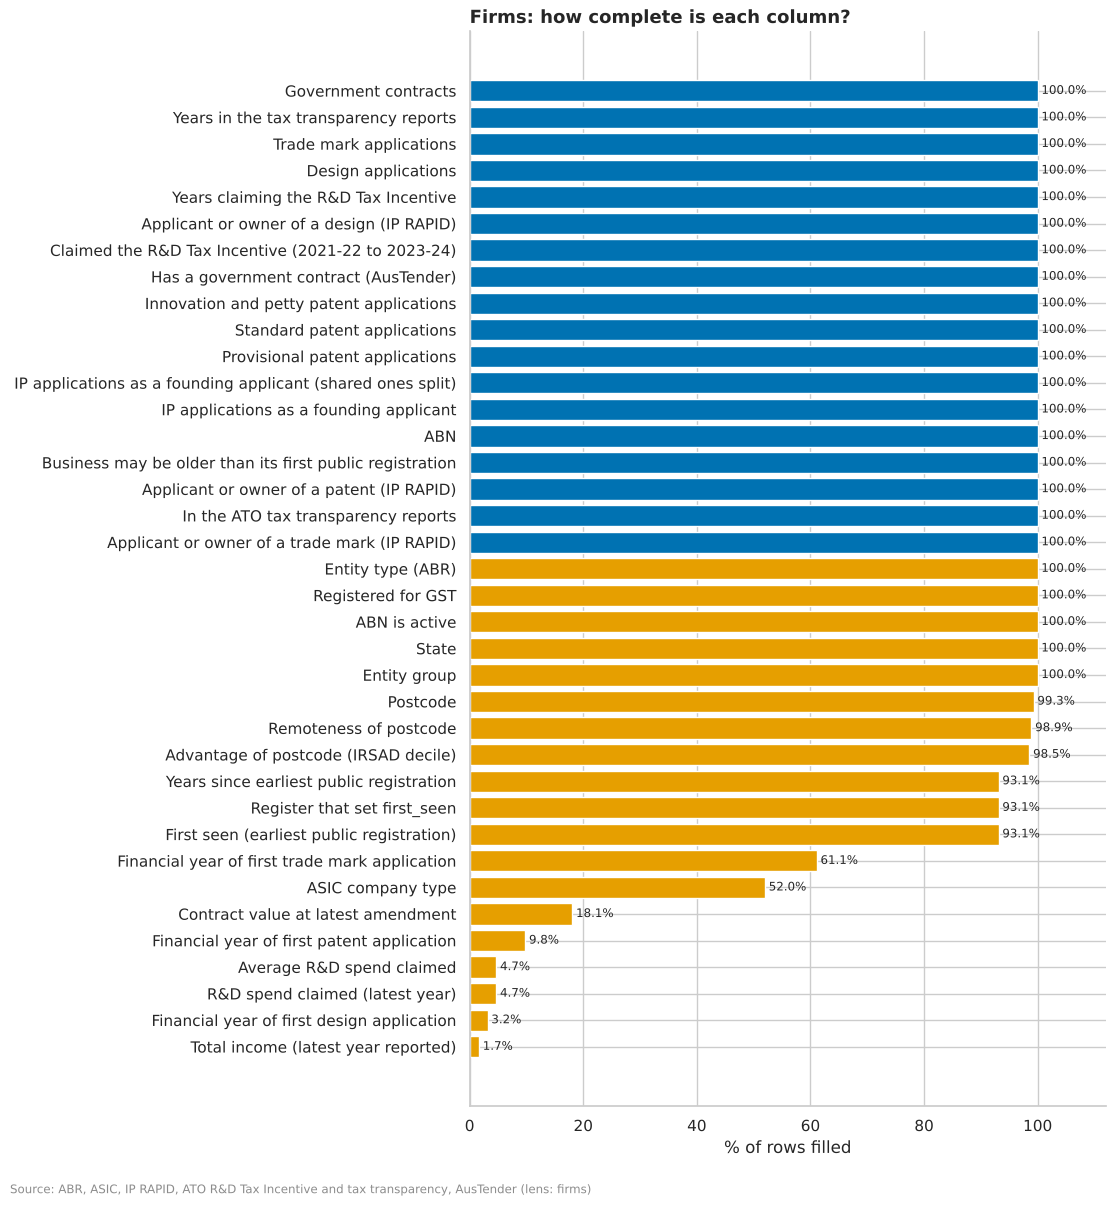

In [51]:
fig = uni.missing(firms, "firms", title="Firms: how complete is each column?")
style.source(fig, "ABR, ASIC, IP RAPID, ATO R&D Tax Incentive and tax transparency, AusTender (lens: firms)")

#### Observations from the overview
_To be written._ To check here: who is in the lens (it is not all Australian businesses, only those in at least one
source), so rates computed on it are rates among these ABNs.

### 2.1 Entity type and status

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Entity groups, active ABNs, GST registration (`uni.counts`).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.2 Age

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q3. **Helpers:** `uni.distribution`, `uni.bin_check`.

- [ ] Distribution of age in years; spikes at known registration waves (the ABN began in 1999-2000).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.3 IP use

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q3. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] How many firms hold each kind of right; the distribution of applications per firm (expected to be very skewed).
- [ ] The heaviest filers: how much of all filing do the top 1% of firms account for?

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.4 R&D, income and government contracts

*Planned for Stage 1 (not yet run).* **Informs:** Q3, Q4. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] R&D Tax Incentive claims (years, spend); income for the large firms in the tax reports; AusTender contracts.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.5 Place: state, remoteness, advantage

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Firms by state, remoteness and IRSAD decile of their postcode.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.6 Summary of the firms lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 3. Lens: Places (one row per postal area)

Every Australian postal area, with its population, remoteness, socio-economic indexes (SEIFA 2021), Census medians,
business counts (ABR) and IP applications by Australian applicants over FY2017 to FY2026.

### 3.0 Data overview and sanity checks

In [52]:
regions = load_lens("regions")
print(f"{len(regions):,} postal areas, {regions.shape[1]} columns; {regions.persons.sum():,.0f} people")
uni.overview(regions, "regions")

2,641 postal areas, 31 columns; 25,365,506 people


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
poa_code,Postal area,id,str,100,2641,NaN,NaN,NaN
state,State,category,str,100,9,NaN,NaN,Victoria (26.3%)
remoteness,Remoteness,category,str,100,5,NaN,NaN,Major Cities of Australia (37.7%)
share_major_cities,Share of people in major cities,rate,float64,99.92,138,0,1,0.0 (61.6%)
persons,Population (2021 Census) (people),count,Int64,100,2280,0,"129,883",115 (0.2%)
irsad_score,Socio-economic advantage and disadvantage (IRS...,numeric,float64,99.36,378,659,"1,185",939.0 (1.0%)
irsad_decile,IRSAD decile,numeric,float64,99.36,10,1,10,9.0 (10.0%)
irsd_score,Socio-economic disadvantage (IRSD score),numeric,float64,99.36,349,492,"1,166",1006.0 (1.1%)
irsd_decile,IRSD decile,numeric,float64,99.36,10,1,10,9.0 (10.0%)


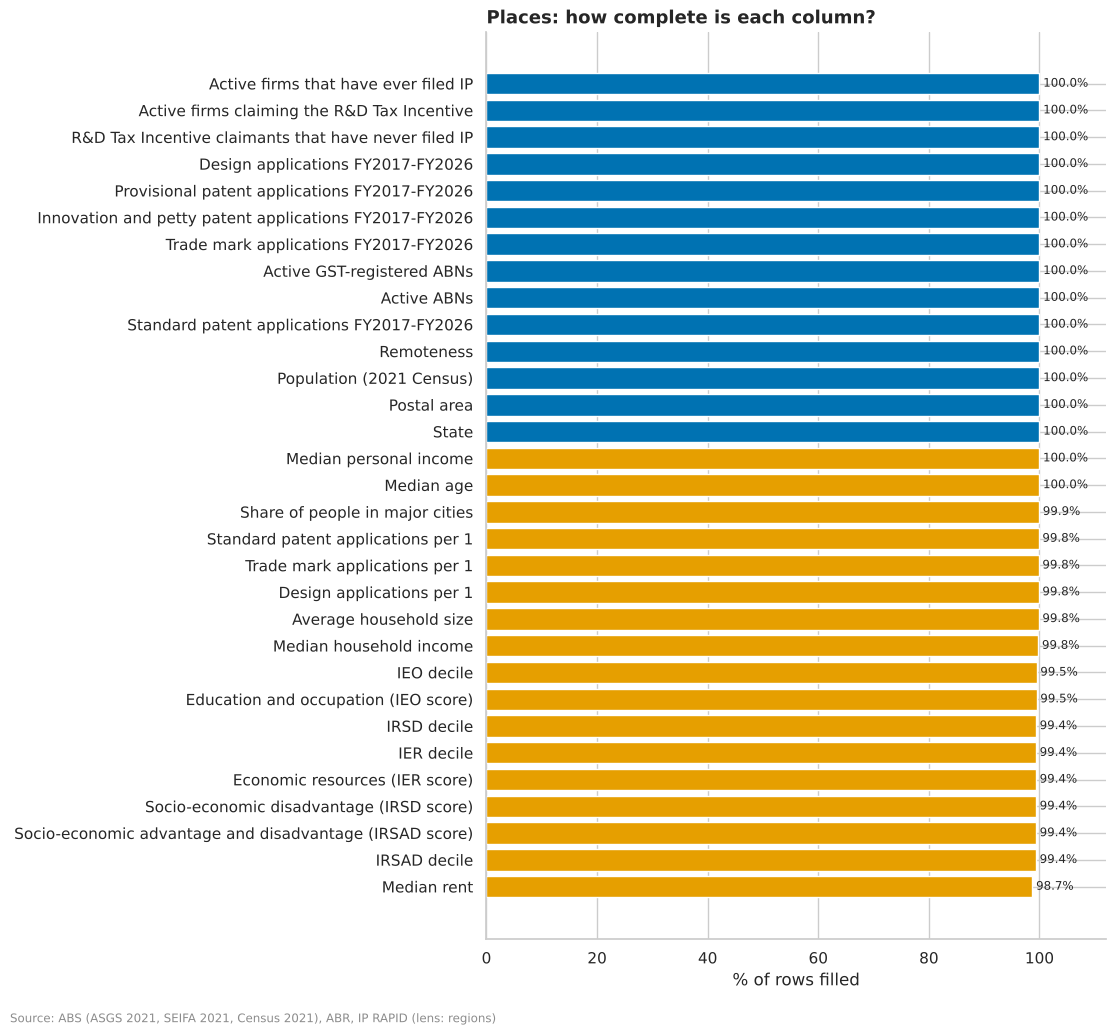

In [53]:
fig = uni.missing(regions, "regions", title="Places: how complete is each column?")
style.source(fig, "ABS (ASGS 2021, SEIFA 2021, Census 2021), ABR, IP RAPID (lens: regions)")

#### Observations from the overview
_To be written._ Leads to check, found while building the skeleton:
- Some postal areas have no usual residents (for example, business districts or parks), so rates per person or per
  business will be unstable or undefined there. The Census gives 0 for a median that describes no one; those medians
  are now empty (ADR 0010), so the zeros left in the table are real counts.
- SEIFA scores are missing for 0.64% of postal areas (99.36% filled).

### 3.1 Population and businesses

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.distribution(log=True)`.

- [ ] Distribution of people and GST-registered businesses per postal area; very small areas.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.2 Remoteness and socio-economic indexes

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`, `uni.distribution`.

- [ ] Postal areas by remoteness; the four SEIFA scores and deciles.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.3 IP applications and rates

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q4. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] Applications per postal area and per 1,000 businesses, by type: how concentrated (share of the top 10 areas).
- [ ] Areas with no applications at all.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.4 R&D claimants and 'missing filers'

*Planned for Stage 1 (not yet run).* **Informs:** Q4. **Helpers:** `uni.describe`.

- [ ] R&D Tax Incentive claimants per area, and those that have never filed IP.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.5 Summary of the places lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 4. Lens: Australia and other countries (one row per country, year and indicator)

24 World Bank indicators (IP filings, IP royalties, R&D, researchers, GDP, exports), WIPO's filings by residents of
each country at every office, and the OECD's R&D intensity, for every country. One variable here is one indicator.

### 4.0 Data overview and sanity checks

In [54]:
coverage = sql("""
    SELECT source, indicator, any_value(indicator_name) AS name,
           count(DISTINCT iso3) AS countries, min(year) AS first_year, max(year) AS last_year,
           count(*) FILTER (australia) AS australia_years,
           max(year) FILTER (australia) AS australia_latest
    FROM {lens/national} GROUP BY 1, 2 ORDER BY 1, 2
""")
coverage

,source,indicator,name,countries,first_year,last_year,australia_years,australia_latest
0,OECD,OECD.MSTI.B,"Business Enterprise Expenditure on R&D (BERD),...",47,1981,2025,36,2023
1,OECD,OECD.MSTI.G,"Gross Domestic Expenditure on R&D (GERD), % of...",47,1981,2025,23,2023
2,WDI,BM.GSR.ROYL.CD,"Charges for the use of intellectual property, ...",179,1960,2025,37,2025
3,WDI,BX.GSR.ROYL.CD,"Charges for the use of intellectual property, ...",174,1962,2025,37,2025
4,WDI,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",203,1970,2025,56,2025
5,WDI,GB.XPD.RSDV.GD.ZS,Research and development expenditure (% of GDP),156,1996,2024,14,2021
6,WDI,IC.BUS.NDNS.ZS,"New business density (new registrations per 1,...",183,2006,2024,19,2024
7,WDI,IC.BUS.NREG,New businesses registered (number),183,2006,2024,19,2024
8,WDI,IP.IDS.NRCT,"Industrial design applications, nonresident, b...",145,1980,2024,21,2024
9,WDI,IP.IDS.RSCT,"Industrial design applications, resident, by c...",146,1980,2024,21,2024


#### Observations from the overview
_To be written._ Leads to check, found while building the skeleton and in the last check before Stage 1 (ADR 0010):
- Australia's series for researchers in R&D ends in 2010 and for technicians in 2008. The World Bank's R&D
  expenditure (% of GDP) ends in 2021; the OECD's (`OECD.MSTI.G`, and business R&D, `OECD.MSTI.B`) is now beside it,
  to 2023. The two differ where they overlap (2021: 1.86% and 1.66%), so they are compared, never spliced.
- Trade mark applications by residents and non-residents (`IP.TMK.RSCT`, `IP.TMK.NRCT`, 2004 to 2024) are back, under
  the World Bank's current codes.
- The WIPO series count applications by residents of each country at every office, so they include Australians'
  filings abroad; the WDI patent series count filings at the national office only.

### 4.1 Each indicator for Australia over time

*Planned for Stage 1 (not yet run).* **Informs:** Q1. **Helpers:** `sql`, `uni.over_time`.

- [ ] Australia's series against the OECD median and range, one small chart per indicator.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 4.2 Each indicator across countries (latest year)

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q4. **Helpers:** `uni.distribution`.

- [ ] Distribution across OECD countries in the latest common year, with Australia marked.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 4.3 Summary of the national lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 5. Lens: Australia over time (one row per month)

IP Australia's whole register, month by month, from January 1904 to September 2026: applications by type and by
Australian or overseas applicant; what happened to rights (grants, lapses, expiries, oppositions, ownership
transfers, extensions of term), as counts of events; the Consumer Price Index, quarterly; and the month each of 17 IP
policy changes took effect or was enacted. A series is empty, not 0, before its records become continuous and
complete, and in the final months the register is still recording (ADR 0010 and 0014).

**Rules for this section** (from the plan):
- Counts are compared at the resolution they are recorded: monthly series by month or over 12 months, the CPI by
  quarter, never spread across months.
- Totals across types are not shown: each type is its own series, as in section 1.
- Everything here is descriptive. Before-and-after comparisons, with trends and seasons allowed for, are Stage 2's.

### 5.0 Data overview and sanity checks

In [55]:
timeline = load_lens("timeline")
span = f"{timeline.month.min():%B %Y} to {timeline.month.max():%B %Y}"
print(f"{len(timeline):,} months, {span}; {timeline.shape[1]} columns")
uni.overview(timeline, "timeline")

1,473 months, January 1904 to September 2026; 35 columns


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
month,Month,date,datetime64[s],100,1473,1904-01-01,2026-09-01,NaN
year,Year,year,Int64,100,123,1904,2026,1904 (0.8%)
month_of_year,Month of the year,category,int64,100,12,1,12,1 (8.4%)
fy,Financial year,year,Int64,100,124,1904,2027,1905 (0.8%)
days_in_month,Days in the month,count,Int64,100,4,28,31,31 (58.3%)
patents_standard_au,Standard patent applications from Australian a...,count,Int64,45.01,221,0,"1,018",0 (2.0%)
patents_standard_overseas,Standard patent applications from overseas app...,count,Int64,46.44,523,0,"5,407",8 (1.3%)
patents_standard_origin_unknown,Standard patent applications of unknown origin,count,Int64,100,587,0,"1,334",0 (18.8%)
patents_provisional,Provisional patent applications,count,Int64,33.47,296,172,"1,274",547 (1.0%)


In [56]:
# When each monthly series begins and ends (after the repairs), its total, and its busiest month
series = [c for c in timeline.columns if style.kind("timeline", c) == "count" and c != "days_in_month"]
pd.DataFrame(
    {
        "first month": {c: f"{timeline.month[timeline[c].notna()].min():%Y-%m}" for c in series},
        "last month": {c: f"{timeline.month[timeline[c].notna()].max():%Y-%m}" for c in series},
        "total": timeline[series].sum(),
        "busiest month": {c: f"{timeline.month[timeline[c].fillna(0).idxmax()]:%Y-%m}" for c in series},
        "count in busiest month": timeline[series].max(),
    }
)

,first month,last month,total,busiest month,count in busiest month
patents_standard_au,1971-07,2026-09,93686,2013-04,1018
patents_standard_overseas,1969-10,2026-09,849041,2013-04,5407
patents_standard_origin_unknown,1904-01,2026-09,445357,1969-07,1334
patents_provisional,1985-09,2026-09,253630,2026-03,1274
patents_second_tier,1979-05,2026-09,48241,2021-08,2789
trade_marks_au,1983-01,2026-09,1351635,2020-09,5771
trade_marks_overseas,1983-01,2026-09,821272,2025-07,3947
trade_marks_origin_unknown,1983-01,2026-09,30405,1984-09,404
designs_au,1986-01,2026-06,92929,2006-08,324
designs_overseas,1986-01,2026-06,119306,2024-10,697


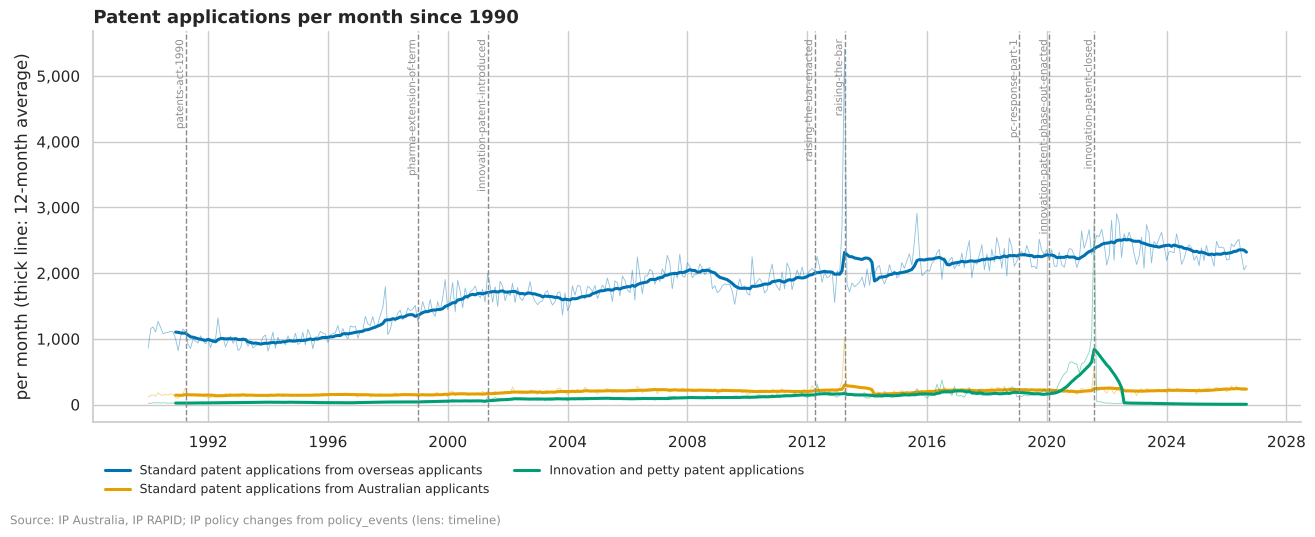

In [57]:
fig = uni.monthly(
    timeline,
    ["patents_standard_overseas", "patents_standard_au", "patents_second_tier"],
    start="1990-01-01",
    title="Patent applications per month since 1990",
    events=[  # the patent changes only
        "patents-act-1990",
        "pharma-extension-of-term",
        "innovation-patent-introduced",
        "raising-the-bar-enacted",
        "raising-the-bar",
        "pc-response-part-1",
        "innovation-patent-phase-out-enacted",
        "innovation-patent-closed",
    ],
)
style.source(fig, "IP Australia, IP RAPID; IP policy changes from policy_events (lens: timeline)")

#### Repairs made before this section (ADR 0014)

Profiling the series found that the rule which starts each one (the first month from which 9 of the next 12 have a
record, ADR 0010) starts 15 of them too early. Before their new starts, IP RAPID holds one of three things, none of
them a count of what happened that month:
- **survivors:** only the rights still on the register when its records were computerised, so applications that
  failed earlier are missing (trade marks before 1983, designs before 1986, provisional applications before September
  1985);
- **partial records:** outcomes recorded for only some rights, or only some of the time (patent grants before 1985,
  design registrations before 1988, trade mark lapses and cessations before 1985 and 1987, design cessations before
  1990);
- **batches:** events dated on a few days a year, with empty months between backlogs (patent cessations, expiries and
  lapses, design lapses, and the first months of ownership transfers).

Those months are now empty. The evidence below is read from IP RAPID itself, so it stays on the page after the
repair. The same profile found a policy change missing from the register: the standard patent term rose from 16 to
20 years on 1 July 1995, which the patent expiries show plainly; it is now the 17th event (`patent-term-20-years`).

Standard patents with a grant date, % by year filed: {1976: 1.0, 1977: 1.2, 1978: 1.9, 1979: 68.5, 1980: 66.4, 1981: 64.3}


n                        never_registered                       
t          design provisional trade_mark           design provisional trade_mark
1981-01-01    275         251      1,722              2.2         100          2
1982-07-01    613         355      2,418                0         100       22.6
1983-01-01    561         304      3,526                0         100         52
1985-07-01    701         834      4,863              0.4         100       56.7
1985-10-01    763       1,372      4,750              0.7         100       53.5
1986-01-01    921       1,187      4,252             26.3         100       54.3
1988-10-01  1,097       1,394      5,787             22.3         100         51

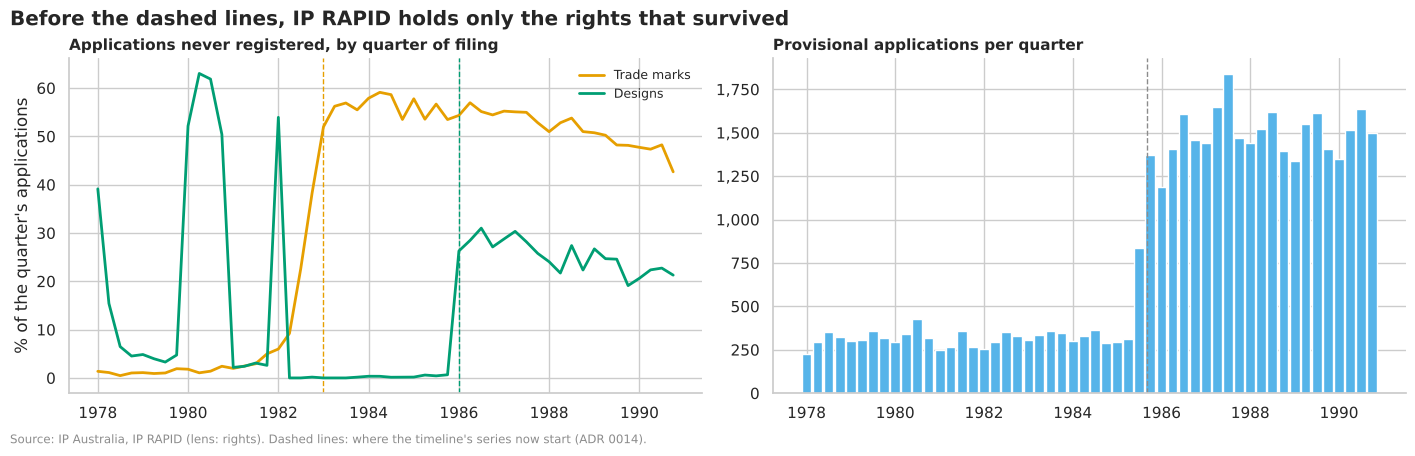

In [58]:
# Survivors: before its records were computerised, IP RAPID holds only the rights still on the register then. The share
# of each quarter's applications never registered (trade marks, designs) and provisional applications per quarter
START = build.TIMELINE_START_OVERRIDE
early = sql("""
    SELECT CAST(date_trunc('quarter', application_date) AS DATE) AS quarter, coalesce(patent_type, ip_right_type) AS t,
           count(*) AS n, 100 * avg((registered_date IS NULL)::int) AS never_registered
    FROM {lens/rights}
    WHERE application_date BETWEEN DATE '1978-01-01' AND DATE '1990-12-31'
      AND (ip_right_type IN ('trade_mark', 'design') OR patent_type = 'provisional')
    GROUP BY ALL
""").pivot(index="quarter", columns="t", values=["n", "never_registered"])
early.index = pd.to_datetime(early.index)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2))
for t, series in (("trade_mark", "trade_marks_au"), ("design", "designs_au")):
    a.plot(early.index, early["never_registered", t], color=TYPE_COLOURS[t], lw=2, label=TYPES[t])
    a.axvline(pd.Timestamp(START[series]), color=TYPE_COLOURS[t], ls="--", lw=1)
a.set_ylabel("% of the quarter's applications")
a.set_title("Applications never registered, by quarter of filing", fontsize=11)
a.legend(frameon=False, fontsize=9)
b.bar(early.index, early["n", "provisional"], width=80, color=TYPE_COLOURS["provisional"])
b.axvline(pd.Timestamp(START["patents_provisional"]), color=style.MUTED, ls="--", lw=1)
b.set_title("Provisional applications per quarter", fontsize=11)
style.thousands(b)
fig.suptitle("Before the dashed lines, IP RAPID holds only the rights that survived", x=0, ha="left", fontweight="bold")
style.source(
    fig, "IP Australia, IP RAPID (lens: rights). Dashed lines: where the timeline's series now start (ADR 0014)."
)
granted = (
    sql("""
    SELECT year(application_date) AS filed, 100 * avg((registered_date IS NOT NULL)::int) AS pct
    FROM {lens/rights} WHERE patent_type = 'standard' AND year(application_date) BETWEEN 1976 AND 1981 GROUP BY 1
""")
    .set_index("filed")
    .pct.sort_index()
)
print("Standard patents with a grant date, % by year filed:", granted.round(1).to_dict())
quarters = pd.to_datetime(
    ["1981-01-01", "1982-07-01", "1983-01-01", "1985-07-01", "1985-10-01", "1986-01-01", "1988-10-01"]
)
early.loc[quarters].round(1)

,why,rule's start,new start,months set aside,% of them empty,records set aside,% of the series
series,,,,,,,
trade_marks_au,survivors,1906-04,1983-01,921,2.3,44207,3.2
trade_marks_overseas,survivors,1906-04,1983-01,921,0.9,75506,8.4
trade_marks_origin_unknown,survivors,1914-10,1983-01,819,47.6,7238,19.2
designs_au,survivors,1973-03,1986-01,154,1.9,9033,8.8
designs_overseas,survivors,1973-03,1986-01,154,1.9,5426,4.3
designs_origin_unknown,survivors,1972-03,1986-01,166,16.9,2903,9.9
patents_provisional,survivors,1975-02,1985-09,127,6.3,9909,3.8
patents_granted,partial,1975-01,1985-01,120,8.3,16557,2.5
designs_registered,partial,1973-06,1988-01,175,2.9,17445,7.6


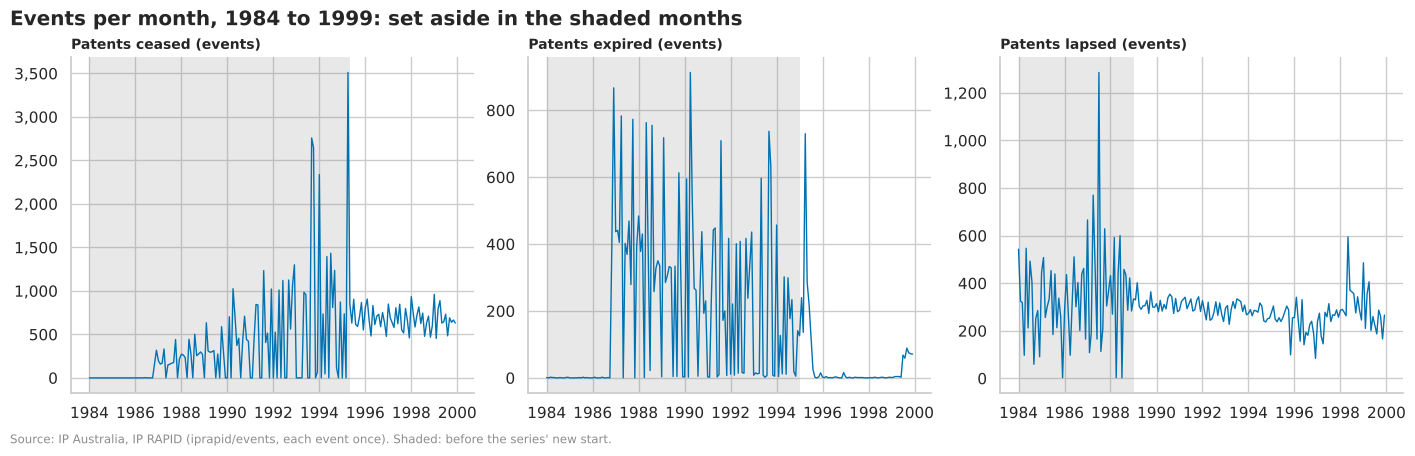

In [59]:
# Batches: the events of the series whose start was set by hand, straight from IP RAPID, with the number of days a
# month on which they are dated
made = {c: cond for c, cond in build.TIMELINE_EVENTS if c in START and c != "trade_marks_registered"}
counts = ", ".join(f"count(*) FILTER ({cond}) AS {c}" for c, cond in made.items())
days = ", ".join(f"count(DISTINCT event_date) FILTER ({cond}) AS days_{c}" for c, cond in made.items())
raw = sql(f"""
    WITH e AS (SELECT DISTINCT ip_right_type, application_number, event_type, event_category,
                      {build.EVENT_DATE} AS event_date
               FROM {{iprapid/events}} WHERE {" OR ".join(f"({cond})" for cond in made.values())})
    SELECT CAST(date_trunc('month', event_date) AS DATE) AS month, {counts}, {days}
    FROM e WHERE event_date BETWEEN DATE '1904-01-01' AND DATE '2026-09-30' GROUP BY 1 ORDER BY 1
""").set_index("month")
raw.index = pd.to_datetime(raw.index)
raw = raw.reindex(pd.date_range("1904-01-01", "2026-09-01", freq="MS"), fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
for ax, c in zip(axes, ["patents_ceased", "patents_expired", "patents_lapsed"], strict=True):
    w = raw.loc["1984-01-01":"1999-12-01", c]
    ax.plot(w.index, w, color=style.MAIN, lw=1)
    ax.axvspan(w.index[0], pd.Timestamp(START[c]), color=style.MUTED, alpha=0.2, lw=0)
    ax.set_title(style.label("timeline", c), fontsize=10)
    style.thousands(ax)
fig.suptitle("Events per month, 1984 to 1999: set aside in the shaded months", x=0, ha="left", fontweight="bold")
style.source(fig, "IP Australia, IP RAPID (iprapid/events, each event once). Shaded: before the series' new start.")

# Every hand-set start: why, where the 9-in-12 rule (ADR 0010) started the series, and what the months between held
apps = {c: cond for c, cond in build.TIMELINE_APPLICATIONS if c in START}
WHY = {
    **dict.fromkeys(list(apps), "survivors"),
    **dict.fromkeys(["patents_granted", "designs_registered", "trade_marks_lapsed", "trade_marks_ceased"], "partial"),
    "designs_ceased": "partial, then a backlog",
}
held = sql(f"""
    SELECT CAST(date_trunc('month', application_date) AS DATE) AS month,
           {", ".join(f"count(*) FILTER ({cond}) AS {c}" for c, cond in apps.items())}
    FROM {{lens/rights}} WHERE application_date BETWEEN DATE '1904-01-01' AND DATE '2026-09-30' GROUP BY 1
""").set_index("month")
held.index = pd.to_datetime(held.index)
held = held.reindex(raw.index, fill_value=0)
held = held.join(raw[list(made)]).fillna(0)
rows = []
for c, start in START.items():
    if c == "trade_marks_registered":
        continue
    y = held[c]
    nine = (y > 0).astype(int)[::-1].rolling(12).sum()[::-1] >= 9  # 9 of the 12 months from here have a record
    rule = nine[nine].index.min()
    aside = y.loc[rule : pd.Timestamp(start) - pd.DateOffset(months=1)]
    rows.append(
        {
            "series": c,
            "why": WHY.get(c, "batches"),
            "rule's start": f"{rule:%Y-%m}",
            "new start": start[:7],
            "months set aside": len(aside),
            "% of them empty": 100 * (aside == 0).mean() if len(aside) else None,
            "records set aside": int(aside.sum()),
            "% of the series": 100 * aside.sum() / y.loc[rule:].sum(),
        }
    )
pd.DataFrame(rows).set_index("series").round(1)

,count,% zero,median,mean,min,max,variation (std / mean),skew,outliers (1.5 IQR)
patents_standard_au,120,0,219.5,220.5,137,578,0.2,4.66,2
patents_standard_overseas,120,0,"2,310","2,321","1,905","2,905",0.08,0.41,1
patents_standard_origin_unknown,120,95.83,0,0.06,0,3,5.58,7.14,5
patents_provisional,120,0,409.5,437.2,172,"1,274",0.38,2.78,12
patents_second_tier,120,0,119.5,170.7,1,"2,789",1.82,5.54,12
trade_marks_au,120,0,"4,056","4,089","2,617","5,771",0.15,0.19,0
trade_marks_overseas,120,0,"2,802","2,841","1,729","3,947",0.15,0.03,0
trade_marks_origin_unknown,120,45.83,1,1.32,0,28,2.27,6.68,8
designs_au,120,0,197.5,199.4,99,298,0.2,-0,0
designs_overseas,120,0,447.5,464.1,288,697,0.21,0.39,0


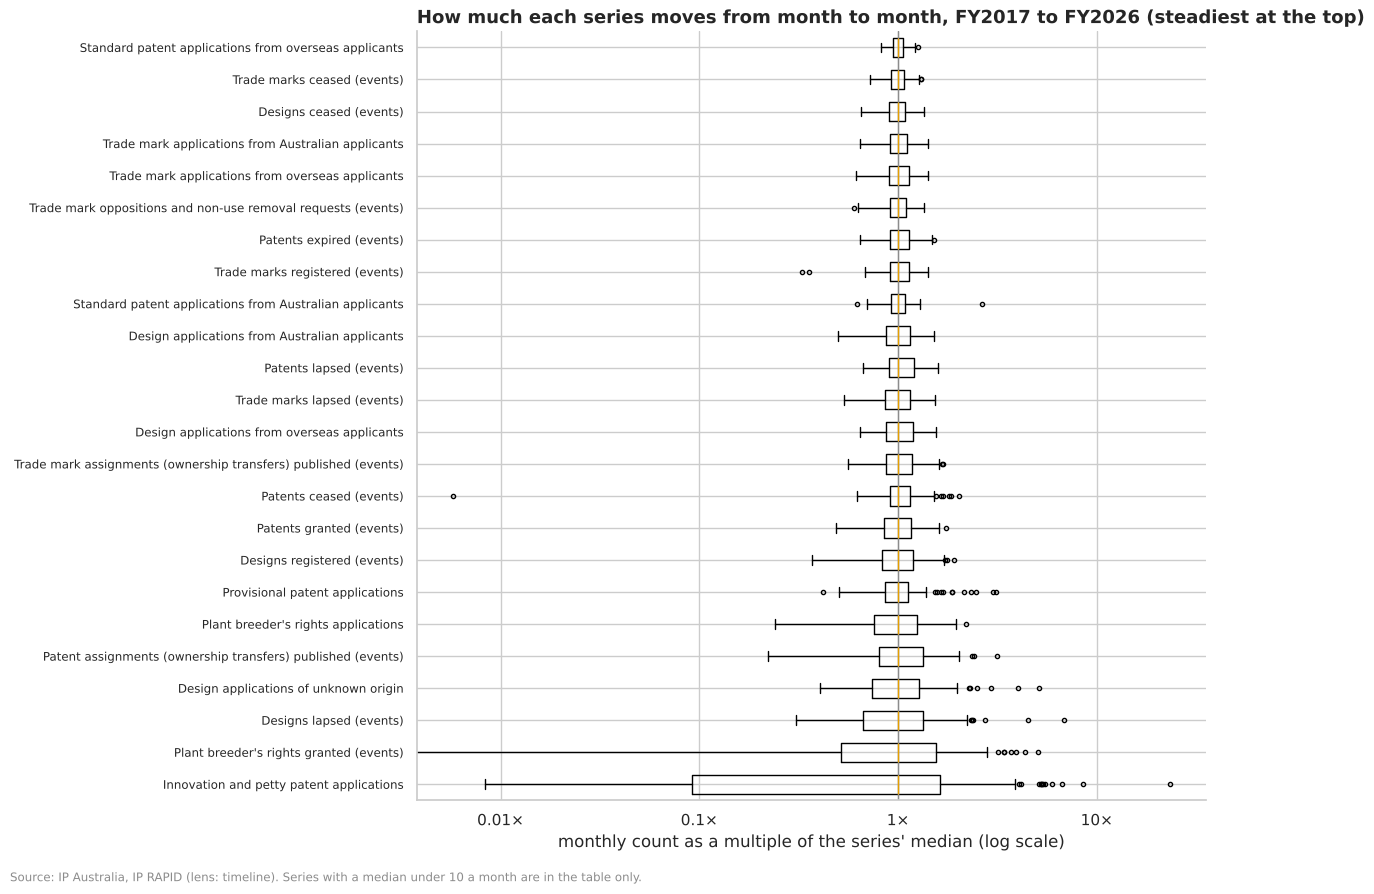

In [60]:
# The shape of every monthly series over the last ten complete financial years (July 2016 to June 2026)
series = [c for c in timeline.columns if style.kind("timeline", c) == "count" and c != "days_in_month"]
ten = timeline[timeline.month.between("2016-07-01", "2026-06-01")]
profile = pd.DataFrame({c: uni.describe(ten[c]) for c in series}).T
profile["variation (std / mean)"] = profile["std"] / profile["mean"]
cols = ["count", "% zero", "median", "mean", "min", "max", "variation (std / mean)", "skew", "outliers (1.5 IQR)"]

# Each month as a multiple of its series' median, for the series with a median of 10 or more a month
big = [c for c in series if profile.loc[c, "median"] >= 10]
relative = ten[big].astype(float) / profile.loc[big, "median"]
order = profile.loc[big, "variation (std / mean)"].sort_values(ascending=False).index  # drawn bottom up
fig, ax = plt.subplots(figsize=(12, 8.5))
ax.boxplot([relative[c].dropna() for c in order], orientation="horizontal", widths=0.6, flierprops={"markersize": 3})
ax.set_yticks(range(1, len(order) + 1), [style.label("timeline", c, unit=False) for c in order], fontsize=8.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.axvline(1, color=style.MUTED, lw=1)
ax.set_xlabel("monthly count as a multiple of the series' median (log scale)")
ax.set_title("How much each series moves from month to month, FY2017 to FY2026 (steadiest at the top)")
style.source(
    fig, "IP Australia, IP RAPID (lens: timeline). Series with a median under 10 a month are in the table only."
)
profile[cols].round(2)

#### Observations from the overview
**U22 (descriptive). One row per month, with each series where it can be read.**
- The lens holds 1,473 months (January 1904 to September 2026) in 35 columns: five calendar columns, 28 monthly
  series, the CPI and the policy changes. The calendar columns are complete; months have 28 to 31 days.
- After the repairs, the series begin between January 1904 (standard patents of unknown origin) and December 2003
  (patent oppositions), as the table above shows. None has a gap inside its span. The last months are empty only
  where the register is still recording: six months for trade mark and design cessations, three for designs by
  origin.
- The busiest month of standard patent applications from Australian and overseas applicants alike is April 2013
  (1,018 and 5,407), when Raising the Bar took effect; of second-tier applications, August 2021 (2,789), when
  innovation patents closed; of provisional applications, March 2026 (1,274).

**U23 (descriptive). Fifteen series started too early, and one policy change was missing (ADR 0014).**
- **Survivors.** By quarter of filing, 2.0% of trade marks filed in early 1981 were never registered, 22.6% in the
  third quarter of 1982 and 52.0% from the first quarter of 1983 (51.0% at the end of 1988). Of designs, 0.4% and 0.7%
  in the second half of 1985, then 26.3% in the first quarter of 1986. Provisional applications run at 251 to 355 a
  quarter in the quarters shown before mid-1985, and 1,372 in the last quarter of 1985. A register that keeps only what survived records almost no
  failures, so the earlier months count survivors, not filings: 44,207 trade marks from Australian applicants and
  75,506 from overseas ones over the 921 months from April 1906 (3.2% and 8.4% of each series).
- **Batches.** Patent cessations were dated in batches to April 1995: 29.8% of the 104 months from September 1986 hold
  none, and others hold several months' worth (46,671 cessations, 11% of the series). Expiries to December 1994 hold
  29.4% of their series. Both are dated weekly or daily since (the chart).
- **Partial records.** IP RAPID records grants only for patents filed from 1979: 1.0% to 1.9% of standard patents
  filed in 1976 to 1978 have a grant date, against 68.5% of those filed in 1979. So the 16,557 grants before 1985 are
  some of the grants made (2.5% of the series).
- **What remains real.** Patent expiries all but stop from July 1995 and resume in July 1999 (the chart; measured in
  5.4). Australia raised the standard patent term from 16 to 20 years on 1 July 1995, for every patent still
  in force, so patents filed from July 1979 expired four years later than they would have. The policy register now
  holds this change, checked against the Act (the Patents (World Trade Organization Amendments) Act 1994), and its
  note on the Patents Act 1990, which said the 1990 Act brought in 20-year patents, is corrected: the 1990 Act's term
  was 16 years.
- The rights lens keeps every right; only counts by year of filing are affected. Section 1's note is corrected (U5).

**U24 (descriptive). The shape of the monthly counts, FY2017 to FY2026.**
- **Steadiest:** standard patent applications from overseas (median 2,310 a month; a standard deviation 0.08 of the
  mean), trade mark cessations (0.12), design cessations (0.14) and trade mark applications (0.15 from Australian and
  overseas applicants alike).
- **Most variable:** second-tier patents (1.82, from the rush to file before their closure and the near-silence
  after), plant breeder's rights granted (0.79), extensions of term (0.72) and design lapses (0.69).
- **Outliers** (the box-plot rule): 12 months each for provisional applications (the rise of 2025 and 2026) and
  second-tier patents (2021), 7 for patent cessations (a pause in February 2020, 5.5) and 7 for plant breeder's
  rights granted.
- **Small series:** patent oppositions (median 5 a month; 2.5% of months none), extensions of term (5; 7.5% none) and
  plant breeder's rights granted (13.5; 0.83% none). The "origin unknown" series are mostly zero (95.83% of months for
  standard patents, 45.83% for trade marks), as they should be once origins are recorded.
- **Decision:** in Stage 2, series with a median under 10 a month are compared by quarter or year, not by month.

### 5.1 Long-run trends in applications, by type and origin

**Informs:** Q1, Q2. **Helpers:** 12-month rolling totals, `sql`.

- [x] Applications per 12 months for each type, from Australian, overseas and origin-unknown applicants, from each
  series' first complete month.
- [x] Average yearly growth by decade, and the years that fell.
- [x] Australian applicants' share of rights with a known origin: by financial year in 1.2 (U7), from the same
  records; not repeated here.

Applications per calendar year
       standard patents  of which overseas  of which Australian  provisional  second-tier  trade marks  designs  plant breeder's rights
month                                                                                                                                  
1930               2926               <NA>                 <NA>         <NA>         <NA>         <NA>     <NA>                    <NA>
1950               3748               <NA>                 <NA>         <NA>         <NA>         <NA>     <NA>                    <NA>
1970              13160                 58                 <NA>         <NA>         <NA>         <NA>     <NA>                    <NA>
1990              14990              13228                 1717         6003          276        22028     4190                     134
2000              21995              20028                 1924         7434          663        42907     4255                     350
2008             

,standard patents,of which overseas,of which Australian,provisional,second-tier,trade marks,designs,plant breeder's rights
1990 to 2000,3.9,4.2,1.1,2.2,9.2,6.9,0.2,10.1
2000 to 2010,1.3,1.2,2.3,-2.6,8.4,3.3,3.2,-0.7
2010 to 2019,2,2.1,1,-1.5,2.6,2.7,2.7,-1.5
2019 to 2025,0.4,0.3,1.1,5.6,-45,4.3,5.5,-1.2


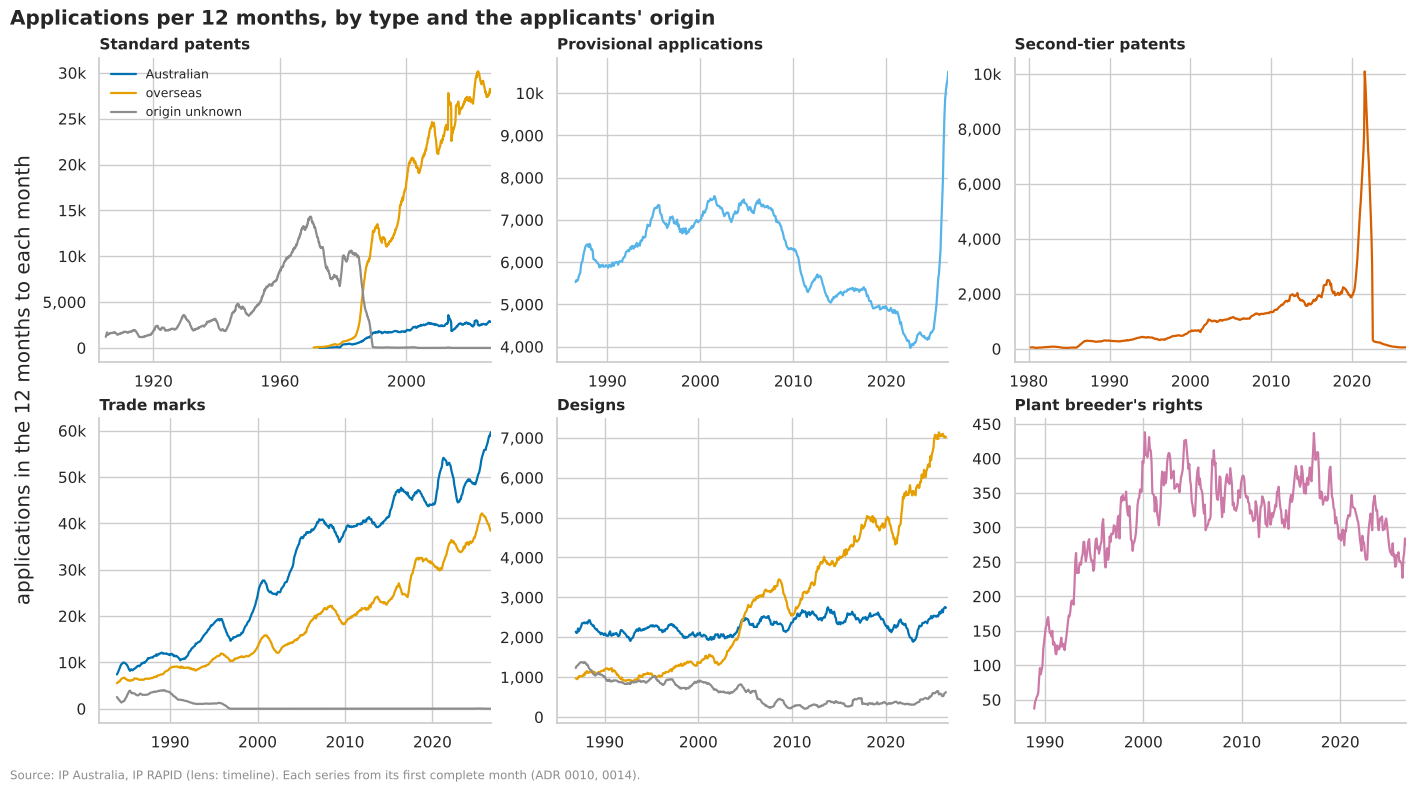

In [61]:
# Applications per 12 months (a rolling total, which removes the seasons), by type and origin, from each series' start
APPS = {
    "standard": ["patents_standard_au", "patents_standard_overseas", "patents_standard_origin_unknown"],
    "provisional": ["patents_provisional"],
    "second_tier": ["patents_second_tier"],
    "trade_mark": ["trade_marks_au", "trade_marks_overseas", "trade_marks_origin_unknown"],
    "design": ["designs_au", "designs_overseas", "designs_origin_unknown"],
    "pbr": ["pbr_applications"],
}
ORIGIN = {"_au": "Australian", "_overseas": "overseas", "_origin_unknown": "origin unknown"}
by_month = timeline.set_index("month")
rolling = by_month[sum(APPS.values(), [])].astype(float).rolling(12).sum()
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (t, columns) in zip(axes.flat, APPS.items(), strict=True):
    for c in columns:
        origin = next((o for suffix, o in ORIGIN.items() if c.endswith(suffix)), None)
        colour = ORIGIN_COLOURS[origin] if origin else TYPE_COLOURS[t]
        ax.plot(rolling.index, rolling[c], color=colour, lw=1.6, label=origin)
    ax.set_xlim(rolling[columns].first_valid_index() - pd.DateOffset(years=2), rolling.index[-1])
    ax.set_title(TYPES[t], fontsize=11)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=7))
    style.thousands(ax)
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.supylabel("applications in the 12 months to each month")
fig.suptitle("Applications per 12 months, by type and the applicants' origin", x=0, ha="left", fontweight="bold")
style.source(
    fig, "IP Australia, IP RAPID (lens: timeline). Each series from its first complete month (ADR 0010, 0014)."
)

# Calendar-year totals (complete years only), and the average yearly growth between them
years = by_month.groupby(by_month.index.year)[sum(APPS.values(), [])].sum(min_count=12)
totals = pd.DataFrame(
    {
        "standard patents": years[APPS["standard"]].sum(axis=1, min_count=1),
        "of which overseas": years["patents_standard_overseas"],
        "of which Australian": years["patents_standard_au"],
        "provisional": years["patents_provisional"],
        "second-tier": years["patents_second_tier"],
        "trade marks": years[APPS["trade_mark"]].sum(axis=1, min_count=3),
        "designs": years[APPS["design"]].sum(axis=1, min_count=3),
        "plant breeder's rights": years["pbr_applications"],
    }
)
growth = pd.DataFrame(
    {
        f"{a} to {b}": 100 * ((totals.loc[b] / totals.loc[a]) ** (1 / (b - a)) - 1)
        for a, b in [(1990, 2000), (2000, 2010), (2010, 2019), (2019, 2025)]
    }
).T
print("Applications per calendar year")
print(totals.loc[[1930, 1950, 1970, 1990, 2000, 2008, 2009, 2010, 2019, 2020, 2021, 2022, 2024, 2025]].to_string())
print("\nAverage growth per year, % (compound)")
growth.round(1)

#### Observations
**U25 (descriptive). Growth has slowed for standard patents and quickened for trade marks and designs.**
- **Standard patents:** 2,926 applications in 1930, 3,748 in 1950, 13,160 in 1970 and 14,990 in 1990, then 21,995
  (2000), 32,399 (2021, the highest) and 30,448 (2025). Average growth per year: 3.9% in the 1990s, 1.3% from 2000 to
  2010, 2.0% from 2010 to 2019 and 0.4% from 2019 to 2025. Overseas applicants set the pace (4.2%, 1.2%, 2.1% and
  0.3%); Australian applications grew 1.1%, 2.3%, 1.0% and 1.1% a year.
- **Trade marks:** 22,028 (1990) to 97,343 (2025), growing 6.9%, 3.3%, 2.7% and 4.3% a year. In the chart, applications
  from Australians stay above those from overseas throughout.
- **Designs:** 4,190 (1990) to 10,303 (2025): 0.2%, 3.2%, 2.7% and 5.5% a year. In the chart, the growth is almost all
  from overseas applicants; Australians' applications stay near 2,000 to 2,700 a year.
- **Provisional applications:** 7,434 in 2000, falling 2.6% and 1.5% a year to 4,036 in 2022, then 6,874 in 2025
  (U8 has the rise of FY2026).
- **Second-tier patents:** 276 (1990), 7,833 (2021) and 52 (2025): the closure (5.4).
- **Plant breeder's rights:** 134 (1990) and 350 (2000), then 264 to 374 a year (10.1% a year in the 1990s, about
  −1% since).
- **Falls:** in 2009, standard patents fell 10.9% (26,598 to 23,707), designs 15.2% (6,060 to 5,136) and trade marks
  4.5% (59,271 to 56,612), the year after the global financial crisis began; in 2022, trade marks fell 11.2% from the
  2021 peak (88,751 to 78,844).

### 5.2 Seasonal patterns

**Informs:** Q4. **Helpers:** `uni.seasonal_profile` (each month against the centred 12-month average around it).

- [x] The typical month of the year for every series of 50 or more a month, 2010 to 2019.
- [x] Whether the January lull has changed over the decades.

,1990s,2000s,2010s,2020 to 2025
patents_standard_au,80,78,75,73
patents_standard_overseas,87,94,95,90
patents_provisional,73,72,70,63
trade_marks_au,77,79,75,77
trade_marks_overseas,90,81,90,86
designs_au,71,69,66,67
designs_overseas,95,88,95,88
patents_granted,116,131,115,111
trade_marks_registered,113,124,133,124


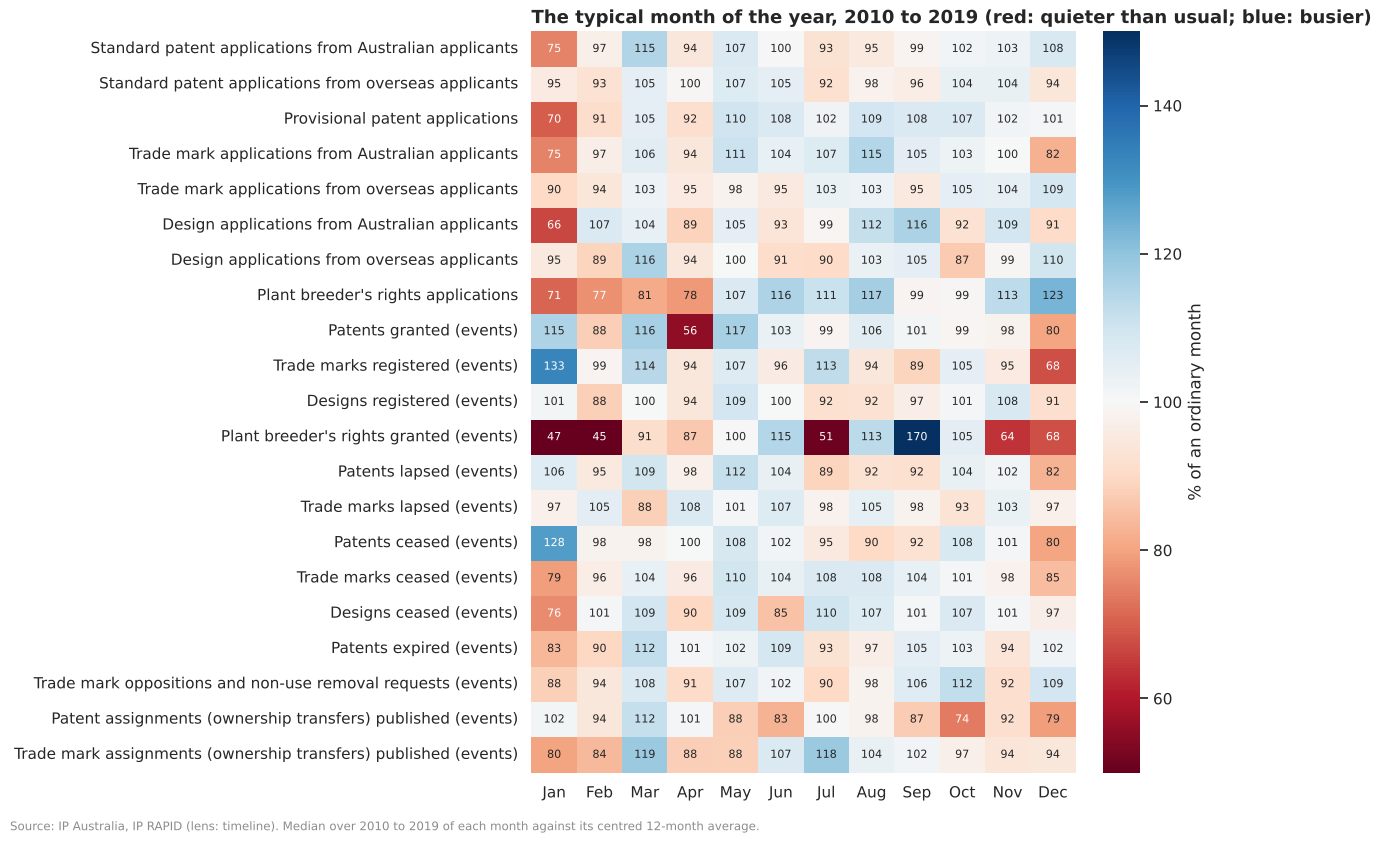

In [62]:
# The typical month of the year, 2010 to 2019 (a decade before COVID-19 and after the global financial crisis): each
# month as a % of the 12 months around it, median over the decade (100 = an ordinary month)
SEASONAL = [
    "patents_standard_au",
    "patents_standard_overseas",
    "patents_provisional",
    "trade_marks_au",
    "trade_marks_overseas",
    "designs_au",
    "designs_overseas",
    "pbr_applications",
    "patents_granted",
    "trade_marks_registered",
    "designs_registered",
    "pbr_granted",
    "patents_lapsed",
    "trade_marks_lapsed",
    "patents_ceased",
    "trade_marks_ceased",
    "designs_ceased",
    "patents_expired",
    "trade_mark_oppositions",
    "patent_assignments",
    "trade_mark_assignments",
]
season = uni.seasonal_profile(timeline, SEASONAL, start="2010-01-01", end="2019-12-01")
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    season.set_axis([style.label("timeline", c, unit=False) for c in season.index]),
    cmap="RdBu",
    center=100,
    vmin=50,
    vmax=150,
    annot=True,
    fmt=".0f",
    annot_kws={"fontsize": 8},
    cbar_kws={"label": "% of an ordinary month"},
    ax=ax,
)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("")
ax.set_title("The typical month of the year, 2010 to 2019 (red: quieter than usual; blue: busier)")
style.source(
    fig,
    "IP Australia, IP RAPID (lens: timeline). Median over 2010 to 2019 of each month against its "
    "centred 12-month average.",
)

# Has the January lull changed? January as a % of an ordinary month, by decade
decades = {
    "1990s": ("1990", "1999"),
    "2000s": ("2000", "2009"),
    "2010s": ("2010", "2019"),
    "2020 to 2025": ("2020", "2025"),
}
jan = pd.DataFrame(
    {
        d: uni.seasonal_profile(
            timeline, SEASONAL[:7] + ["patents_granted", "trade_marks_registered"], start=f"{a}-01-01", end=f"{b}-12-01"
        )[1]
        for d, (a, b) in decades.items()
    }
)
jan.round(0)

#### Observations
**U26 (descriptive). Australians file less in January; the office has rhythms of its own.**
- **January is the quiet month for Australian filers** (2010 to 2019): standard patents 75% of an ordinary month,
  provisional applications 70%, trade marks 75%, designs 66% and plant breeder's rights 71%. Overseas applicants barely
  pause: 95% for standard patents, 90% for trade marks and 95% for designs.
- **The lull is deepening for patents:** January's share for Australian standard patents was 80 (1990s), 78, 75 and
  73 (2020 to 2025); for provisional applications 73, 72, 70 and 63. For Australian trade marks it is steady (77, 79,
  75, 77).
- Australian trade marks also dip in December (82) and peak in August (115).
- **The office's output has its own calendar:** trade mark registrations run at 133% of an ordinary month in January
  and 68% in December; patent grants at 56% in April and 80% in December. These follow the office's working days and
  processing, not demand.
- **Plant breeder's rights granted** cluster in some months (September 170, March 91 against January 47, February 45
  and July 51): quarters, not months, are the unit (U24).
- **Decision:** in Stage 2, months are compared with the same month a year earlier, or as 12-month totals, never with
  the month before.

### 5.3 What happens to rights, over time

**Informs:** Q1. **Helpers:** 12-month rolling totals.

- [x] Grants and registrations, lapses, cessations, expiries, oppositions, ownership transfers and extensions of term
  per 12 months, and the year each peaked.
- [x] What "ceased" means against "lapsed": settled in 1.3 (U9). A lapse ends an application; a cessation ends a
  registered right. The timeline counts each as an event, at its date.

          patents_granted trade_marks_registered designs_registered patents_lapsed trade_marks_lapsed designs_lapsed patents_ceased trade_marks_ceased designs_ceased patents_expired patent_assignments trade_mark_assignments trade_mark_oppositions pbr_granted patent_oppositions patent_extensions_of_term
peak year            2016                   2021               2025           2010               2017           1995           2021               2025           2018            2024               2015                   2019                   2025        2005               2015                      2000
peak                25687                  70634               9809          13945              19767            936          18919              35484           6982            4048               6015                  18370                   2309         362                154                       114


month,1996,2000,2002,2005,2010,2013,2016,2019,2021,2023,2025
patents_granted,8987,13916,14499,11936,15883,18852,25687,18804,25225,15739,19612
trade_marks_registered,19578,18310,29902,36349,40047,46967,49691,58646,70634,62870,70616
designs_registered,3460,3108,3842,5843,5326,7065,6666,7115,8048,8016,9809
patents_lapsed,2584,3379,4263,5140,13945,10064,13938,9483,9449,8955,12294
trade_marks_lapsed,12738,8026,16718,14471,14023,19049,18740,13685,17177,16374,17521
designs_lapsed,874,713,798,825,264,260,656,478,503,441,722
patents_ceased,8202,8245,9945,11830,13820,11333,13384,13628,18919,16528,15244
trade_marks_ceased,7240,7847,3773,11375,18705,17638,28924,29802,28283,28319,35484
designs_ceased,2821,2880,2778,2972,5014,4203,6505,6561,6218,6612,6477
patents_expired,30,861,1023,1177,1739,2040,2729,3335,3479,3732,4019


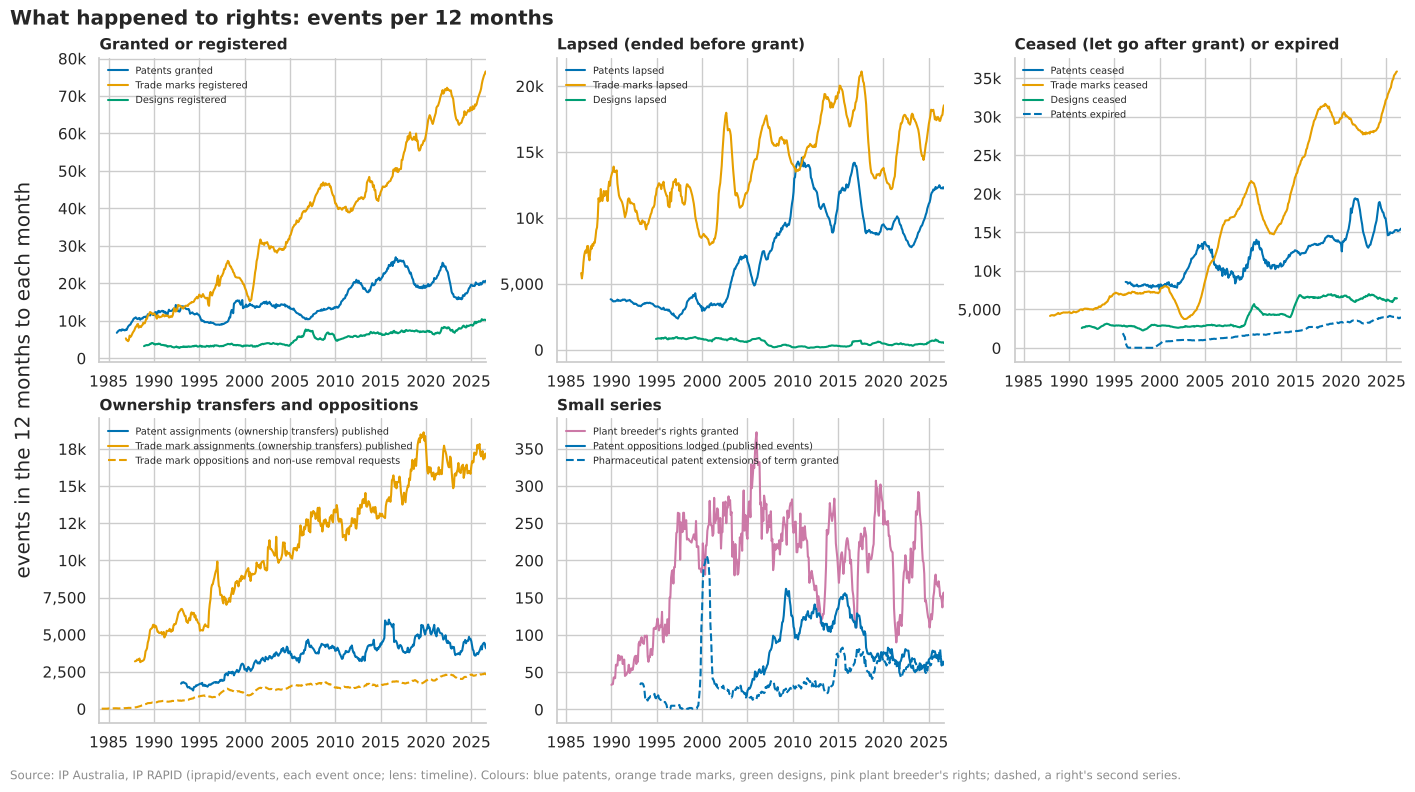

In [63]:
# What happened to rights: events per 12 months, from each series' start
OUTCOMES = {
    "Granted or registered": ["patents_granted", "trade_marks_registered", "designs_registered"],
    "Lapsed (ended before grant)": ["patents_lapsed", "trade_marks_lapsed", "designs_lapsed"],
    "Ceased (let go after grant) or expired": [
        "patents_ceased",
        "trade_marks_ceased",
        "designs_ceased",
        "patents_expired",
    ],
    "Ownership transfers and oppositions": ["patent_assignments", "trade_mark_assignments", "trade_mark_oppositions"],
    "Small series": ["pbr_granted", "patent_oppositions", "patent_extensions_of_term"],
}
ev = by_month[sum(OUTCOMES.values(), [])].astype(float).rolling(12).sum()
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (name, columns) in zip(axes.flat, OUTCOMES.items(), strict=False):
    drawn = []
    for c in columns:
        right = next(r for r in ("patent", "trade_mark", "design", "pbr") if c.startswith(r))
        ax.plot(
            ev.index,
            ev[c],
            color=style.RIGHTS[right],
            lw=1.5,
            ls="--" if right in drawn else "-",
            label=style.label("timeline", c, unit=False).replace(" (events)", ""),
        )
        drawn.append(right)
    ax.set_xlim(pd.Timestamp("1984-01-01"), ev.index[-1])
    ax.set_title(name, fontsize=11)
    ax.legend(frameon=False, fontsize=7, loc="upper left")
    style.thousands(ax)
axes.flat[-1].set_visible(False)
fig.supylabel("events in the 12 months to each month")
fig.suptitle("What happened to rights: events per 12 months", x=0, ha="left", fontweight="bold")
style.source(
    fig,
    "IP Australia, IP RAPID (iprapid/events, each event once; lens: timeline). Colours: blue patents, "
    "orange trade marks, green designs, pink plant breeder's rights; dashed, a right's second series.",
)

outcome_years = by_month.groupby(by_month.index.year)[sum(OUTCOMES.values(), [])].sum(min_count=12)
peaks = pd.DataFrame({"peak year": outcome_years.idxmax(), "peak": outcome_years.max()})
print(peaks.T.to_string())
outcome_years.loc[[1996, 2000, 2002, 2005, 2010, 2013, 2016, 2019, 2021, 2023, 2025]].T

#### Observations
**U27 (descriptive). Outcomes over time.**
- **Patent grants** peaked in 2016 (25,687), three years after the rush to file before Raising the Bar (5.4), and
  were 15,739 in 2023 and 19,612 in 2025.
- **Trade mark registrations** rose from 19,578 (1996) to 70,634 (2021, the peak) and 70,616 (2025).
- **Lapses** (applications that ended): patents peaked in 2010 (13,945) and were 12,294 in 2025; trade marks peaked
  in 2017 (19,767).
- **Cessations** (registered rights let go) rose for trade marks from 7,240 (1996) to 35,484 (2025, the peak), and for
  patents from 8,202 to 18,919 (2021, the peak) and 15,244 (2025). Design cessations were 6,218 to 6,612 in each year
  shown since 2016.
- **Expiries** of patents rose from 30 (1996) and 861 (2000) to 4,019 (2025), as patents filed under the 20-year term
  reach it (U23).
- **Ownership transfers:** trade mark assignments rose from 9,389 (1996) to 18,370 (2019, the peak); patent
  assignments from 1,802 to 6,015 (2015, the peak), and 3,910 in 2025.
- **Oppositions:** trade marks 824 (1996) to 2,309 (2025, the peak); patents 50 to 112 in the years shown since 2005,
  and 154 at their peak (2015).
- **Extensions of term** for pharmaceutical patents peaked at 114 in 2000, the first full year of the 1999 regime,
  and have run at 14 to 76 a year since.
- **A lead:** trade mark cessations fell from 7,847 (2000) to 3,773 (2002), while lapses rose from 8,026 to 16,718 and
  registrations from 18,310 to 29,902. The events attachment (B5) can show whether the Trade Marks Act 1995's new
  renewal terms, or the office's processing, moved them.

### 5.4 The 17 policy changes, one at a time

**Informs:** Q4, Q5. **Helpers:** `uni.around_events`, `uni.event_windows`.

- [x] For each change, the series it targets in the 24 months either side. Two are enactments (Raising the Bar,
  2012; the innovation patent's phase-out, 2020), for anticipation before the change took effect.
- [x] Which changes show a visible rush or step, and which none: descriptive only, comparing the 12 months either
  side; Stage 2 allows for trends and seasons.

month  average, 12 months before  month before  month of the change  \
change                              series                                                                                                   
pct-accession                       patents_standard_origin_unknown  1980-03                      840.5           848                  834   
                                    patents_standard_overseas        1980-03                      58.42            54                   64   
patents-act-1990                    patents_granted                  1991-04                      1,013           832                1,226   
                                    patents_second_tier              1991-04                      22.17            17                   33   
pbr-act-1994                        pbr_applications                 1994-11                      20.83            15                   14   
patent-term-20-years                patents_expired                  1995-07                      289.5           219                  123   
trade-marks-act-1995                trade_marks_registered           1996-01                      1,345         1,242                    0   
                                    trade_marks_au                   1996-01                      1,613         1,556                  791   
                                    trade_mark_assignments           1996-01                      461.1           335                  375   
pharma-extension-of-term            patent_extensions_of_term        1999-01                       0.08             0                    0   
innovation-patent-introduced        patents_second_tier              2001-05                      50.58            32                  120   
madrid-protocol                     trade_marks_overseas             2001-07                      1,228         1,062                1,026   
designs-act-2003                    designs_registered               2004-06                        309           327                  190   
                                    designs_overseas                 2004-06                      171.6           214                  271   
                                    designs_au                       2004-06                        185           181                  245   
raising-the-bar-enacted             patents_standard_overseas        2012-04                      1,976         2,073                2,029   
                                    patents_standard_au              2012-04                      204.9           291                  228   
tobacco-plain-packaging             trade_marks_au                   2012-12                      3,419         3,254                2,637   
                                    trade_marks_overseas             2012-12                      1,865         2,284                1,887   
raising-the-bar                     patents_standard_overseas        2013-04                      2,035         2,698                5,407   
                                    patents_standard_au              2013-04                      231.9           353                1,018   
                                    patents_granted                  2013-04                      1,543         1,911                1,061   
pc-response-parallel-importation    patent_extensions_of_term        2018-08                       3.75             0                    9   
pc-response-part-1                  trade_mark_oppositions           2019-02                      154.4           104                  130   
innovation-patent-phase-out-enacted patents_second_tier              2020-02                      161.2           179                  151   
innovation-patent-closed            patents_second_tier              2021-08                      647.6         1,021                2,789   
designs-grace-period                designs_au                       2022-03                   

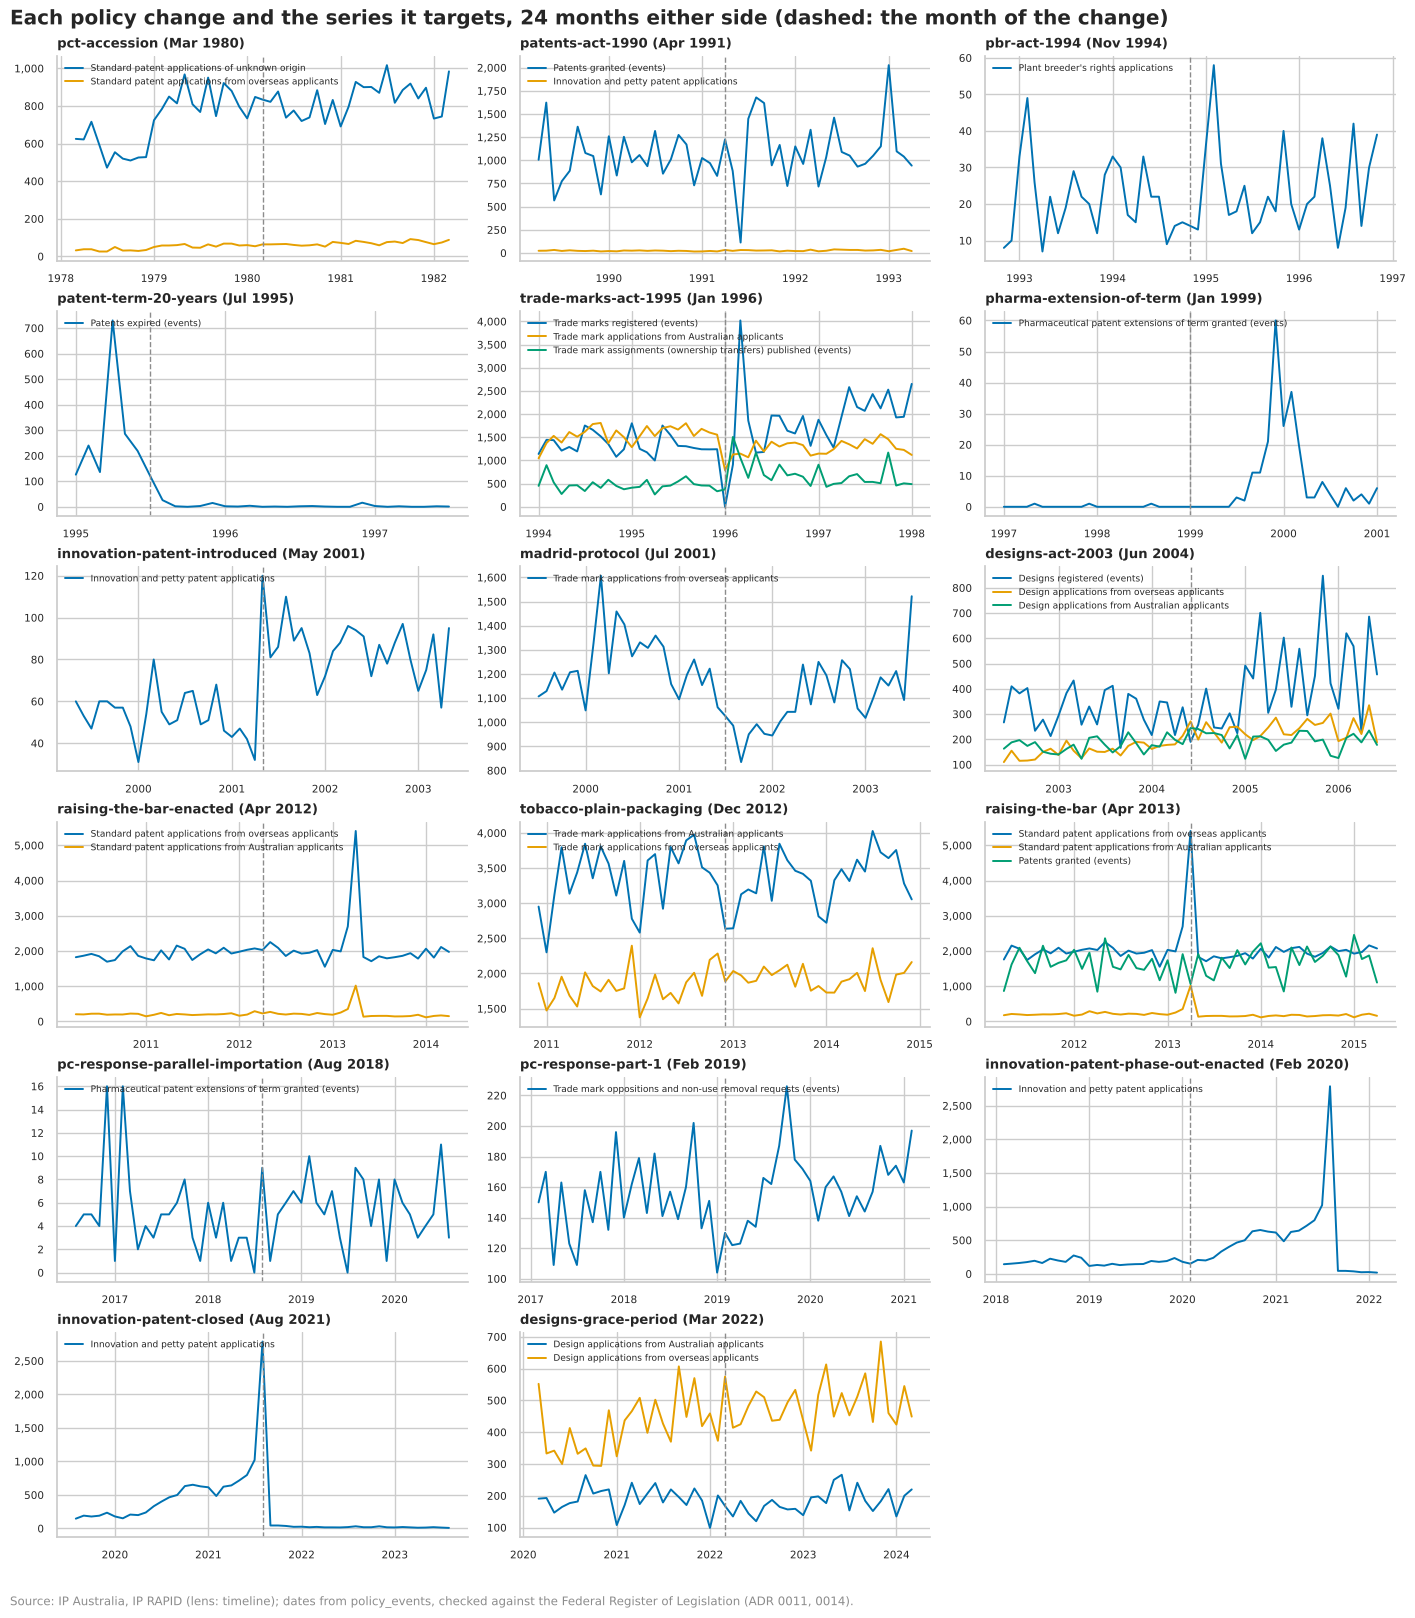

In [64]:
# The 17 policy changes, one at a time: the series each targets, in the 24 months either side of the month it took
# effect (or, for the two enactments, was enacted). The plain packaging of tobacco targets the use of marks, which no
# series here counts; trade mark applications are shown for completeness.
TARGETS = {
    "pct-accession": ["patents_standard_origin_unknown", "patents_standard_overseas"],
    "patents-act-1990": ["patents_granted", "patents_second_tier"],
    "pbr-act-1994": ["pbr_applications"],
    "patent-term-20-years": ["patents_expired"],
    "trade-marks-act-1995": ["trade_marks_registered", "trade_marks_au", "trade_mark_assignments"],
    "pharma-extension-of-term": ["patent_extensions_of_term"],
    "innovation-patent-introduced": ["patents_second_tier"],
    "madrid-protocol": ["trade_marks_overseas"],
    "designs-act-2003": ["designs_registered", "designs_overseas", "designs_au"],
    "raising-the-bar-enacted": ["patents_standard_overseas", "patents_standard_au"],
    "tobacco-plain-packaging": ["trade_marks_au", "trade_marks_overseas"],
    "raising-the-bar": ["patents_standard_overseas", "patents_standard_au", "patents_granted"],
    "pc-response-parallel-importation": ["patent_extensions_of_term"],
    "pc-response-part-1": ["trade_mark_oppositions"],
    "innovation-patent-phase-out-enacted": ["patents_second_tier"],
    "innovation-patent-closed": ["patents_second_tier"],
    "designs-grace-period": ["designs_au", "designs_overseas"],
}
fig = uni.around_events(timeline, TARGETS)
fig.suptitle(
    "Each policy change and the series it targets, 24 months either side (dashed: the month of the change)",
    x=0,
    ha="left",
    fontweight="bold",
)
style.source(
    fig,
    "IP Australia, IP RAPID (lens: timeline); dates from policy_events, checked against the Federal "
    "Register of Legislation (ADR 0011, 0014).",
)
windows = uni.event_windows(timeline, TARGETS)
windows.round(2)

#### Observations
**U28 (descriptive). Four kinds of response, and changes with none visible.** All compare the average month in the
12 months after a change's month with the 12 months before; trends and seasons are not allowed for.
- **Rushes to file before a change.** Raising the Bar (April 2013): 1,018 standard patent applications from
  Australians (4.39 times their average month in the year before) and 5,407 from overseas (2.66 times); in the year
  after, 34.0% and 7.6% fewer a month. The innovation patent's closure (August 2021): 2,789 applications (4.31 times),
  then 95.9% fewer (26.25 a month). Anticipation shows after each enactment: second-tier applications rose 176.4% in
  the year after the phase-out was enacted, and Australian standard patents 45.3% in the year after Raising the Bar
  was.
- **Steps.** Patent expiries fell 98.4% (289.5 to 4.67 a month) when the term rose to 20 years. Extensions of term
  went from 0.08 a month to 11.17 under the 1999 regime (60 in December 1999, the chart). Second-tier applications
  rose 71.5% (50.58 to 86.75 a month) when the innovation patent replaced the petty patent. Under the Designs Act
  2003, design applications from overseas rose 34.1% and registrations 24.5%; Australians' applications 6.5%.
- **Pauses at commencement.** The Trade Marks Act 1995: no trade mark registrations in January 1996, 4,021 in March
  (5.5), and Australians' applications at 0.49 times their usual month in January 1996; assignments published rose
  79.3%. The Patents Act 1990: 113 patent grants in June 1991, against about 1,025 a month (5.5).
- **None visible:** Australia joining the PCT (March 1980; entries through it come about 30 months after filing
  abroad); the plain packaging of tobacco (Australian trade marks −3.9%, overseas +5.2%, and no series counts tobacco
  marks); the Productivity Commission responses of 2018 and 2019 (trade mark oppositions +3.1%); the designs grace
  period (2022: Australians −16.5%, overseas +0.2%). Overseas trade marks fell 16.4% in the year after Australia
  joined the Madrid Protocol (July 2001), but the chart shows them falling from early 2000. Plant breeder's rights
  applications rose 22% after the 1994 Act, on 21 to 25 a month: too few to read.
- **Decision:** Stage 2's candidates are the two rushes, the four steps and the two pauses, each with placebo dates.
  The register still lacks fee changes (R3), the other lever IP Australia holds.

### 5.5 Artefacts

**Informs:** all. **Helpers:** a two-year rolling median, `sql` on `iprapid/events`.

- [x] After the repairs, every month at least three times, or under a third of, the median of the two years around
  it (in series of 50 or more a month), and what each is.
- [x] Decide which months to exclude.

In [65]:
# What stands out after the repairs: every month at least three times, or under a third of, the median of the two
# years around it, in series running at 50 or more a month
flagged = []
for c in series:
    y = by_month[c].dropna().astype(float)
    around = y.rolling(25, center=True, min_periods=13).median()
    ratio = y / around
    for m in y.index[(around >= 50) & ((ratio >= 3) | (ratio <= 1 / 3))]:
        flagged.append(
            {
                "series": c,
                "month": f"{m:%Y-%m}",
                "count": int(y[m]),
                "median around it": around[m],
                "× median": ratio[m],
                "policy change that month": by_month.policy_events.get(m),
            }
        )
# The July 2015 transfers: on which days, and where the patents assigned on the second of them are held now
july = sql("""
    WITH e AS (SELECT DISTINCT application_number, event_effective_date AS day FROM {iprapid/events}
               WHERE ip_right_type = 'patent' AND event_type LIKE 'published_assignments%'
                 AND event_effective_date BETWEEN DATE '2015-07-01' AND DATE '2015-07-31')
    SELECT e.day, r.applicant_country, count(*) AS n
    FROM e JOIN {lens/rights} r ON r.ip_right_type = 'patent' AND r.application_number = e.application_number
    GROUP BY ALL
""")
print(
    "Patent assignments published in July 2015, by day:",
    july.groupby("day").n.sum().rename(lambda d: f"{d:%d %b}").to_dict(),
)
print(
    "Held now, of those published on 2 July 2015 (top 3 countries):",
    july[july.day == pd.Timestamp("2015-07-02")].nlargest(3, "n").set_index("applicant_country").n.to_dict(),
)
print(f"\n{len(flagged)} months in {len({f['series'] for f in flagged})} series")
print(pd.DataFrame(flagged).set_index(["series", "month"]).round(2).to_string())

Patent assignments published in July 2015, by day: {'02 Jul': 395, '09 Jul': 646, '16 Jul': 325, '23 Jul': 163, '30 Jul': 73}
Held now, of those published on 2 July 2015 (top 3 countries): {'fi': 198, 'us': 170, 'jp': 7}

42 months in 12 series
                                         count  median around it  × median             policy change that month
series                          month                                                                          
patents_standard_au             2013-04   1018               190      5.36                      raising-the-bar
patents_standard_origin_unknown 1904-01      0                99         0                                  NaN
                                1904-02     25              99.5      0.25                                  NaN
                                1904-04     35             106.5      0.33                                  NaN
                                1904-05     23               113       0.2         

#### Observations
**U29 (descriptive). What still stands out, and what it is.** The table lists 42 months in 12 series.
- **Rushes, kept:** April 2013 (Australian standard patents, 5.36 times the median of the two years around it) and
  August 2021 (second-tier patents, 6 times). They are the policy responses of U28.
- **The register's first months:** standard patents of unknown origin run at 0 to 35 a month from January to May 1904
  and 394 in June 1904. Applications could be lodged from February 1904, before the Patents Act 1903 took effect on
  1 June 1904, so the months before June are a start-up, best left out of any comparison.
- **Pauses and their backlogs, kept:** patent grants in June 1991 (113, after the Patents Act 1990 commenced) and in
  October and November 1998 (248, then 3,373); trade mark registrations in January and March 1996 (0, then 4,021, the
  Trade Marks Act 1995); patent cessations in December 2006 (82) and February 2020 (7). February 2020 is also the
  month the innovation patent's phase-out was enacted, but the pause is in cessations of every kind of patent, so
  nothing in the data links the two.
- **Single low months in steady series:** trade mark registrations in January 1987 (151) and September 1991 (339),
  design registrations in January 1992 (77), trade mark lapses in October 1986, August 1987 and April 1996 (122, 94
  and 243), and patent assignments in February 1992, August 1998, January 2000 and March 2026 (42 to 75); patent
  assignments were also high in June 1994 (347).
- **A recurring low:** design lapses fall to 0 to 16 in April in six of the seven years from 1996 to 2002, and to 0 in
  October 2002, in a series of 59 to 76 a month. A lead, too small to matter elsewhere.
- **The origin field, not the count:** trade marks of unknown origin fall to 14 to 40 a month from November 1983 to
  May 1984 (and 87 in July 1985), against about 240. Australian and overseas trade marks are not flagged in those
  months, so what changed is the origin recorded.
- **An effect of the method:** patent expiries in February 1995 (240, 3.22 times) stand out only because the two years
  around them include the near-empty months after July 1995 (U23).
- **A transfer of many patents at once:** patent assignments in July 2015 (1,603, 4.2 times the median), published
  over the month's five weekly issues (395, 646, 325, 163 and 73); the patents assigned on 2 July 2015 are now held
  mostly in Finland (198) and the United States (170). One transfer of a portfolio fits this; the data do not name it.
- **Decision:** no further months are removed. Stage 2 pools each pause with its backlog (for example, patent
  cessations in February and March 2020) or uses 12-month totals; rushes are studied, not removed; the months before
  June 1904 are left out.

### 5.6 The Consumer Price Index, quarterly

**Informs:** all money series (the deflator). **Helpers:** the four-quarter change.

- [x] Coverage, base and gaps; the level, and the change over four quarters, by era.

312 quarters, Sep 1948 to Jun 2026; quarters missing in between: 0
CPI at selected quarters: {'Sep 1948': 2.59, 'Mar 1970': 6.69, 'Mar 1990': 39.01, 'Mar 2010': 66.12, 'Sep 2025': 99.73, 'Jun 2026': 102.31}
Quarters in which prices fell: 13
Monthly CPI, 2024-04 to 2026-08 (29 months); July to September 2025: {'2025-07': 99.63, '2025-08': 99.55, '2025-09': 100.0}


,quarters,median % a year,lowest,highest,highest in
1949 to 1969,82,3,-0.7,25.6,Dec 1951 quarter
1970 to 1989,80,8.7,2.6,17.5,Mar 1975 quarter
1990 to 2019,120,2.3,-0.3,8.6,Mar 1990 quarter
2020 to 2026,26,3.6,-0.3,7.9,Dec 2022 quarter


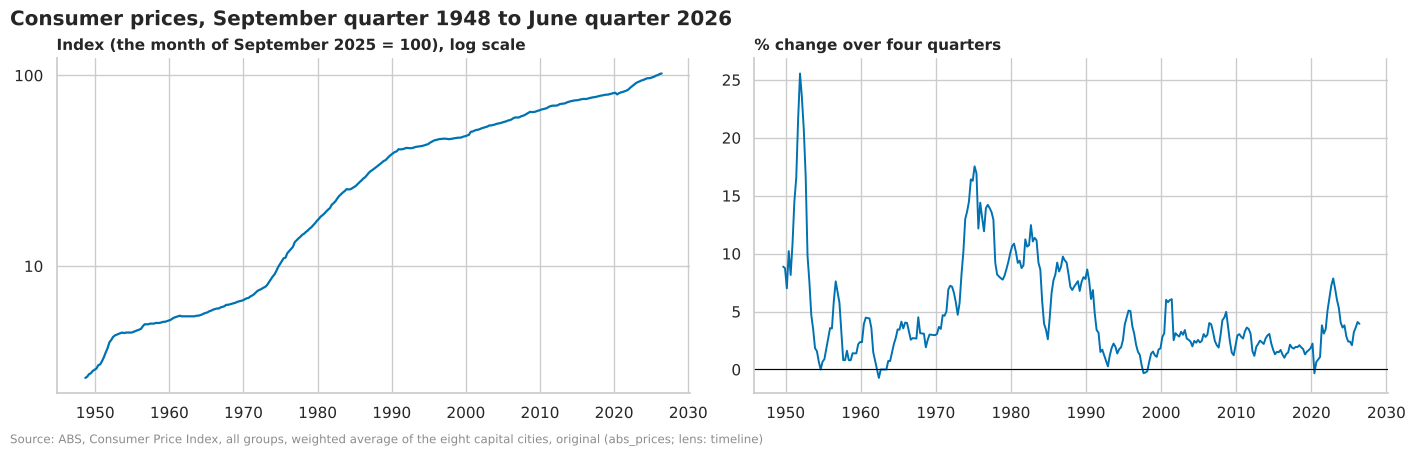

In [66]:
# The Consumer Price Index, quarterly (all groups, Australia): the level, and the change over four quarters
cpi = timeline.loc[timeline.cpi.notna(), ["month", "cpi"]].set_index("month").cpi
annual = 100 * (cpi / cpi.shift(4) - 1)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2))
a.plot(cpi.index, cpi, color=style.MAIN, lw=1.6)
a.set_yscale("log")
a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
a.set_title("Index (the month of September 2025 = 100), log scale", fontsize=11)
b.plot(annual.index, annual, color=style.MAIN, lw=1.4)
b.axhline(0, color="black", lw=0.8)
b.set_title("% change over four quarters", fontsize=11)
fig.suptitle("Consumer prices, September quarter 1948 to June quarter 2026", x=0, ha="left", fontweight="bold")
style.source(
    fig,
    "ABS, Consumer Price Index, all groups, weighted average of the eight capital cities, original "
    "(abs_prices; lens: timeline)",
)
print(
    f"{len(cpi)} quarters, {cpi.index.min():%b %Y} to {cpi.index.max():%b %Y}; quarters missing in between: "
    f"{len(pd.date_range(cpi.index.min(), cpi.index.max(), freq='QS-MAR').difference(cpi.index))}"
)
print(
    "CPI at selected quarters:",
    {
        f"{m:%b %Y}": float(cpi[m])
        for m in pd.to_datetime(["1948-09-01", "1970-03-01", "1990-03-01", "2010-03-01", "2025-09-01", "2026-06-01"])
    },
)
print("Quarters in which prices fell:", int((cpi.diff() < 0).sum()))
monthly = (
    sql("""
    SELECT time_period, value FROM {abs_prices/cpi}
    WHERE index = '10001' AND region = '50' AND measure = '1' AND adjustment_type = '10' AND frequency = 'M'
""")
    .set_index("time_period")
    .value.sort_index()
)
print(
    f"Monthly CPI, {monthly.index[0]} to {monthly.index[-1]} ({len(monthly)} months); July to September 2025:",
    monthly.loc["2025-07":"2025-09"].to_dict(),
)
eras = {
    "1949 to 1969": ("1949", "1969"),
    "1970 to 1989": ("1970", "1989"),
    "1990 to 2019": ("1990", "2019"),
    "2020 to 2026": ("2020", "2026"),
}
pd.DataFrame(
    {
        e: {
            "quarters": annual.loc[a:b].count(),
            "median % a year": round(annual.loc[a:b].median(), 1),
            "lowest": round(annual.loc[a:b].min(), 1),
            "highest": round(annual.loc[a:b].max(), 1),
            "highest in": f"{annual.loc[a:b].idxmax():%b %Y} quarter",
        }
        for e, (a, b) in eras.items()
    }
).T

#### Observations
**U30 (descriptive). The CPI is complete, quarterly, from 1948.**
- 312 quarters, from the September quarter 1948 to the June quarter 2026, with none missing.
- Its base is the month of September 2025 (= 100), as the ABS labels it. A quarter is the average of its three months
  (July to September 2025: 99.63, 99.55 and 100.0), so the September quarter 2025 is 99.73.
- Prices rose about 40-fold: from 2.59 (September quarter 1948) to 102.31 (June quarter 2026).
- The median change over four quarters was 3.0% from 1949 to 1969 (highest 25.6%, to the December quarter 1951), 8.7%
  from 1970 to 1989 (17.5%, March quarter 1975), 2.3% from 1990 to 2019 and 3.6% from 2020 to 2026 (7.9%, December
  quarter 2022). Prices fell in 13 quarters.
- **Decision:** money series are deflated with this quarterly index, and shown as recorded beside it, with the base
  stated. `abs_prices` also holds the monthly CPI from April 2024 (29 months); it is not attached, as one series
  must serve the whole span.

### 5.7 Summary of the timeline lens

| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| U22 | One row per month; each series where it can be read | 1,473 months; no gaps inside any series; busiest months April 2013 and August 2021 | Descriptive | All stages use the lens as built |
| U23 | Fifteen series started too early (survivors, partial records, batches); the 1995 term change was missing | Never registered: 2.0% of trade marks (1981) against 52.0% (1983); 29.8% of months empty for patent cessations to 1995; expiries −98.4% from July 1995 | Descriptive | ADR 0014; counts by year of filing in section 1 (U5) |
| U24 | Monthly counts: steady for large series, noisy for small ones | Variation 0.08 (overseas standard patents) to 1.82 (second-tier); oppositions and extensions median 5 a month | Descriptive | Series under 10 a month by quarter or year |
| U25 | Standard patents' growth has slowed; trade marks and designs grow faster, designs from overseas | 0.4% a year from 2019 to 2025 against 4.3% and 5.5%; falls in 2009 | Descriptive | Stage 2 uses changes, not levels (ADR 0006) |
| U26 | Australians file less in January, increasingly so for patents; the office's output has its own calendar | January 73% to 80% for Australian standard patents against 90% to 95% overseas; registrations 133% in January, 68% in December | Descriptive | Same month a year earlier, or 12-month totals |
| U27 | Grants peaked in 2016; cessations of trade marks keep rising | 25,687 grants; trade mark cessations 7,240 (1996) to 35,484 (2025) | Descriptive | The events attachment (B5): lifetimes per right |
| U28 | Two rushes, four steps, two pauses; several changes with nothing visible | Raising the Bar 4.39 times; innovation closure 4.31 times then −95.9%; term change −98.4% | Descriptive | Stage 2: before and after, with placebo dates; fee history (R3) |
| U29 | Pauses, backlogs and a portfolio transfer remain, and are kept | Grants 113 (June 1991); registrations 0 (January 1996); cessations 7 (February 2020); assignments 1,603 (July 2015) | Descriptive | Pooled with their backlogs, or 12-month totals |
| U30 | The CPI is complete and quarterly from 1948 | 312 quarters; base the month of September 2025; median 2.3% a year in 1990 to 2019 | Descriptive | The deflator for every money series |

## 6. Sources outside the five lenses

These are profiled, not explored variable by variable, unless a research question needs them. The profile of each
table is one call away: `data.corpus_columns("source", "table")`. `docs/catalogue.md` describes them all.

| Group | Sources | Planned in Stage 1 |
|---|---|---|
| IP detail | `iprapid` events, party, classification; `tmlink`; `google_patents`; `iplord` | Event types and their counts (renewals, lapses, oppositions, assignments); citation counts |
| Knowledge | `openalex`, `openalex_works`, `reliance_on_science`, `arc_grants`, `nhmrc_grants` | Size and time span; grants per year |
| Business surveys | `abs_bcs`, `abs_cabee`, `abs_rd_vc` | Which measures exist for IP protection and barriers (national, by size and industry) |
| Sectors | `pbs`, `tga`, `cer`, `bcarr_creative`, `wine_gi` | Size and time span |
| Law and policy | `fedcourt`, `policy_events`, `ipa_fees` | The dated events available for natural experiments later |
| Wellbeing and context | `oecd`, `gii`, `mwm`, `ctg`, `phidu`, `abs_census` | Which outcome measures exist for Australia |
| Reference | `concordances`, `wgnd`, `evidence` | Coverage only |

In [67]:
data.corpus_columns("policy_events", "events")

,column,type,null_rate,approx_distinct,min,max,example
0,id,VARCHAR,0,16,NaN,NaN,pct-accession
1,date,DATE,0,16,1980-03-31,2022-03-10,1980-03-31
2,rights,VARCHAR,0,7,NaN,NaN,patent
3,lever,VARCHAR,0,8,NaN,NaN,international filing route
4,event,VARCHAR,0,16,NaN,NaN,Australia joins the Patent Cooperation T
5,source,VARCHAR,0,16,NaN,NaN,https://www.wipo.int/pct/en/pct_contract
6,verify,BOOLEAN,0,1,NaN,NaN,false


## 7. Summary of Stage 1

### What each variable looks like, and what was decided
| # | Lens | Observation | Evidence | Strength | Decision for Stages 2 and 3 |
|---|---|---|---|---|---|
| | | _To be written_ | | | |

### Carried into Stage 2
_To be written: the pairs worth testing, and why._